# Does the bureau table improve the model?

This notebook adds the 40 credit bureau features from `03_bureau_eda_features.ipynb` to the model built in `02_model_selection_training.ipynb`, and measures whether the model gets better.

The question is narrow on purpose. Notebook 02 chose a model family, tuned it, pruned its features, calibrated it and checked it three ways. None of that is reopened here. One thing changes, the features available, and everything else is held as fixed as possible so that a difference in score can be attributed to the bureau table and to nothing else.

## Where things stand

| | ROC AUC |
|---|---:|
| Application-only model, cross-validated on the development set | 0.7685 |
| The same model on the holdout, opened once | 0.7715 |
| The same model on Kaggle's private test set | 0.7638 |

Notebook 03 ended with an expectation: **a real but modest gain.** Much of what the bureau table says about recent borrowing is already in the external scores. What is new is debt and overdue history, which exists for a minority of applicants. This notebook tests that expectation.

## Inputs

| File | Contents |
|---|---|
| `data/processed/application_train_features.parquet`, `application_test_features.parquet` | 55 application features (and `TARGET` in train) |
| `data/processed/bureau_train_features.parquet`, `bureau_test_features.parquet` | 40 bureau features, same rows, same order |
| `data/processed/application_split.parquet` | The frozen split: 246,008 development applicants in five folds, 61,503 holdout applicants |
| `artifacts/final_model/metadata.json` | The 36 features, the settings and the calibration of the model from notebook 02 |

## What counts as an improvement, fixed before any model is fitted

The bureau features improve the model if, on the same five development folds as notebook 02, all three hold:

1. The mean ROC AUC is higher than the application-only model's.
2. It is higher in at least four of the five folds.
3. The mean gain is more than twice its standard error across the folds.

A gain that meets these is then described by its size. Notebook 02 measured what the earlier steps were worth, which gives a scale: tuning added 0.0071, and the whole distance from a plain logistic regression to the final model was 0.018.

If the conditions are not met, the conclusion is that the bureau table does not help this model, and the model stays as it is.

**A fourth condition was added in stage 2, before any bureau feature was fitted.** Stage 2 measured how much the score moves when only the random seed changes, and found that condition 3 alone can be met by a change of seed. So the gain must also be larger than the largest difference a seed change produced.

## What this notebook does

| # | Stage | Question it answers |
|---|---|---|
| 1 | Setup, join and audit | Do the two feature tables join exactly, is the split unchanged, and is the shared pipeline code the same as notebook 02's? |
| 2 | Baseline | Does the application-only model still score 0.7685, fold by fold, when rebuilt here? |
| 3 | Add the bureau features | With every setting unchanged, what is the gain, and does it meet the conditions? |
| 4 | Where the gain comes from | Which families of features carry it? Is it confined to applicants with a bureau record? What do the microloan features and the flagged date features contribute? |
| 5 | Pruning | Can the list be shortened at no cost, with the selection done inside the folds? Does live debt divided by income add anything? |
| 6 | Re-tuning | Do the best settings move now that there are more features? |
| 7 | Calibration and threshold | Are the probabilities still right, and what does the gain mean at the reference operating point? |
| 8 | Explainability | Do bureau features take over from the opaque external scores as reasons for a decline? |
| 9 | Outputs | Refit on all of train, save the model, and write the Kaggle submissions, with expectations fixed beforehand |
| 10 | Conclusions | What the bureau table was worth, its limits, and what comes next |

Each stage ends with a findings cell and the decisions taken.

## Rules followed throughout

- **The same folds.** Every comparison uses the five development folds frozen in notebook 02. A model with bureau features is always compared with the application-only model fold against fold.
- **The holdout stays closed.** It was opened once, in notebook 02, for the application-only model. Opening it again here, and again for each later table, would turn it into a second validation set and wear out its value. It will be opened once more, when the last history table is in and the final model is fixed. Until then every decision rests on the development folds.
- **Kaggle scores are reported, never used to choose.** A submission at the end shows whether the cross-validated gain carries over to the test file. It does not decide which features are kept.
- **Everything that learns from the outcome sits inside the pipeline**, so it is fitted on training folds only: feature selection, early stopping, calibration.
- **The bureau features need no fitting.** Notebook 03 showed that each applicant's features depend on that applicant's rows alone, so they are built once and joined. There is nothing in them for a validation fold to leak into.
- **Known optimism is stated.** Three choices in notebook 03 used development outcomes (a threshold of 1,000, one feature added, two dropped). Cross-validated gains here may be very slightly flattering as a result. The holdout, when it is finally opened, is the check.

## Warnings carried in from notebook 03

- The two microloan features are strong and about twice as common among test applicants. Stage 4 reports the model with and without them.
- Four date features differ between train and test in fine detail. Stage 4 reports the model without them as well.
- `bureau_balance` and `AMT_ANNUITY` are not used. They are supplied on different terms in train and test.

## What this notebook produces

- A fold-by-fold comparison of the model with and without bureau features.
- If the features help: an updated model saved under `artifacts/`, and Kaggle submission files.
- A statement of what the bureau table was worth, to set beside the next table.

## Out of scope

- The other four history tables (`previous_application`, `POS_CASH_balance`, `installments_payments`, `credit_card_balance`).
- Changing the model family, or blending models.
- Opening the holdout.


## Stage 1: Setup, join and audit

Before any model is fitted, three things have to be true. The modelling code used here must be the code that produced 0.7685 in notebook 02, or a difference in score could come from the code. The two feature tables must join exactly. And the development set, the folds and the holdout must be the ones frozen in notebook 02.

| Section | Check |
|---|---|
| 1.1 | The shared pipeline code, and proof that it is the same as notebook 02's |
| 1.2 | The saved model's recipe: features, settings, calibration |
| 1.3 | Load and join the feature tables for the development set |
| 1.4 | The split and the folds |
| 1.5 | Leakage audit of the joined table |

No model is fitted in this stage.

### 1.1 The shared pipeline code

Notebook 02 defined its pipeline pieces inside the notebook. They now live in `src/models/pipeline.py` so that this notebook, and later ones, use a single version:

| Piece | What it does | Learns from data? |
|---|---|---|
| `CategoryEncoder` | Turns text columns into categories using the levels seen in the training folds | Yes, the levels |
| `KeepColumns` | Keeps a fixed list of columns | No |
| `CalibratedModel` | Fits the model, and fits a calibrator on predictions for rows the model did not see | Yes |
| `cross_validate` | Scores a pipeline on fixed folds, fitting a fresh copy on the other folds each time | |
| `compare` | Fold-by-fold difference between two results on the same folds | |

The first three, with `logit`, `score_predictions` and `describe`, were copied from notebook 02 without change. The cell below reads notebook 02's source and compares it, character for character, with the module's. `cross_validate` was rewritten to take its data as arguments instead of reading notebook variables, so it cannot be compared that way. Stage 2 tests it by its result: it has to reproduce 0.7685.

In [1]:
import ast, hashlib, inspect, json, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import nbformat
import lightgbm, sklearn

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 220)

PROCESSED = '../data/processed'
RAW = '../data/raw'
CACHE_DIR = Path('../artifacts/cv_cache_04')
sys.path.insert(0, '../src/models')
import pipeline as shared
from pipeline import SEED, N_SPLITS, CategoryEncoder, KeepColumns, CalibratedModel, lgbm_model, make_pipeline, cross_validate, compare, score_predictions, logit

# the source of each copied piece in notebook 02, against its source in the module
notebook_02 = nbformat.read('02_model_selection_training.ipynb', 4)
original = {}
for cell in notebook_02.cells:
    if cell.cell_type != 'code':
        continue
    try:
        tree = ast.parse(cell.source)
    except SyntaxError:
        continue
    for node in tree.body:
        if isinstance(node, (ast.ClassDef, ast.FunctionDef)):
            original.setdefault(node.name, []).append(ast.get_source_segment(cell.source, node))

COPIED = ['CategoryEncoder', 'KeepColumns', 'CalibratedModel', 'logit', 'score_predictions', 'describe']
fidelity = {}
for name in COPIED:
    here = inspect.getsource(getattr(shared, name)).strip()
    fidelity[name] = {'defined once in notebook 02': len(original.get(name, [])) == 1, 'lines': len(here.splitlines()),
                      'identical to notebook 02': len(original.get(name, [])) == 1 and original[name][0].strip() == here}
fidelity = pd.DataFrame(fidelity).T
print(fidelity.to_string())
assert fidelity['identical to notebook 02'].all()

print(f"\nmodule checksum: {hashlib.md5(Path('../src/models/pipeline.py').read_bytes()).hexdigest()[:12]}  (part of every cache key, so editing the module invalidates saved runs)")
print(f"seed {SEED}, folds {N_SPLITS}; results are cached in {CACHE_DIR.as_posix().replace('../', '')}, separate from notebook 02's cache")

                  defined once in notebook 02 lines identical to notebook 02
CategoryEncoder                          True    34                     True
KeepColumns                              True    12                     True
CalibratedModel                          True    39                     True
logit                                    True     3                     True
score_predictions                        True     4                     True
describe                                 True    13                     True

module checksum: 1379a001d7bb  (part of every cache key, so editing the module invalidates saved runs)
seed 42, folds 5; results are cached in artifacts/cv_cache_04, separate from notebook 02's cache


### 1.2 The recipe from notebook 02

The model to beat is read from the file notebook 02 saved, not retyped: its 36 features, its LightGBM settings, the number of trees and the learning rate. The package versions are compared too, because a different LightGBM version could change scores by itself.

In [2]:
recipe = json.loads(Path('../artifacts/final_model/metadata.json').read_text(encoding='utf-8'))
APP_FINAL = list(recipe['features'])                                  # the 36 features of the application-only model
TEXT_IN_FINAL = list(recipe['text_feature_levels'])
BEST_PARAMS = dict(recipe['training']['lightgbm_settings'])
N_TREES, LEARNING_RATE = int(recipe['training']['trees']), float(recipe['training']['learning_rate'])
REFERENCE_CV = recipe['evidence']['cross_validation']
THRESHOLD = float(recipe['decision']['reference_threshold'])

def FINAL():
    # the tuned LightGBM of notebook 02, unfitted
    return lgbm_model(BEST_PARAMS, N_TREES, LEARNING_RATE)

print(f"application-only model: {len(APP_FINAL)} features ({len(TEXT_IN_FINAL)} text), {N_TREES:,} trees, learning rate {LEARNING_RATE}")
print('settings:', {k: (round(v, 4) if isinstance(v, float) else v) for k, v in BEST_PARAMS.items()})
print(f"its cross-validated scores in notebook 02: ROC AUC {REFERENCE_CV['roc_auc']:.4f}, PR AUC {REFERENCE_CV['pr_auc']:.4f}, log loss {REFERENCE_CV['log_loss']:.4f} (after calibration)")
print(f"its seed: {recipe['training']['seed']}; reference threshold {THRESHOLD:.4f}")

versions = pd.DataFrame({'when the model was saved': recipe['versions'],
                         'now': {'python': sys.version.split()[0], 'lightgbm': lightgbm.__version__, 'pandas': pd.__version__, 'numpy': np.__version__,
                                 'scikit-learn': sklearn.__version__, 'scipy': __import__('scipy').__version__}})
versions['same'] = versions['when the model was saved'] == versions['now']
print()
print(versions.to_string())
assert versions['same'].all() and recipe['training']['seed'] == SEED
assert FINAL().get_params()['n_estimators'] == 2365 and len(APP_FINAL) == 36

application-only model: 36 features (6 text), 2,365 trees, learning rate 0.02
settings: {'num_leaves': 10, 'max_depth': 10, 'min_child_samples': 803, 'colsample_bytree': 0.3019, 'reg_alpha': 0.0048, 'reg_lambda': 0.4351, 'min_split_gain': 0.0095, 'cat_smooth': 24.2843, 'neg_bagging_fraction': 0.6151, 'scale_pos_weight': 1.2018}
its cross-validated scores in notebook 02: ROC AUC 0.7685, PR AUC 0.2539, log loss 0.2432 (after calibration)
its seed: 42; reference threshold 0.0909

             when the model was saved     now  same
python                         3.13.5  3.13.5  True
lightgbm                        4.7.0   4.7.0  True
pandas                          3.0.6   3.0.6  True
numpy                           2.5.3   2.5.3  True
scikit-learn                    1.9.1   1.9.1  True
scipy                          1.18.1  1.18.1  True


### 1.3 Load and join

The application features and the bureau features are joined on `SK_ID_CURR`. Only the 246,008 development applicants are kept. The holdout applicants are in the files, but their rows, features and outcomes alike, are dropped here and no variable holds them afterwards.

In [3]:
split = pd.read_parquet(f'{PROCESSED}/application_split.parquet')
application = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet')
bureau = pd.read_parquet(f'{PROCESSED}/bureau_train_features.parquet')
bureau_meta = json.loads(Path(f'{PROCESSED}/bureau_features_metadata.json').read_text(encoding='utf-8'))
application['REGION_RATING_CLIENT_W_CITY'] = application['REGION_RATING_CLIENT_W_CITY'].astype(float)      # as in notebook 02, stage 1

APP_ALL = [c for c in application.columns if c != 'TARGET']
BUREAU = list(bureau.columns)
TEXT_FEATURES = [c for c in APP_ALL if not pd.api.types.is_numeric_dtype(application[c])]
sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()

join_checks = {
    'application table: 307,511 rows, 55 features and TARGET': application.shape == (307511, 56),
    'bureau table: 307,511 rows, 40 features': bureau.shape == (307511, 40),
    'the bureau file is the one notebook 03 saved (checksum)': sha(f'{PROCESSED}/bureau_train_features.parquet') == bureau_meta['tables']['train']['sha256'],
    'same applicants in the same order': application.index.equals(bureau.index) and application.index.name == 'SK_ID_CURR',
    'no applicant repeated': application.index.is_unique,
    'no column name in both tables': len(set(APP_ALL) & set(BUREAU)) == 0,
    'every bureau column is named BUREAU_ and is numeric': all(c.startswith('BUREAU_') and pd.api.types.is_float_dtype(bureau[c]) for c in BUREAU),
    'the 36 features of the saved model are all in the application table': set(APP_FINAL) <= set(APP_ALL),
    'the split covers exactly these applicants': split.index.equals(application.index),
    'no bureau column holds the target': 'TARGET' not in BUREAU,
}
for name, ok in join_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(join_checks.values())

is_dev = (split['split'] == 'dev').values
joined = application.drop(columns='TARGET').join(bureau, how='left')
assert joined.index.equals(application.index) and joined.shape == (307511, 95)
X_dev = joined.loc[is_dev].copy()
y_dev = application.loc[is_dev, 'TARGET'].copy()
dev_fold = split.loc[is_dev, 'fold'].to_numpy()
HOLDOUT_IDS = split.index[~is_dev]
N_HOLDOUT = int((~is_dev).sum())

# remove everything that still contains holdout rows
del application, bureau, joined
for name in ['application', 'bureau', 'joined']:
    assert name not in globals()

print(f"\ndevelopment set: {X_dev.shape[0]:,} applicants, {X_dev.shape[1]} features ({len(APP_ALL)} application + {len(BUREAU)} bureau)")
print(f"defaults: {int(y_dev.sum()):,} ({y_dev.mean():.2%})")
print(f"text features: {len(TEXT_FEATURES)} {TEXT_FEATURES}")
print(f"holdout: {N_HOLDOUT:,} applicants, not loaded. Objects holding holdout rows: none")
assert len(X_dev) == 246008 and int(y_dev.sum()) == 19860 and not X_dev.index.isin(HOLDOUT_IDS).any()

PASS  application table: 307,511 rows, 55 features and TARGET
PASS  bureau table: 307,511 rows, 40 features
PASS  the bureau file is the one notebook 03 saved (checksum)
PASS  same applicants in the same order
PASS  no applicant repeated
PASS  no column name in both tables
PASS  every bureau column is named BUREAU_ and is numeric
PASS  the 36 features of the saved model are all in the application table
PASS  the split covers exactly these applicants
PASS  no bureau column holds the target



development set: 246,008 applicants, 95 features (55 application + 40 bureau)
defaults: 19,860 (8.07%)
text features: 9 ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']
holdout: 61,503 applicants, not loaded. Objects holding holdout rows: none


### 1.4 The split and the folds

The folds must be the ones every model in notebook 02 was scored on. They are read from the frozen file. As a second check they are also recomputed from the seed, the way notebook 02 created them.

In [4]:
from sklearn.model_selection import StratifiedKFold, train_test_split

fold_table = pd.DataFrame({'applicants': np.bincount(dev_fold), 'defaults': pd.Series(y_dev.values).groupby(dev_fold).sum().values,
                           'default_pct': pd.Series(y_dev.values).groupby(dev_fold).mean().values * 100,
                           'with_a_bureau_record_pct': pd.Series((X_dev['BUREAU_N_CREDITS'] > 0).values).groupby(dev_fold).mean().values * 100})
fold_table.index.name = 'fold'
print(fold_table.round(3).to_string())

# recompute the holdout split and the folds from the seed, as notebook 02 did
all_ids, all_y = split.index.values, pd.read_parquet(f'{PROCESSED}/application_train_features.parquet', columns=['TARGET'])['TARGET'].values
dev_again, holdout_again = train_test_split(all_ids, test_size=0.20, stratify=all_y, random_state=SEED)
fold_again = np.empty(len(X_dev), dtype=int)
for k, (_, val_idx) in enumerate(StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED).split(np.zeros(len(y_dev)), y_dev.values)):
    fold_again[val_idx] = k
del all_y

split_checks = {
    'five folds, every development applicant in exactly one': set(np.unique(dev_fold)) == {0, 1, 2, 3, 4} and len(dev_fold) == len(X_dev),
    'holdout applicants carry no fold number': bool((split.loc[HOLDOUT_IDS, 'fold'] == -1).all()),
    'the holdout recomputed from the seed is the frozen holdout': set(holdout_again) == set(HOLDOUT_IDS),
    'the folds recomputed from the seed are the frozen folds': bool((fold_again == dev_fold).all()),
    'default rates of the folds agree to within 0.01 points': float(fold_table['default_pct'].max() - fold_table['default_pct'].min()) < 0.01,
    'the split file has not changed since notebook 02 (same 246,008 and 61,503)': (int(is_dev.sum()), N_HOLDOUT) == (246008, 61503),
}
print()
for name, ok in split_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(split_checks.values())

      applicants  defaults  default_pct  with_a_bureau_record_pct
fold                                                             
0          49202      3972        8.073                    85.570
1          49202      3972        8.073                    85.901
2          49202      3972        8.073                    85.484
3          49201      3972        8.073                    85.905
4          49201      3972        8.073                    85.508



PASS  five folds, every development applicant in exactly one
PASS  holdout applicants carry no fold number
PASS  the holdout recomputed from the seed is the frozen holdout
PASS  the folds recomputed from the seed are the frozen folds
PASS  default rates of the folds agree to within 0.01 points
PASS  the split file has not changed since notebook 02 (same 246,008 and 61,503)


### 1.5 Leakage audit of the joined table

Notebook 03 audited the bureau features where they were built. This audit looks at them as the model will see them, beside the application features, and asks the questions that matter before fitting.

| Question | How it is checked |
|---|---|
| Does any new feature predict the outcome implausibly well? | Each feature alone against default. The best application feature scores 0.716 |
| Could a bureau feature be a copy of an application feature, or of the ID or row order? | Rank correlation with every application feature, with `SK_ID_CURR` and with row position |
| Do the bureau features depend on which fold an applicant is in? | They were built before the folds were looked at, from each applicant's own rows. Checked by comparing folds |
| Is anything about the holdout or the test file in the development table? | By construction, and by assertion |

In [5]:
from sklearn.metrics import roc_auc_score

numeric_app = [c for c in APP_ALL if c not in TEXT_FEATURES]
def alone(c):
    v = X_dev[c]
    ok = v.notna().values
    a = roc_auc_score(y_dev.values[ok], v.values[ok])
    return max(a, 1 - a)

single = pd.Series({c: alone(c) for c in numeric_app + BUREAU}).sort_values(ascending=False)
print(f"strongest features alone (AUC): application {single[numeric_app].idxmax()} {single[numeric_app].max():.4f}; "
      f"bureau {single[BUREAU].idxmax()} {single[BUREAU].max():.4f}")
print(f"bureau features above 0.65: {int((single[BUREAU] > 0.65).sum())}; above the best application feature: {int((single[BUREAU] > single[numeric_app].max()).sum())}")
print('five strongest bureau features alone:', single[BUREAU].sort_values(ascending=False).head(5).round(4).to_dict())

# copies: the highest rank correlation of each bureau feature with any application feature
sample = X_dev.sample(60000, random_state=SEED)
cross = sample[numeric_app + BUREAU].corr(method='spearman').loc[BUREAU, numeric_app]
strongest = pd.DataFrame({'application_feature': cross.abs().idxmax(axis=1), 'rank_correlation': [cross.loc[b, cross.abs().idxmax(axis=1)[b]] for b in BUREAU]}, index=BUREAU)
print('\nbureau features most closely related to an application feature:')
print(strongest.reindex(strongest['rank_correlation'].abs().sort_values(ascending=False).index).head(8).round(3).to_string())
print(f"largest rank correlation between any bureau feature and any application feature: {strongest['rank_correlation'].abs().max():.3f}")

position = pd.Series(np.arange(len(X_dev)), index=X_dev.index)
with_id = pd.DataFrame({'with SK_ID_CURR': X_dev[BUREAU].corrwith(pd.Series(X_dev.index.values, index=X_dev.index), method='spearman'),
                        'with row position': X_dev[BUREAU].corrwith(position, method='spearman')})
print(f"\nlargest rank correlation of a bureau feature with SK_ID_CURR: {with_id['with SK_ID_CURR'].abs().max():.4f}; with row position: {with_id['with row position'].abs().max():.4f}")

# do the bureau features differ between folds? (they should not: folds are random)
# A feature that few applicants have will show larger differences between fold means by chance alone, so each feature is tested
# against what chance allows for its own number of values (one-way analysis of variance across the five folds).
from scipy.stats import f_oneway
fold_p = pd.Series({c: f_oneway(*[X_dev[c].values[(dev_fold == k) & X_dev[c].notna().values] for k in range(N_SPLITS)]).pvalue for c in BUREAU}).sort_values()
fold_means = X_dev[BUREAU].groupby(dev_fold).mean()
spread = ((fold_means.max() - fold_means.min()) / X_dev[BUREAU].std()).sort_values(ascending=False)
print(f"largest difference between fold means of any bureau feature: {spread.iloc[0]:.4f} standard deviations ({spread.index[0]}, which {X_dev[spread.index[0]].notna().mean():.0%} of applicants have)")
print(f"smallest p-value across the {len(BUREAU)} features: {fold_p.iloc[0]:.3f} ({fold_p.index[0]}); features under 0.05: {int((fold_p < 0.05).sum())} (about {len(BUREAU) * 0.05:.0f} expected by chance)")

audit = {
    'no bureau feature alone exceeds 0.65': bool((single[BUREAU] <= 0.65).all()),
    'no bureau feature beats the best application feature': bool((single[BUREAU] < single[numeric_app].max()).all()),
    'no bureau feature is a near-copy of an application feature (all under 0.95)': bool(strongest['rank_correlation'].abs().max() < 0.95),
    'no bureau feature tracks the ID or the row order (all under 0.05)': bool(with_id.abs().max().max() < 0.05),
    'bureau features are level across folds (no p-value under 0.05 / 40)': bool(fold_p.iloc[0] >= 0.05 / len(BUREAU)),
    'no holdout applicant is in the development table': not X_dev.index.isin(HOLDOUT_IDS).any(),
    'the development table holds no outcome column': 'TARGET' not in X_dev.columns,
    'the test file has not been loaded': not any(name in globals() for name in ['X_test', 'bureau_test', 'application_test']),
}
print()
for name, ok in audit.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(audit.values())

print(f"\ncells missing: application features {X_dev[APP_ALL].isna().values.mean():.1%}, bureau features {X_dev[BUREAU].isna().values.mean():.1%}")
print(f"feature lists ready: APP_FINAL {len(APP_FINAL)}, APP_ALL {len(APP_ALL)}, BUREAU {len(BUREAU)}")

strongest features alone (AUC): application EXT_MEAN 0.7165; bureau BUREAU_CARD_LIMIT_SUM 0.6162
bureau features above 0.65: 0; above the best application feature: 0
five strongest bureau features alone: {'BUREAU_CARD_LIMIT_SUM': 0.6162, 'BUREAU_CARD_USE_OF_LIMIT': 0.6119, 'BUREAU_DAYS_SINCE_LAST_OVERDUE_CREDIT_OPENED': 0.6038, 'BUREAU_SHARE_LIVE': 0.5879, 'BUREAU_LIVE_LOAN_MAX_SHARE_OWED': 0.5822}



bureau features most closely related to an application feature:
                              application_feature  rank_correlation
BUREAU_N_CREDITS                ENQUIRIES_MISSING            -0.586
BUREAU_N_OPENED_12M                  EXT_SOURCE_3            -0.465
BUREAU_N_LIVE                        EXT_SOURCE_3            -0.459
BUREAU_DAYS_SINCE_LAST_OPENED        EXT_SOURCE_3             0.441
BUREAU_N_OPENED_24M                  EXT_SOURCE_3            -0.435
BUREAU_SHARE_LIVE                    EXT_SOURCE_3            -0.413
BUREAU_N_LIVE_CREDIT_CARDS           EXT_SOURCE_3            -0.400
BUREAU_AMOUNT_MAX                AMT_INCOME_TOTAL             0.391
largest rank correlation between any bureau feature and any application feature: 0.586



largest rank correlation of a bureau feature with SK_ID_CURR: 0.0058; with row position: 0.0058


largest difference between fold means of any bureau feature: 0.0232 standard deviations (BUREAU_CARD_USE_OF_LIMIT, which 13% of applicants have)
smallest p-value across the 40 features: 0.065 (BUREAU_N_OPENED_6M); features under 0.05: 0 (about 2 expected by chance)

PASS  no bureau feature alone exceeds 0.65
PASS  no bureau feature beats the best application feature
PASS  no bureau feature is a near-copy of an application feature (all under 0.95)
PASS  no bureau feature tracks the ID or the row order (all under 0.05)
PASS  bureau features are level across folds (no p-value under 0.05 / 40)
PASS  no holdout applicant is in the development table
PASS  the development table holds no outcome column
PASS  the test file has not been loaded

cells missing: application features 6.7%, bureau features 24.3%
feature lists ready: APP_FINAL 36, APP_ALL 55, BUREAU 40


### Stage 1 findings

No model was fitted in this stage.

**The shared code is the code from notebook 02**
- Six pieces were copied into `src/models/pipeline.py`: `CategoryEncoder`, `KeepColumns`, `CalibratedModel`, `logit`, `score_predictions` and `describe`. Each is defined once in notebook 02, and each is identical there and in the module, character for character.
- The check reads notebook 02's source directly, so it will fail if either copy is edited later.
- `cross_validate` and `compare` were rewritten to take their data as arguments. They are not covered by this check. Stage 2 tests them by whether the application-only model still scores 0.7685.
- Results are cached in `artifacts/cv_cache_04`, apart from notebook 02's cache. The module's checksum is part of every cache key, so a change to the module cannot silently reuse an old result.

**The recipe was read from the saved model, not retyped**
- 36 features (6 of them text), 2,365 trees, learning rate 0.02, seed 42, and the ten tuned LightGBM settings.
- Python, LightGBM, pandas, NumPy, scikit-learn and SciPy are all at the versions the model was saved with. A difference in score cannot come from a library upgrade.

**The join is exact**
- The application table (307,511 rows, 55 features) and the bureau table (307,511 rows, 40 features) hold the same applicants in the same order. All 10 checks pass.
- The bureau file's checksum matches the one notebook 03 recorded, so it is the verified table and not a later copy.
- The development table has 246,008 applicants and 95 features. Bureau features are missing in 24.3% of cells, against 6.7% for application features.
- The holdout's rows were dropped at the join. No variable holds them.

**The split and the folds are the frozen ones**
- Recomputing the holdout and the five folds from the seed gives exactly the frozen file. All 6 checks pass.
- Each fold has 49,201 or 49,202 applicants and 3,972 defaults. Between 85.5% and 85.9% of each fold has a bureau record.
- One thing to be exact about: recomputing the split needs every train applicant's outcome, because the split was stratified on it. So the holdout outcomes were read for that one calculation and deleted immediately. They were not joined to any feature and did not reach any model or statistic.

**Leakage audit of the joined table: clean**
- No bureau feature predicts default implausibly well. The strongest alone is the total card limit at 0.616, against 0.7165 for `EXT_MEAN`.
- No bureau feature is a copy of an application feature. The closest link is between the number of bureau credits and `ENQUIRIES_MISSING` (-0.59), which is the "no bureau record" overlap found in notebook 03. After that come six bureau features that correlate 0.40 to 0.47 with `EXT_SOURCE_3`, the external score that notebook 03 concluded is built from bureau data.
- No bureau feature tracks the applicant ID or the row order (largest 0.006).
- The features are level across the folds. The smallest of 40 p-values is 0.065, where about two under 0.05 would be expected by chance.
- The test file has not been loaded.

**A check that I got wrong at first**
- The first version of the fold-balance check failed. It required every feature's fold means to agree within 0.02 standard deviations, and card use against the limit differed by 0.023.
- The threshold was the mistake, not the data. Only 13% of applicants have that feature, about 6,400 per fold, and fold means of that few values differ by that much by chance. The check now tests each feature against what chance allows for its own number of values.

**Decisions**
- The comparison is ready to run: `X_dev` (95 features), `y_dev`, `dev_fold`, and three feature lists: `APP_FINAL` (36), `APP_ALL` (55) and `BUREAU` (40).
- Stage 2 rebuilds the application-only model with the shared code and must reproduce 0.7685 fold by fold before any bureau feature is added.


## Stage 2: Baseline

Does the application-only model still score 0.7685 when it is rebuilt here?

Every later result in this notebook is a difference from this baseline. If the baseline were off by even 0.001, because of a slip in the shared code, the feature list or the folds, that error would be added to or taken from the apparent gain of the bureau features. So the baseline is not assumed. It is refitted from scratch with the shared code and compared with notebook 02 as closely as the records allow.

**What counts as reproduced, fixed in advance:** the mean ROC AUC within 0.0001 of notebook 02's, and every fold within 0.0002. Notebook 02 printed its fold scores to four decimals, so that is the finest comparison its printed output supports. Where notebook 02's saved predictions can be found, they are compared applicant by applicant as well.

| Section | What it does |
|---|---|
| 2.1 | The 36-feature model, refitted on the five folds, against notebook 02 |
| 2.2 | The same model with calibration: probabilities and the reference operating point |
| 2.3 | The noise floor: how much does the score move when only the random seed changes? |
| 2.4 | The baseline for applicants with and without a bureau record |

No bureau feature is used in this stage. The table passed to the pipeline has all 95 columns, and the pipeline keeps the 36.

### 2.1 The application-only model, refitted

In [6]:
import joblib

# fold scores of 'final model, 36 features' as printed in notebook 02, stage 8
NOTEBOOK_02_FOLDS = [0.7676, 0.7668, 0.7682, 0.7689, 0.7710]

def run(features, model=None, seed=None):
    # cross-validate a model on the given features, on the frozen folds. Nothing outside the pipeline is fitted.
    model = FINAL() if model is None else model
    if seed is not None:
        model.set_params(random_state=seed)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return cross_validate(make_pipeline(features, TEXT_FEATURES, model), X_dev, y_dev.values, dev_fold, cache_dir=CACHE_DIR)

started = time.time()
baseline = run(APP_FINAL)
print(f"application-only model, {len(APP_FINAL)} features: {'loaded from cache' if baseline['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")

table = pd.DataFrame({'notebook 02': NOTEBOOK_02_FOLDS, 'rebuilt here': baseline['folds']['roc_auc'].values})
table['rebuilt, to 4 decimals'] = table['rebuilt here'].round(4)
table['difference'] = table['rebuilt, to 4 decimals'] - table['notebook 02']
table.index.name = 'fold'
print(table.to_string(float_format=lambda v: f'{v:.6f}'))
BASE_AUC = float(baseline['mean']['roc_auc'])
print(f"\nmean ROC AUC: {BASE_AUC:.6f} (notebook 02: {REFERENCE_CV['roc_auc']:.6f}); difference {BASE_AUC - REFERENCE_CV['roc_auc']:+.6f}")
print(f"standard deviation across folds: {baseline['std']['roc_auc']:.4f}; every development applicant predicted once: {bool(np.isfinite(baseline['oof']).all())}")

# notebook 02's own saved predictions, if its cache is still on disk: an applicant-by-applicant comparison
saved_02 = []
for path in sorted(Path('../artifacts/cv_cache').glob('*.joblib')):
    try:
        item = joblib.load(path)
    except Exception:
        continue                                            # fitted models pickled with notebook-defined classes cannot be opened here
    if isinstance(item, dict) and 'oof' in item and 'folds' in item and len(item['oof']) == len(y_dev) and np.isfinite(item['oof']).all():
        if np.allclose(item['folds']['roc_auc'].round(4).values, NOTEBOOK_02_FOLDS):
            saved_02.append(item)
print(f"\nruns in notebook 02's cache with these fold scores: {len(saved_02)}")
exact = None
for item in saved_02:
    gap = float(np.abs(item['oof'] - baseline['oof']).max())
    print(f"  mean prediction {item['oof'].mean():.4f}, log loss {item['folds']['log_loss'].mean():.5f}: largest difference from the rebuilt predictions {gap:.2e}")
    exact = gap if exact is None else min(exact, gap)

reproduced = {
    'mean ROC AUC within 0.0001 of notebook 02': abs(BASE_AUC - REFERENCE_CV['roc_auc']) < 0.0001,
    'every fold within 0.0002 of notebook 02': bool((table['rebuilt here'] - table['notebook 02']).abs().max() < 0.0002),
    'every fold equal to four decimals': bool((table['difference'].abs() < 1e-9).all()),
    "identical to notebook 02's saved predictions, applicant by applicant": (exact is not None and exact < 1e-12) if saved_02 else None,
}
print()
for name, ok in reproduced.items():
    print(f"{'PASS' if ok else ('not checked' if ok is None else 'FAIL')}  {name}")
assert reproduced['mean ROC AUC within 0.0001 of notebook 02'] and reproduced['every fold within 0.0002 of notebook 02']

application-only model, 36 features: loaded from cache
      notebook 02  rebuilt here  rebuilt, to 4 decimals  difference
fold                                                               
0        0.767600      0.767650                0.767600    0.000000
1        0.766800      0.766804                0.766800    0.000000
2        0.768200      0.768215                0.768200    0.000000
3        0.768900      0.768941                0.768900    0.000000
4        0.771000      0.770999                0.771000    0.000000

mean ROC AUC: 0.768522 (notebook 02: 0.768522); difference +0.000000
standard deviation across folds: 0.0016; every development applicant predicted once: True



runs in notebook 02's cache with these fold scores: 3
  mean prediction 0.0796, log loss 0.24319: largest difference from the rebuilt predictions 1.66e-01
  mean prediction 0.1356, log loss 0.25984: largest difference from the rebuilt predictions 0.00e+00
  mean prediction 0.0809, log loss 0.24318: largest difference from the rebuilt predictions 1.65e-01

PASS  mean ROC AUC within 0.0001 of notebook 02
PASS  every fold within 0.0002 of notebook 02
PASS  every fold equal to four decimals
PASS  identical to notebook 02's saved predictions, applicant by applicant


### 2.2 With calibration

The model notebook 02 saved passes its output through Platt scaling. Calibration does not change the order of the predictions, so it does not change ROC AUC. It does change log loss and what a given probability means, and stage 7 will need a calibrated baseline to compare with. It is fitted here in the same nested way: inside each training fold, the calibrator learns from predictions for rows the model did not see.

In [7]:
def calibrated(features):
    return run(features, model=CalibratedModel(FINAL(), method='platt'))

started = time.time()
baseline_cal = calibrated(APP_FINAL)
print(f"calibrated application-only model: {'loaded from cache' if baseline_cal['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")

def operating_point(p, y, threshold=None):
    threshold = THRESHOLD if threshold is None else threshold
    declined, bad = p >= threshold, y == 1
    return {'approved_pct': (~declined).mean() * 100, 'defaults_caught_pct': (declined & bad).sum() / bad.sum() * 100,
            'default_rate_among_approved_pct': (~declined & bad).sum() / (~declined).sum() * 100,
            'good_applicants_declined_pct': (declined & ~bad).sum() / (~bad).sum() * 100}

p_cal, y_arr = baseline_cal['oof'], y_dev.values
against = pd.DataFrame({
    'notebook 02': {'roc_auc': REFERENCE_CV['roc_auc'], 'pr_auc': REFERENCE_CV['pr_auc'], 'log_loss': REFERENCE_CV['log_loss'], 'mean_prediction_pct': 8.09,
                    'approved_pct': 71.0, 'defaults_caught_pct': 65.4},
    'rebuilt here': {'roc_auc': baseline_cal['mean']['roc_auc'], 'pr_auc': baseline_cal['mean']['pr_auc'], 'log_loss': baseline_cal['mean']['log_loss'],
                     'mean_prediction_pct': p_cal.mean() * 100, **{k: v for k, v in operating_point(p_cal, y_arr).items() if k in ('approved_pct', 'defaults_caught_pct')}},
})
against['difference'] = against['rebuilt here'] - against['notebook 02']
print(against.to_string(float_format=lambda v: f'{v:.4f}'))
print(f"\nactual default rate {y_arr.mean():.2%}; before calibration the model predicts {baseline['oof'].mean():.2%} on average and has a log loss of {baseline['mean']['log_loss']:.4f}")
print(f"ROC AUC by fold, calibrated minus uncalibrated: {np.round((baseline_cal['folds']['roc_auc'] - baseline['folds']['roc_auc']).values, 6).tolist()}")
print('at the reference threshold:', {k: round(float(v), 2) for k, v in operating_point(p_cal, y_arr).items()})

calibrated_ok = {
    'ROC AUC unchanged by calibration, in every fold': bool(np.allclose(baseline_cal['folds']['roc_auc'], baseline['folds']['roc_auc'], atol=1e-9)),
    'log loss within 0.0001 of notebook 02': abs(baseline_cal['mean']['log_loss'] - REFERENCE_CV['log_loss']) < 0.0001,
    'PR AUC within 0.0001 of notebook 02': abs(baseline_cal['mean']['pr_auc'] - REFERENCE_CV['pr_auc']) < 0.0001,
    'approval rate and defaults caught agree with notebook 02 to one decimal': abs(against.loc['approved_pct', 'difference']) < 0.05 and abs(against.loc['defaults_caught_pct', 'difference']) < 0.05,
}
print()
for name, ok in calibrated_ok.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(calibrated_ok.values())

calibrated application-only model: loaded from cache
                     notebook 02  rebuilt here  difference
roc_auc                   0.7685        0.7685      0.0000
pr_auc                    0.2539        0.2539      0.0000
log_loss                  0.2432        0.2432      0.0000
mean_prediction_pct       8.0900        8.0912      0.0012
approved_pct             71.0000       71.0184      0.0184
defaults_caught_pct      65.4000       65.4129      0.0129

actual default rate 8.07%; before calibration the model predicts 13.56% on average and has a log loss of 0.2598
ROC AUC by fold, calibrated minus uncalibrated: [0.0, 0.0, 0.0, 0.0, 0.0]
at the reference threshold: {'approved_pct': 71.02, 'defaults_caught_pct': 65.41, 'default_rate_among_approved_pct': 3.93, 'good_applicants_declined_pct': 25.78}

PASS  ROC AUC unchanged by calibration, in every fold
PASS  log loss within 0.0001 of notebook 02
PASS  PR AUC within 0.0001 of notebook 02
PASS  approval rate and defaults caught agre

### 2.3 The noise floor

LightGBM draws random numbers: which features each tree may use, and which repaid loans are sampled each round. A different seed gives a slightly different model from the same data. That variation is not signal, and a gain from bureau features has to stand clear of it to mean anything.

The same model is refitted with four other seeds. Nothing else changes: same features, same folds, same settings. The comparison of interest is how much the mean score moves, and how much an individual fold moves.

In [8]:
SEEDS = [1, 2, 3, 4]
started = time.time()
seed_runs = {SEED: baseline, **{s: run(APP_FINAL, seed=s) for s in SEEDS}}
print(f"four more seeds: {(time.time() - started) / 60:.1f} minutes ({sum(r['cached'] for r in seed_runs.values())} of {len(seed_runs)} runs loaded from cache)")

by_seed = pd.DataFrame({f'seed {s}': r['folds']['roc_auc'] for s, r in seed_runs.items()}).T
by_seed['mean'] = by_seed.mean(axis=1)
print(by_seed.to_string(float_format=lambda v: f'{v:.4f}'))

means = by_seed['mean']
differences = pd.DataFrame({f'seed {s} minus seed {SEED}': compare(seed_runs[s], baseline) for s in SEEDS}).T
print('\nother seeds against the baseline seed, as the three conditions would see them:')
print(differences[['mean_difference', 'standard_error', 'folds_better', 'ratio_to_standard_error']].astype({'folds_better': int}).to_string(float_format=lambda v: f'{v:+.5f}'))

SEED_SD = float(means.std(ddof=1))
SEED_RANGE = float(means.max() - means.min())
LARGEST_SEED_DIFFERENCE = float(differences['mean_difference'].abs().max())
fold_sd_by_seed = float(by_seed.drop(columns='mean').std(ddof=1).mean())
print(f"\nmean ROC AUC across five seeds: lowest {means.min():.4f}, highest {means.max():.4f}, range {SEED_RANGE:.4f}, standard deviation {SEED_SD:.5f}")
print(f"a single fold moves by a standard deviation of {fold_sd_by_seed:.5f} between seeds; folds differ from each other by {baseline['std']['roc_auc']:.4f}")
print(f"largest difference of any seed from the baseline seed: {LARGEST_SEED_DIFFERENCE:.5f}")
would_pass = differences[(differences['mean_difference'] > 0) & (differences['folds_better'] >= 4) & (differences['ratio_to_standard_error'] > 2)]
print(f"seeds that would have met all three conditions for an improvement, with no new feature at all: {len(would_pass)} of {len(SEEDS)}")
print(f"rank correlation between the predictions of two seeds: {pd.Series(seed_runs[1]['oof']).corr(pd.Series(baseline['oof']), method='spearman'):.4f}")

# A fourth condition, set here, before any bureau feature has been fitted: the gain must be larger than anything a change of seed produced.
NOISE_FLOOR = round(max(SEED_RANGE, LARGEST_SEED_DIFFERENCE), 4)
beyond_two_se = differences[differences['ratio_to_standard_error'].abs() > 2]
print(f"\nseed changes whose difference is more than twice its standard error, in either direction: {len(beyond_two_se)} of {len(SEEDS)}")
print(f"noise floor for stage 3: a mean gain must exceed {NOISE_FLOOR:.4f}")

def verdict(result, reference=None):
    # the four conditions for an improvement, applied to a result on the frozen folds
    c = compare(result, baseline if reference is None else reference)
    conditions = {'1. mean ROC AUC is higher': c['mean_difference'] > 0, '2. higher in at least four of five folds': c['folds_better'] >= 4,
                  '3. gain is more than twice its standard error': c['mean_difference'] > 0 and c['ratio_to_standard_error'] > 2,
                  f'4. gain exceeds the seed noise floor of {NOISE_FLOOR:.4f}': c['mean_difference'] > NOISE_FLOOR}
    return {**c, 'conditions': conditions, 'improves': all(conditions.values())}
assert not any(verdict(seed_runs[s])['improves'] for s in SEEDS)


four more seeds: 0.0 minutes (5 of 5 runs loaded from cache)
fold         0      1      2      3      4   mean
seed 42 0.7676 0.7668 0.7682 0.7689 0.7710 0.7685
seed 1  0.7673 0.7666 0.7673 0.7689 0.7708 0.7682
seed 2  0.7679 0.7670 0.7682 0.7693 0.7709 0.7687
seed 3  0.7677 0.7670 0.7679 0.7690 0.7709 0.7685
seed 4  0.7678 0.7667 0.7680 0.7689 0.7699 0.7683

other seeds against the baseline seed, as the three conditions would see them:
                      mean_difference  standard_error  folds_better  ratio_to_standard_error
seed 1 minus seed 42         -0.00034        +0.00015             0                 -2.18559
seed 2 minus seed 42         +0.00014        +0.00008             3                 +1.61784
seed 3 minus seed 42         -0.00004        +0.00009             3                 -0.38320
seed 4 minus seed 42         -0.00025        +0.00022             1                 -1.15779

mean ROC AUC across five seeds: lowest 0.7682, highest 0.7687, range 0.0005, standard deviati

### 2.4 Applicants with and without a bureau record

The bureau features can only say something about the 86% of applicants who have a record. For the rest they are all missing. So the baseline is recorded separately for the two groups, to see later where a gain lands.

AUC within a group measures how well the model orders applicants inside that group. It is computed from the same out-of-fold predictions as above.

In [9]:
has_record = (X_dev['BUREAU_N_CREDITS'] > 0).values
has_limit = X_dev['BUREAU_CARD_LIMIT_SUM'].notna().values
ever_overdue = (X_dev['BUREAU_N_EVER_OVERDUE'] > 0).values
GROUPS = {
    'all applicants': np.ones(len(X_dev), dtype=bool),
    'no bureau record': ~has_record,
    'has a bureau record': has_record,
    '   of which: a card limit is recorded': has_limit,
    '   of which: was ever overdue on a credit': ever_overdue,
    '   of which: neither': has_record & ~has_limit & ~ever_overdue,
}
def by_group(result, cal_result=None):
    out = {}
    for label, m in GROUPS.items():
        per_fold = [roc_auc_score(y_arr[m & (dev_fold == k)], result['oof'][m & (dev_fold == k)]) for k in range(N_SPLITS)]
        out[label] = {'applicants': int(m.sum()), 'pct_of_applicants': m.mean() * 100, 'default_pct': y_arr[m].mean() * 100,
                      'roc_auc': float(np.mean(per_fold)), 'fold_sd': float(np.std(per_fold, ddof=1))}
        if cal_result is not None:
            out[label]['mean_prediction_pct'] = cal_result['oof'][m].mean() * 100
    return pd.DataFrame(out).T

baseline_groups = by_group(baseline, baseline_cal)
print(baseline_groups.to_string(float_format=lambda v: f'{v:,.4f}'))
print(f"\nthe model, which has no bureau features, predicts {baseline_groups.loc['no bureau record', 'mean_prediction_pct']:.2f}% for applicants with no record "
      f"(actual {baseline_groups.loc['no bureau record', 'default_pct']:.2f}%) and {baseline_groups.loc['has a bureau record', 'mean_prediction_pct']:.2f}% for those with one "
      f"(actual {baseline_groups.loc['has a bureau record', 'default_pct']:.2f}%)")

                                            applicants  pct_of_applicants  default_pct  roc_auc  fold_sd  mean_prediction_pct
all applicants                            246,008.0000           100.0000       8.0729   0.7685   0.0016               8.0912
no bureau record                           35,244.0000            14.3264      10.1209   0.7490   0.0062               9.9532
has a bureau record                       210,764.0000            85.6736       7.7304   0.7704   0.0022               7.7798
   of which: a card limit is recorded      31,989.0000            13.0032      10.6130   0.7572   0.0079              10.3288
   of which: was ever overdue on a credit  56,178.0000            22.8358       9.4646   0.7586   0.0054               9.0741
   of which: neither                      136,528.0000            55.4974       6.8023   0.7723   0.0045               7.0485

the model, which has no bureau features, predicts 9.95% for applicants with no record (actual 10.12%) and 7.78% for t

### Stage 2 findings

**The baseline is reproduced exactly**

| Fold | Notebook 02 | Rebuilt here |
|---:|---:|---:|
| 0 | 0.7676 | 0.767650 |
| 1 | 0.7668 | 0.766804 |
| 2 | 0.7682 | 0.768215 |
| 3 | 0.7689 | 0.768941 |
| 4 | 0.7710 | 0.770999 |
| Mean | 0.768522 | 0.768522 |

- Every fold agrees with notebook 02 to the four decimals it printed, and the mean agrees to six.
- The stricter test also passes. Notebook 02's saved predictions for this model were found in its cache, and the rebuilt predictions equal them for all 246,008 applicants, with a largest difference of exactly zero.
- So the shared module, the feature list read from the saved model, the settings, the folds and the rewritten `cross_validate` together give the same model as notebook 02. Passing a table with 95 columns instead of 55 makes no difference, as it should not: the pipeline keeps its 36.
- Two other runs in notebook 02's cache have the same fold scores. They are the same model after prior correction and after Platt scaling, which reorder nothing, and they differ from the uncalibrated predictions as expected.

**The calibrated model matches too**
- Log loss 0.2432, PR AUC 0.2539 and an average prediction of 8.09% against an actual 8.07%, all as in notebook 02.
- At the reference threshold of 0.0909 the model approves 71.0% of applicants and catches 65.4% of defaults, as before. The default rate among approved applicants is 3.93%.
- Calibration changes ROC AUC by exactly zero in every fold.

**The noise floor**

| | Mean ROC AUC | Against seed 42 | Folds better |
|---|---:|---:|---:|
| Seed 42 (the baseline) | 0.7685 | | |
| Seed 1 | 0.7682 | -0.00034 | 0 of 5 |
| Seed 2 | 0.7687 | +0.00014 | 3 of 5 |
| Seed 3 | 0.7685 | -0.00004 | 3 of 5 |
| Seed 4 | 0.7683 | -0.00025 | 1 of 5 |

- Changing nothing but the seed moves the mean score over a range of 0.0005, with a standard deviation of 0.0002.
- Folds differ from one another far more (0.0016) than one fold differs between seeds (0.0003). That is why comparisons are made fold against fold: the difficulty of a fold cancels out.
- No seed met all the conditions for an improvement. But one came close to showing the opposite: seed 1 is lower in all five folds, by 2.2 times its standard error. Had the baseline happened to use seed 1, seed 42 would have looked like a significant gain with no new information at all.
- **So a fourth condition is added, before any bureau feature is fitted: the mean gain must exceed 0.0005**, the largest movement that a change of seed produced. The paired standard error across five folds is small enough that seed noise alone can clear twice its size.
- For scale, the smallest step notebook 02 treated as real was the 0.0029 from averaging undersampled models, and tuning was worth 0.0071. A gain near 0.0005 would be inside the noise.

**Where the baseline is weaker**

| Group | Share of applicants | Default rate | ROC AUC within the group | Average prediction |
|---|---:|---:|---:|---:|
| No bureau record | 14.3% | 10.12% | 0.749 | 9.95% |
| Has a bureau record | 85.7% | 7.73% | 0.770 | 7.78% |
| A card limit is recorded | 13.0% | 10.61% | 0.757 | 10.33% |
| Was ever overdue on a credit | 22.8% | 9.46% | 0.759 | 9.07% |
| Has a record, neither of those | 55.5% | 6.80% | 0.772 | 7.05% |

- The model orders applicants with no bureau record less well (0.749) than those with one (0.770). For them `EXT_SOURCE_3` is almost always missing. The bureau features cannot help here, since they are all missing for these applicants.
- Without any bureau feature the model already knows that applicants with no record are riskier: it predicts 9.95% for them, against an actual 10.12%. This confirms notebook 03's finding that the "no record" signal is already in the application table.
- The model under-predicts for the two groups that notebook 03 picked out as carrying new information: by 0.39 points for applicants who were ever overdue, and by 0.28 points for those with a card limit on record. It over-predicts by 0.25 points for applicants with a record and neither. These are small, but they are in the direction notebook 03 predicted, and they are measured on the baseline alone.
- Within-group AUCs are noisier than the overall figure, with fold standard deviations of 0.005 to 0.008 for the smaller groups.

**Leakage check for this stage**
- No bureau feature entered any model. Three bureau columns were used only to define the groups in section 2.4.
- Every score is out-of-fold on the frozen folds. The calibrator is nested inside the training folds.
- The fourth condition was fixed from seed-to-seed variation of the application-only model, before stage 3.
- The holdout was not used.

**Decisions**
- The baseline is `baseline` (uncalibrated, 0.768522) and `baseline_cal` (calibrated). Both are cached.
- Stage 3 adds the bureau features with every setting unchanged and applies the four conditions through `verdict`.


## Stage 3: Add the bureau features

With every setting unchanged, what is the gain, and does it meet the four conditions?

This is the central measurement of the notebook. The model is the one from stage 2 in every respect but one: it is given the 40 bureau features as well as its 36 application features. Same LightGBM settings, same 2,365 trees, same learning rate, same seed, same folds. Nothing is tuned to the new features. If they help under settings chosen without them, the help is real. Whether better settings exist is stage 6.

**The four conditions** (three from the introduction, the fourth from stage 2):

1. The mean ROC AUC is higher than the application-only model's.
2. It is higher in at least four of the five folds.
3. The mean gain is more than twice its standard error across the folds.
4. The mean gain exceeds 0.0005, the largest movement a change of random seed produced.

**Two controls.** A higher score after adding 40 columns could, in principle, come from something other than the information in them. The model picks 30% of its features at random for each tree, so a longer feature list changes what every tree is offered. Two controls separate these:

- **Scrambled bureau features.** The 40 columns are given to the model with their rows shuffled, so each applicant receives another applicant's bureau history. The columns have the same values, the same missing pattern and the same relationships to each other, but no connection to the applicant. If the gain came from having more columns, this would show it.
- **Other seeds.** The comparison is repeated with two other seeds, each against the application-only model fitted with that same seed.

| Section | What it does |
|---|---|
| 3.1 | The comparison, fold by fold, and the verdict |
| 3.2 | The two controls |
| 3.3 | A second view of the uncertainty: resampling applicants |
| 3.4 | What the gain means in practice |

### 3.1 The comparison

In [10]:
WITH_BUREAU = APP_FINAL + BUREAU
assert len(WITH_BUREAU) == 76 and len(set(WITH_BUREAU)) == 76

started = time.time()
with_bureau = run(WITH_BUREAU)
print(f"application + bureau, {len(WITH_BUREAU)} features, settings unchanged: {'loaded from cache' if with_bureau['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")

folds = pd.DataFrame({'application only (36)': baseline['folds']['roc_auc'], 'with bureau (76)': with_bureau['folds']['roc_auc']})
folds['gain'] = folds['with bureau (76)'] - folds['application only (36)']
print()
print(folds.to_string(float_format=lambda v: f'{v:.5f}'))
headline = verdict(with_bureau)
GAIN = headline['mean_difference']
print(f"\nmean ROC AUC: {baseline['mean']['roc_auc']:.5f} -> {with_bureau['mean']['roc_auc']:.5f}   gain {GAIN:+.5f}")
print(f"standard error of the gain across folds: {headline['standard_error']:.5f}   gain / standard error: {headline['ratio_to_standard_error']:.1f}")
print(f"smallest gain in any fold: {headline['smallest']:+.5f}; largest: {headline['largest']:+.5f}")
print()
for name, ok in headline['conditions'].items():
    print(f"{'MET    ' if ok else 'NOT MET'}  {name}")
print(f"\nverdict: the bureau features {'IMPROVE' if headline['improves'] else 'DO NOT IMPROVE'} the model by the conditions fixed in advance")

other = pd.DataFrame({'application only': baseline['mean'], 'with bureau': with_bureau['mean']}).loc[['roc_auc', 'pr_auc']]
other['gain'] = other['with bureau'] - other['application only']
other['folds_better'] = [int((with_bureau['folds'][m] > baseline['folds'][m]).sum()) for m in other.index]
print()
print(other.to_string(float_format=lambda v: f'{v:.5f}'))
print(f"\nfitting time per fold: {baseline['folds']['fit_seconds'].mean():.0f} seconds with 36 features, {with_bureau['folds']['fit_seconds'].mean():.0f} seconds with 76")
print(f"for scale: seed noise {NOISE_FLOOR:.4f}; tuning in notebook 02 was worth 0.0071; the gain here is {GAIN / 0.0071:.0%} of that")

application + bureau, 76 features, settings unchanged: loaded from cache

      application only (36)  with bureau (76)    gain
fold                                                 
0                   0.76765           0.77597 0.00832
1                   0.76680           0.77589 0.00909
2                   0.76822           0.77672 0.00850
3                   0.76894           0.77862 0.00968
4                   0.77100           0.77864 0.00764

mean ROC AUC: 0.76852 -> 0.77717   gain +0.00865
standard error of the gain across folds: 0.00035   gain / standard error: 25.0
smallest gain in any fold: +0.00764; largest: +0.00968

MET      1. mean ROC AUC is higher
MET      2. higher in at least four of five folds
MET      3. gain is more than twice its standard error
MET      4. gain exceeds the seed noise floor of 0.0005

verdict: the bureau features IMPROVE the model by the conditions fixed in advance

         application only  with bureau    gain  folds_better
roc_auc           0.76

### 3.2 Controls

In [11]:
# control 1: the same 40 columns, with each applicant given another applicant's bureau history
rng = np.random.default_rng(SEED)
order = rng.permutation(len(X_dev))
X_scrambled = X_dev.copy()
X_scrambled[BUREAU] = X_dev[BUREAU].to_numpy()[order]
assert X_scrambled[APP_ALL].equals(X_dev[APP_ALL]) and not X_scrambled[BUREAU].equals(X_dev[BUREAU])
assert np.allclose(np.sort(X_scrambled['BUREAU_N_CREDITS'].values), np.sort(X_dev['BUREAU_N_CREDITS'].values))        # same values, different owners

started = time.time()
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    scrambled = cross_validate(make_pipeline(WITH_BUREAU, TEXT_FEATURES, FINAL()), X_scrambled, y_dev.values, dev_fold, cache_dir=CACHE_DIR)
print(f"scrambled bureau features: {'loaded from cache' if scrambled['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
del X_scrambled

# control 2: other seeds, each against the application-only model with the same seed
started = time.time()
paired = {s: run(WITH_BUREAU, seed=s) for s in [1, 2]}
print(f"two more seeds: {(time.time() - started) / 60:.1f} minutes")

rows = {'real bureau features, seed 42': verdict(with_bureau),
        'scrambled bureau features, seed 42': verdict(scrambled),
        'real bureau features, seed 1 (against seed 1)': verdict(paired[1], seed_runs[1]),
        'real bureau features, seed 2 (against seed 2)': verdict(paired[2], seed_runs[2])}
controls = pd.DataFrame({label: {'mean_gain': v['mean_difference'], 'standard_error': v['standard_error'], 'folds_better': v['folds_better'],
                                 'smallest_fold': v['smallest'], 'largest_fold': v['largest'], 'meets_all_four': v['improves']} for label, v in rows.items()}).T
print()
print(controls.to_string(float_format=lambda v: f'{v:+.5f}'))

real_gains = [rows[k]['mean_difference'] for k in rows if k.startswith('real')]
SCRAMBLED_GAIN = rows['scrambled bureau features, seed 42']['mean_difference']
print(f"\ngain with real features across three seeds: {min(real_gains):+.5f} to {max(real_gains):+.5f} (mean {np.mean(real_gains):+.5f})")
print(f"gain with scrambled features: {SCRAMBLED_GAIN:+.5f}")
print(f"gain attributable to the information in the bureau features (real minus scrambled, seed 42): {GAIN - SCRAMBLED_GAIN:+.5f}")
print(f"mean ROC AUC with bureau features by seed: {with_bureau['mean']['roc_auc']:.5f} (42), {paired[1]['mean']['roc_auc']:.5f} (1), {paired[2]['mean']['roc_auc']:.5f} (2)")

scrambled bureau features: loaded from cache


two more seeds: 0.0 minutes

                                              mean_gain standard_error folds_better smallest_fold largest_fold meets_all_four
real bureau features, seed 42                  +0.00865       +0.00035            5      +0.00764     +0.00968           True
scrambled bureau features, seed 42             -0.00201       +0.00020            0      -0.00270     -0.00148          False
real bureau features, seed 1 (against seed 1)  +0.00872       +0.00044            5      +0.00726     +0.00982           True
real bureau features, seed 2 (against seed 2)  +0.00869       +0.00028            5      +0.00780     +0.00953           True

gain with real features across three seeds: +0.00865 to +0.00872 (mean +0.00868)
gain with scrambled features: -0.00201
gain attributable to the information in the bureau features (real minus scrambled, seed 42): +0.01066
mean ROC AUC with bureau features by seed: 0.77717 (42), 0.77690 (1), 0.77735 (2)


### 3.3 A second view of the uncertainty

The standard error in 3.1 comes from five folds, which is few. A different way to ask the same question uses the 246,008 out-of-fold predictions directly. Applicants are drawn at random with replacement, 500 times, and each time the ROC AUC of both models is computed on the same drawn applicants. The spread of the 500 differences shows how much the gain would vary with a different sample of applicants.

This uses no new fitting. Both sets of predictions are the out-of-fold ones from 3.1.

500 resamples in 54 seconds
gain on all out-of-fold predictions pooled: +0.00865  (mean of the five fold gains: +0.00865)
95% interval for the gain: +0.00757 to +0.00977; standard deviation 0.00058
resamples in which the model with bureau features scores higher: 100.0%; in which the gain exceeds the noise floor of 0.0005: 100.0%
for comparison, each model's own ROC AUC varies with a standard deviation of 0.0017 across resamples; the gain varies much less because both models are scored on the same applicants


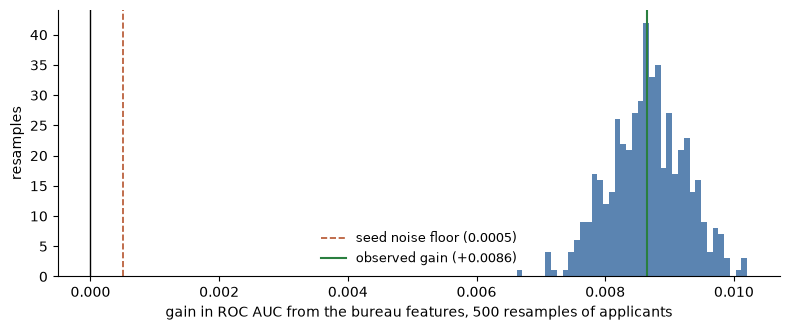

In [12]:
from scipy.stats import rankdata

def fast_auc(y, score):
    ranks = rankdata(score)
    n_pos = y.sum()
    return (ranks[y == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * (len(y) - n_pos))
assert abs(fast_auc(y_arr, baseline['oof']) - roc_auc_score(y_arr, baseline['oof'])) < 1e-12

rng = np.random.default_rng(SEED)
started = time.time()
boot = np.empty((500, 2))
for i in range(500):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    boot[i] = fast_auc(y_arr[idx], baseline['oof'][idx]), fast_auc(y_arr[idx], with_bureau['oof'][idx])
boot_gain = boot[:, 1] - boot[:, 0]
pooled_gain = roc_auc_score(y_arr, with_bureau['oof']) - roc_auc_score(y_arr, baseline['oof'])
print(f"500 resamples in {time.time() - started:.0f} seconds")
print(f"gain on all out-of-fold predictions pooled: {pooled_gain:+.5f}  (mean of the five fold gains: {GAIN:+.5f})")
print(f"95% interval for the gain: {np.quantile(boot_gain, 0.025):+.5f} to {np.quantile(boot_gain, 0.975):+.5f}; standard deviation {boot_gain.std(ddof=1):.5f}")
print(f"resamples in which the model with bureau features scores higher: {(boot_gain > 0).mean():.1%}; in which the gain exceeds the noise floor of {NOISE_FLOOR:.4f}: {(boot_gain > NOISE_FLOOR).mean():.1%}")
print(f"for comparison, each model's own ROC AUC varies with a standard deviation of {boot[:, 0].std(ddof=1):.4f} across resamples; the gain varies much less because both models are scored on the same applicants")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(boot_gain, bins=40, color='#5b84b1')
ax.axvline(0, color='black', linewidth=1)
ax.axvline(NOISE_FLOOR, color='#b5542d', linestyle='--', linewidth=1.2, label=f'seed noise floor ({NOISE_FLOOR:.4f})')
ax.axvline(pooled_gain, color='#2a7f3f', linewidth=1.5, label=f'observed gain ({pooled_gain:+.4f})')
ax.set_xlabel('gain in ROC AUC from the bureau features, 500 resamples of applicants'); ax.set_ylabel('resamples'); ax.legend(frameon=False, fontsize=9)
sns.despine(); plt.tight_layout(); plt.show()

### 3.4 What the gain means in practice

A change in the fourth decimal of ROC AUC is hard to picture. This section restates it in terms of decisions. The comparison uses only the order of the predictions, so it does not depend on calibration: each model declines the same share of applicants, the 29% it rates riskiest (the reference operating point approves 71%), and the question is how many defaults each catches.

In [13]:
def at_approval_rate(score, approve=0.71):
    declined = score >= np.quantile(score, approve)
    return {'declined_pct': declined.mean() * 100, 'defaults_caught_pct': (declined & (y_arr == 1)).sum() / y_arr.sum() * 100,
            'default_rate_among_approved_pct': y_arr[~declined].mean() * 100}

practical = {}
for approve in [0.90, 0.80, 0.71, 0.60]:
    a, b = at_approval_rate(baseline['oof'], approve), at_approval_rate(with_bureau['oof'], approve)
    practical[f'approve {approve:.0%}'] = {'defaults caught, application only (%)': a['defaults_caught_pct'], 'with bureau (%)': b['defaults_caught_pct'],
                                          'more defaults caught per 100,000 applicants': (b['defaults_caught_pct'] - a['defaults_caught_pct']) / 100 * y_arr.mean() * 100000,
                                          'default rate among approved, application only (%)': a['default_rate_among_approved_pct'], 'with bureau  (%)': b['default_rate_among_approved_pct']}
print(pd.DataFrame(practical).T.to_string(float_format=lambda v: f'{v:,.2f}'))

cut_a, cut_b = np.quantile(baseline['oof'], 0.71), np.quantile(with_bureau['oof'], 0.71)
declined_a, declined_b = baseline['oof'] >= cut_a, with_bureau['oof'] >= cut_b
moved_in, moved_out = declined_b & ~declined_a, declined_a & ~declined_b
print(f"\nat 71% approval: applicants whose decision changes {(declined_a != declined_b).mean():.1%}")
print(f"  newly declined with bureau features: {int(moved_in.sum()):,}, default rate {y_arr[moved_in].mean():.1%}")
print(f"  newly approved with bureau features: {int(moved_out.sum()):,}, default rate {y_arr[moved_out].mean():.1%}")
print(f"  (overall default rate {y_arr.mean():.1%}; among applicants declined by both {y_arr[declined_a & declined_b].mean():.1%})")
print(f"rank correlation between the two models' predictions: {pd.Series(baseline['oof']).corr(pd.Series(with_bureau['oof']), method='spearman'):.4f}  (two seeds of the same model: 0.9961)")

def lift(score):
    order = np.argsort(-score)
    tenth = len(order) // 10
    return y_arr[order[:tenth]].sum() / y_arr.sum() * 100, y_arr[order[-tenth:]].mean() * 100
(top_a, safe_a), (top_b, safe_b) = lift(baseline['oof']), lift(with_bureau['oof'])
print(f"share of all defaults in the riskiest tenth: {top_a:.2f}% -> {top_b:.2f}%; default rate in the safest tenth: {safe_a:.2f}% -> {safe_b:.2f}%")

             defaults caught, application only (%)  with bureau (%)  more defaults caught per 100,000 applicants  default rate among approved, application only (%)  with bureau  (%)
approve 90%                                  34.57            35.51                                        76.01                                               5.87              5.78
approve 80%                                  53.12            54.67                                       124.79                                               4.73              4.57
approve 71%                                  65.43            66.66                                        99.18                                               3.93              3.79
approve 60%                                  76.18            77.41                                        98.78                                               3.20              3.04

at 71% approval: applicants whose decision changes 7.4%
  newly declined with bureau feat

rank correlation between the two models' predictions: 0.9479  (two seeds of the same model: 0.9961)
share of all defaults in the riskiest tenth: 34.57% -> 35.51%; default rate in the safest tenth: 1.05% -> 1.01%


### Stage 3 findings

**The bureau features improve the model, and by more than expected**

| Fold | Application only (36) | With bureau (76) | Gain |
|---:|---:|---:|---:|
| 0 | 0.7676 | 0.7760 | +0.0083 |
| 1 | 0.7668 | 0.7759 | +0.0091 |
| 2 | 0.7682 | 0.7767 | +0.0085 |
| 3 | 0.7689 | 0.7786 | +0.0097 |
| 4 | 0.7710 | 0.7786 | +0.0076 |
| **Mean** | **0.7685** | **0.7772** | **+0.0087** |

- All four conditions fixed in advance are met. The gain is positive in every fold, 25 times its standard error, and 17 times the seed noise floor of 0.0005.
- PR AUC rises from 0.2539 to 0.2656, also in every fold.
- Nothing was tuned to the new features. The settings, the number of trees and the seed are those chosen in notebook 02 without them.

**This is larger than I predicted.** Notebooks 03 and 04 both said to expect "a real but modest gain". 0.0087 is more than the 0.0071 that fifty trials of hyperparameter tuning were worth, and nearly half of the whole distance from a plain logistic regression to the tuned model (0.018). The prediction rested on scoring one feature at a time against a fixed application model, where most features showed only 0.51 to 0.52. That measure cannot see features working together, and forty small contributions that point in different directions add up. The reasoning in notebook 03 was sound as far as it went, and its conclusion about size was wrong.

**The controls**

| Model | Gain over the application-only model | Folds better |
|---|---:|---:|
| Real bureau features, seed 42 | +0.0087 | 5 of 5 |
| Real bureau features, seed 1 | +0.0087 | 5 of 5 |
| Real bureau features, seed 2 | +0.0087 | 5 of 5 |
| Scrambled bureau features | -0.0020 | 0 of 5 |

- The gain is the same to four decimals across three seeds (0.00865 to 0.00872). It does not depend on the seed.
- Giving the model 40 columns of bureau data belonging to the wrong applicants makes it **worse** by 0.0020, in every fold. More columns alone do not help. They hurt, because the model spends some of its trees on noise. So the gain comes from the information in the features, and measured against this control it is 0.0107.
- The scrambled control is also a leak check of a kind. It has the same values, the same missing pattern and the same structure as the real features. All it lacks is the link to the applicant. If the gain had come from anything else about the table, the control would have shown it.

**Resampling applicants gives the same answer**
- Across 500 resamples of the 246,008 out-of-fold predictions, the gain has a 95% interval of 0.0076 to 0.0098.
- The model with bureau features scores higher in all 500, and beats the noise floor in all 500.
- Each model's own score varies by 0.0017 across resamples, but the gain varies by only 0.0006, because both models are scored on the same applicants each time.

**In practice**

| Approval rate | Defaults caught, application only | With bureau | More defaults caught per 100,000 applicants |
|---:|---:|---:|---:|
| 90% | 34.6% | 35.5% | 76 |
| 80% | 53.1% | 54.7% | 125 |
| 71% | 65.4% | 66.7% | 99 |
| 60% | 76.2% | 77.4% | 99 |

- At the reference approval rate of 71%, the model catches 66.7% of defaults instead of 65.4%, with the same number of applicants declined. The default rate among approved applicants falls from 3.93% to 3.79%.
- 7.4% of applicants get a different decision. The 9,085 who are newly declined default at 11.2%, and the 9,085 who are newly approved default at 8.5%. The model is swapping applicants near the line, and swapping them in the right direction.
- The two models' predictions have a rank correlation of 0.948. Two seeds of the same model agree at 0.996. So the bureau features change the ordering of applicants far more than chance does.

**Leakage check for this stage**
- The bureau features were built before the folds were looked at, from each applicant's own rows, and need no fitting. Everything that does learn from data, here only the text encoder, is inside the pipeline.
- The comparison is fold against fold on the frozen folds, with the baseline reproduced exactly in stage 2.
- The four conditions, the two controls and the noise floor were all set before this stage ran.
- Notebook 03 made three choices using development outcomes (a threshold, one feature added, two dropped). Their effect on this gain cannot be separated out here. It should be small against 0.0087, and the holdout, when it is opened for the final model, is the check.
- The holdout was not used.

**Decisions**
- The bureau features are adopted. `with_bureau` (76 features, 0.7772) is the model to carry forward.
- Stage 4 asks where the gain comes from.

## Stage 4: Where the gain comes from

The gain is 0.0087. This stage takes it apart, for three reasons. To check that the model is using the features for the reasons notebook 03 found, and not for something unexpected. To learn which of the warnings carried in from notebook 03 actually matter. And to know what to keep when the list is pruned in stage 5.

| Section | Question |
|---|---|
| 4.1 | Who is the gain for? Applicants with and without a bureau record |
| 4.2 | Which families of features carry it? Each family added alone, and each family removed |
| 4.3 | What do the features carrying warnings contribute? |
| 4.4 | How much is just knowing how many credits an applicant has? |

Every model here uses the settings of stage 3 and is scored on the same folds. Each comparison is fold against fold.

### 4.1 Who is the gain for?

The bureau features are all missing for the 14% of applicants with no bureau record, so the model cannot order those applicants any better than before. If it appears to, something is wrong.

In [14]:
def group_auc(result):
    return pd.DataFrame({label: [roc_auc_score(y_arr[m & (dev_fold == k)], result['oof'][m & (dev_fold == k)]) for k in range(N_SPLITS)] for label, m in GROUPS.items()})

a, b = group_auc(baseline), group_auc(with_bureau)
d = b - a
who = pd.DataFrame({'applicants': {label: int(m.sum()) for label, m in GROUPS.items()}, 'default_pct': {label: y_arr[m].mean() * 100 for label, m in GROUPS.items()},
                    'application_only': a.mean(), 'with_bureau': b.mean(), 'gain': d.mean(), 'standard_error': d.std(ddof=1) / np.sqrt(N_SPLITS), 'folds_better': (d > 0).sum()})
print(who.to_string(float_format=lambda v: f'{v:,.4f}'))

# the same 71% approval rate: where do the applicants whose decision changed come from?
changed = declined_a != declined_b
print(f"\nof the applicants whose decision changes at 71% approval, {has_record[changed].mean():.1%} have a bureau record (they are {has_record.mean():.1%} of all applicants)")
print(f"applicants with no record whose decision changes: {changed[~has_record].mean():.2%} of them; with a record: {changed[has_record].mean():.2%}")
no_rec_corr = pd.Series(baseline['oof'][~has_record]).corr(pd.Series(with_bureau['oof'][~has_record]), method='spearman')
print(f"rank correlation between the two models' predictions among applicants with no record: {no_rec_corr:.4f}; with a record: "
      f"{pd.Series(baseline['oof'][has_record]).corr(pd.Series(with_bureau['oof'][has_record]), method='spearman'):.4f}")

                                           applicants  default_pct  application_only  with_bureau    gain  standard_error  folds_better
all applicants                                 246008       8.0729            0.7685       0.7772  0.0086          0.0003             5
no bureau record                                35244      10.1209            0.7490       0.7462 -0.0028          0.0007             0
has a bureau record                            210764       7.7304            0.7704       0.7811  0.0107          0.0004             5
   of which: a card limit is recorded           31989      10.6130            0.7572       0.7718  0.0146          0.0008             5
   of which: was ever overdue on a credit       56178       9.4646            0.7586       0.7714  0.0127          0.0016             5
   of which: neither                           136528       6.8023            0.7723       0.7815  0.0092          0.0002             5

of the applicants whose decision changes at 71%

### 4.2 Which families carry the gain?

Two questions that have different answers, as notebook 02 found in its own ablations.

- **Added alone:** each family is added to the 36 application features without the others. This shows what a family can do by itself.
- **Removed:** each family is taken out of the full 76. This shows what the model cannot get from the other families. A family whose information is duplicated elsewhere scores well alone and costs little to remove.

The six families are those of notebook 03.

twelve models: 0.3 minutes (12 loaded from cache)

                  features  gain_when_added_alone  folds_better  share_of_full_gain_pct  change_when_removed  folds_worse  se_removed
debt and amounts        10               +0.00606             5               +70.14256             -0.00285            5    +0.00040
term                     4               +0.00252             5               +29.12255             -0.00083            5    +0.00016
recency                 10               +0.00218             5               +25.25535             -0.00073            5    +0.00015
type                     7               +0.00208             5               +24.03762             -0.00011            4    +0.00022
volume                   5               +0.00112             5               +12.99874             +0.00017            2    +0.00033
overdue                  4               +0.00054             4                +6.23091             -0.00063            4    +0.00019

full gain 

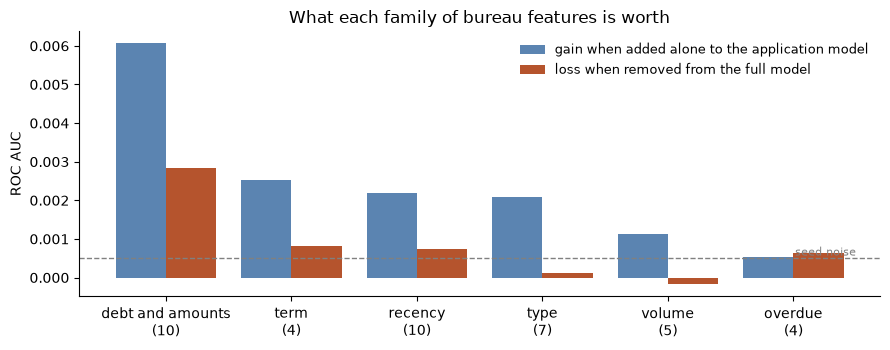

In [15]:
FAMILY = {c: bureau_meta['features'][c]['family'] for c in BUREAU}
FAMILIES = {family: [c for c in BUREAU if FAMILY[c] == family] for family in ['debt and amounts', 'overdue', 'recency', 'volume', 'type', 'term']}
assert sum(len(v) for v in FAMILIES.values()) == len(BUREAU)

started = time.time()
alone_runs = {family: run(APP_FINAL + members) for family, members in FAMILIES.items()}
without_runs = {family: run([c for c in WITH_BUREAU if c not in members]) for family, members in FAMILIES.items()}
print(f"twelve models: {(time.time() - started) / 60:.1f} minutes ({sum(r['cached'] for r in list(alone_runs.values()) + list(without_runs.values()))} loaded from cache)")

rows = {}
for family, members in FAMILIES.items():
    up, down = compare(alone_runs[family], baseline), compare(without_runs[family], with_bureau)
    rows[family] = {'features': len(members), 'gain_when_added_alone': up['mean_difference'], 'folds_better': up['folds_better'], 'share_of_full_gain_pct': up['mean_difference'] / GAIN * 100,
                    'change_when_removed': down['mean_difference'], 'folds_worse': N_SPLITS - down['folds_better'], 'se_removed': down['standard_error']}
families = pd.DataFrame(rows).T.sort_values('gain_when_added_alone', ascending=False)
print()
print(families.astype({'features': int, 'folds_better': int, 'folds_worse': int}).to_string(float_format=lambda v: f'{v:+.5f}'))
print(f"\nfull gain from all six families together: {GAIN:+.5f}")
print(f"sum of the six gains when added alone: {families['gain_when_added_alone'].sum():+.5f}  ({families['gain_when_added_alone'].sum() / GAIN:.0%} of the full gain: above 100% means the families overlap)")
print(f"sum of the six losses when removed:    {families['change_when_removed'].sum():+.5f}  ({-families['change_when_removed'].sum() / GAIN:.0%} of the full gain is unique to one family)")

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(families))
ax.bar(x - 0.2, families['gain_when_added_alone'].astype(float), 0.4, label='gain when added alone to the application model', color='#5b84b1')
ax.bar(x + 0.2, -families['change_when_removed'].astype(float), 0.4, label='loss when removed from the full model', color='#b5542d')
ax.axhline(NOISE_FLOOR, color='grey', linestyle='--', linewidth=1); ax.text(len(families) - 0.5, NOISE_FLOOR, ' seed noise', va='bottom', ha='right', fontsize=8, color='grey')
ax.set_xticks(x); ax.set_xticklabels([f"{f}\n({int(n)})" for f, n in zip(families.index, families['features'])]); ax.set_ylabel('ROC AUC'); ax.legend(frameon=False, fontsize=9)
ax.set_title('What each family of bureau features is worth')
sns.despine(); plt.tight_layout(); plt.show()

### 4.3 The features carrying warnings

Notebook 03 sent six features forward with a warning attached.

- **Two microloan counts.** Microloans are about twice as common among test applicants as among train applicants. If the model leans on them heavily, its behaviour on the test file is less certain.
- **Four date features** whose distributions differ between train and test in fine detail: time since the most recent credit, time since the first credit, time since the last update, and the longest remaining term.

Each group is removed from the full model to see what it is worth. A small loss means the warning costs little to act on. A large one means there is a real trade-off between score here and confidence on the test file.

In [16]:
MICROLOAN = [c for c in BUREAU if 'MICROLOAN' in c]
FINE_DETAIL = [c for c in BUREAU if 'warning' in bureau_meta['features'][c] and c not in MICROLOAN]
print('microloan features:', [c.replace('BUREAU_', '') for c in MICROLOAN])
print('date features with a fine-detail warning:', [c.replace('BUREAU_', '') for c in FINE_DETAIL])
assert len(MICROLOAN) == 2 and len(FINE_DETAIL) == 4

started = time.time()
warned_runs = {
    'without the 2 microloan features': run([c for c in WITH_BUREAU if c not in MICROLOAN]),
    'without the 4 date features': run([c for c in WITH_BUREAU if c not in FINE_DETAIL]),
    'without all 6': run([c for c in WITH_BUREAU if c not in MICROLOAN + FINE_DETAIL]),
}
print(f"three models: {(time.time() - started) / 60:.1f} minutes")
warned = {}
for label, r in warned_runs.items():
    against_full, against_base = compare(r, with_bureau), compare(r, baseline)
    warned[label] = {'roc_auc': r['mean']['roc_auc'], 'change_from_full_model': against_full['mean_difference'], 'standard_error': against_full['standard_error'],
                     'folds_worse': N_SPLITS - against_full['folds_better'], 'gain_over_application_only': against_base['mean_difference'],
                     'share_of_full_gain_kept_pct': against_base['mean_difference'] / GAIN * 100, 'still_meets_all_four': verdict(r)['improves']}
print()
print(pd.DataFrame(warned).T.to_string(float_format=lambda v: f'{v:+.5f}'))

# who the microloan features matter for
micro = (X_dev['BUREAU_N_MICROLOANS'] > 0).values
no_micro = warned_runs['without the 2 microloan features']['oof']
print(f"\napplicants holding a microloan: {int(micro.sum()):,} ({micro.mean():.2%}), default rate {y_arr[micro].mean():.1%}")
rank_of = lambda score: pd.Series(score).rank(pct=True).values
print(f"their average position in the risk ordering (1 = riskiest of all): application only {rank_of(baseline['oof'])[micro].mean():.3f}, "
      f"full model {rank_of(with_bureau['oof'])[micro].mean():.3f}, full model without microloan features {rank_of(no_micro)[micro].mean():.3f}")

microloan features: ['N_MICROLOANS', 'N_LIVE_MICROLOANS']
date features with a fine-detail warning: ['DAYS_SINCE_LAST_OPENED', 'DAYS_SINCE_FIRST_OPENED', 'DAYS_SINCE_LAST_UPDATE', 'LIVE_MAX_DAYS_REMAINING']


three models: 0.1 minutes

                                  roc_auc change_from_full_model standard_error folds_worse gain_over_application_only share_of_full_gain_kept_pct still_meets_all_four
without the 2 microloan features +0.77697               -0.00020       +0.00011           4                   +0.00845                   +97.72110                 True
without the 4 date features      +0.77653               -0.00064       +0.00014           5                   +0.00801                   +92.61081                 True
without all 6                    +0.77610               -0.00107       +0.00012           5                   +0.00757                   +87.60856                 True

applicants holding a microloan: 2,796 (1.14%), default rate 19.8%


their average position in the risk ordering (1 = riskiest of all): application only 0.665, full model 0.766, full model without microloan features 0.698


### 4.4 How much is just the number of credits?

Notebook 03 found that having no bureau record at all is a risk signal, and that the application model largely knows it already through a missing enquiry count. The count of credits is the one bureau feature that carries that signal. Adding it alone shows how much of the gain is this simple fact, and how much needs the content of the records.

In [17]:
started = time.time()
count_only = run(APP_FINAL + ['BUREAU_N_CREDITS'])
strongest_four = ['BUREAU_CARD_USE_OF_LIMIT', 'BUREAU_CARD_LIMIT_SUM', 'BUREAU_LIVE_LOAN_MAX_SHARE_OWED', 'BUREAU_DAYS_SINCE_LAST_OVERDUE_CREDIT_OPENED']
top_four = run(APP_FINAL + strongest_four)
print(f"two models: {(time.time() - started) / 60:.1f} minutes")
steps = {}
for label, r in {'application only (36)': baseline, 'plus the number of credits (37)': count_only,
                 "plus the four features notebook 03 ranked highest beyond the application model (40)": top_four, 'plus all 40 bureau features (76)': with_bureau}.items():
    c = compare(r, baseline)
    steps[label] = {'roc_auc': r['mean']['roc_auc'], 'gain': c['mean_difference'], 'folds_better': c['folds_better'], 'share_of_full_gain_pct': c['mean_difference'] / GAIN * 100}
print()
print(pd.DataFrame(steps).T.astype({'folds_better': int}).to_string(float_format=lambda v: f'{v:.5f}'))
print(f"\nthe four features: {[c.replace('BUREAU_', '') for c in strongest_four]}")

two models: 0.1 minutes

                                                                                     roc_auc    gain  folds_better  share_of_full_gain_pct
application only (36)                                                                0.76852 0.00000             0                 0.00000
plus the number of credits (37)                                                      0.76864 0.00012             4                 1.39081
plus the four features notebook 03 ranked highest beyond the application model (40)  0.77210 0.00357             5                41.33225
plus all 40 bureau features (76)                                                     0.77717 0.00865             5               100.00000

the four features: ['CARD_USE_OF_LIMIT', 'CARD_LIMIT_SUM', 'LIVE_LOAN_MAX_SHARE_OWED', 'DAYS_SINCE_LAST_OVERDUE_CREDIT_OPENED']


### Stage 4 findings

**The gain is for applicants with a bureau record, and it costs the others a little**

| Group | Applicants | Application only | With bureau | Gain | Folds better |
|---|---:|---:|---:|---:|---:|
| Has a bureau record | 210,764 | 0.7704 | 0.7811 | +0.0107 | 5 of 5 |
| A card limit is recorded | 31,989 | 0.7572 | 0.7718 | +0.0146 | 5 of 5 |
| Was ever overdue on a credit | 56,178 | 0.7586 | 0.7714 | +0.0127 | 5 of 5 |
| Has a record, neither of those | 136,528 | 0.7723 | 0.7815 | +0.0092 | 5 of 5 |
| **No bureau record** | 35,244 | 0.7490 | 0.7462 | **-0.0028** | **0 of 5** |

- Among applicants with a record the gain is 0.0107, larger than the headline. It is largest exactly where notebook 03 said the application model lacked information: applicants with a card limit on record (+0.0146) and those with a past overdue (+0.0127).
- Even applicants with a record and neither of those gain 0.0092. The benefit is not confined to a minority, which is part of why stage 3's gain was larger than predicted.
- **For the 14% of applicants with no bureau record, the model is slightly worse, in every fold.** All 40 bureau features are missing for them, so nothing can be gained, and something is lost. The loss is the same size as the scrambled control in stage 3 (-0.0020), and it has the same cause. Each tree is offered a random 30% of the features. With 76 features instead of 36, a tree sees fewer application features, and for these applicants the application features are all there is.
- This is a real cost, to one applicant in seven, hidden inside a better overall score. Stages 5 and 6 can reduce it, by pruning the bureau features that add little and by revisiting the share of features each tree is offered. Both stages report this group separately.
- 92% of the applicants whose decision changes have a bureau record.

**Debt carries the gain**

| Family | Features | Gain when added alone | Share of the full gain | Change when removed from the full model |
|---|---:|---:|---:|---:|
| Debt and amounts | 10 | +0.0061 | 70% | -0.0029 |
| Term | 4 | +0.0025 | 29% | -0.0008 |
| Recency | 10 | +0.0022 | 25% | -0.0007 |
| Type | 7 | +0.0021 | 24% | -0.0001 |
| Volume | 5 | +0.0011 | 13% | +0.0002 |
| Overdue | 4 | +0.0005 | 6% | -0.0006 |

- The ten debt features alone give 70% of the gain, and removing them costs three times as much as removing any other family. This is the family notebook 03 ranked first for information beyond the application model, so the model is using the table for the reason expected.
- The families overlap heavily. Added one at a time their gains sum to 168% of the full gain, and only 58% of the full gain is unique to a single family.
- **Volume can be removed at no cost** (+0.0002, better in 3 of 5 folds), and **type costs 0.0001**. Both score well alone and are fully covered by the others. These are the first candidates for pruning.
- **Overdue is the opposite.** It adds least alone (+0.0005, at the noise floor) but costs 0.0006 to remove, more than it gives alone. What it knows is not available anywhere else.
- Recency, the strongest family when features were scored one at a time in notebook 03, is third here. That matches the finding there that the external scores already hold most of it.

**The warnings cost little to act on**

| Model | ROC AUC | Change from the full model | Folds worse | Share of the gain kept |
|---|---:|---:|---:|---:|
| Without the 2 microloan features | 0.7770 | -0.0002 | 4 of 5 | 98% |
| Without the 4 flagged date features | 0.7765 | -0.0006 | 5 of 5 | 93% |
| Without all 6 | 0.7761 | -0.0011 | 5 of 5 | 88% |

- All three still meet the four conditions comfortably. The gain does not depend on the features that carry warnings.
- The microloan features are worth 0.0002 overall, which is inside the seed noise. But they matter a great deal to the 1.1% of applicants who hold a microloan, who default at 19.8%. With the microloan features the model places them at the 77th percentile of risk on average. Without, at the 70th, barely above where the application-only model put them (67th). ROC AUC hardly notices because they are so few.
- **Decision: the microloan features are kept.** The choice is between a model that sees a group defaulting at 20% and one that does not, against a risk that the relationship differs in the test file, where microloans are twice as common. That risk is a real difference between the two sets of applicants, not a difference in how the data was supplied, and notebook 02 faced the same question with `ANNUITY_TO_CREDIT`, kept it, and saw it hold on Kaggle. Stage 9 writes a submission without the microloan features as a diagnostic, as notebook 02 did.
- The four date features are worth 0.0006, a little above the noise floor and worse in all five folds. They are kept too. Their warning was mild, and the application features already in the model differ far more between the files.

**Knowing how many credits an applicant has is worth almost nothing**
- Adding the credit count alone gains 0.0001, 1% of the full gain. The application model already knew who has no bureau record.
- The four features notebook 03 ranked highest give 0.0036, 41% of the gain. The other 36 supply the remaining 59%.

**Leakage check for this stage**
- All 17 models use the stage 3 settings and the frozen folds, and each comparison is fold against fold.
- No feature list was chosen here. The ablations describe the model. The one decision, keeping the microloan features, goes against what the score alone would suggest and was made on other grounds.
- The holdout was not used.

**Decisions**
- Keep all six features that carry warnings. Write a diagnostic submission without the microloan features in stage 9.
- Carry forward to stage 5: volume and type are the families most likely to be prunable.
- Carry forward to stages 5 and 6: the loss for applicants with no bureau record, to be reported for every candidate model.

## Stage 5: Pruning

Can the list of bureau features be shortened at no cost?

A shorter list is worth having for three reasons. Fewer inputs to compute and monitor. A clearer explanation, since importance is not split between near-copies. And, specific to this model, less dilution: stage 4 found that the 40 extra columns make the model slightly worse for applicants with no bureau record, because each tree is offered fewer application features.

**The trap.** Choosing which features to keep by looking at how they score, and then reporting the score of the survivors on the same folds, flatters the result. Notebook 02 measured that inflation at 0.0005 to 0.0020. So the selection is done inside the pipeline: in each fold, the features are ranked using the training folds only, and the model is then fitted on the features that ranking kept. The validation fold plays no part in the choice. That gives an honest score for "the best *m* bureau features". Only afterwards is one fixed list drawn up, and the difference between its score and the honest one is reported.

**How features are ranked.** Inside the training folds, a quicker version of the model is fitted on 80% of the rows, and the remaining 20% is used to measure how much each bureau feature contributes to the predictions (the average size of its SHAP value). The 36 application features are always kept: they were pruned in notebook 02.

**The rule, fixed in advance.** Take the smallest number of bureau features whose honest score is within the seed noise floor (0.0005) of the full model's.

| Section | What it does |
|---|---|
| 5.1 | Rank the bureau features inside each fold, and see how stable the ranking is |
| 5.2 | The honest score for the best 30, 20, 15, 10 and 5 |
| 5.3 | A fixed list, and what fixing it flatters |
| 5.4 | Features built from both tables: debt against income |

### 5.1 Ranking inside each fold

In [18]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline

FAST_TREES, FAST_RATE = 946, 0.05              # the quicker version of the tuned model, as used for the same purpose in notebook 02, stage 8

def rank_candidates(X_encoded, y, always, candidates):
    # Ranks the candidate features using these rows only: fit on 80%, measure each feature's average contribution on the other 20%.
    y = np.asarray(y)
    grow, watch = train_test_split(np.arange(len(y)), test_size=0.20, stratify=y, random_state=SEED)
    columns = list(always) + list(candidates)
    model = lgbm_model(BEST_PARAMS, FAST_TREES, FAST_RATE).fit(X_encoded.iloc[grow][columns], y[grow])
    contributions = model.booster_.predict(X_encoded.iloc[watch][columns], pred_contrib=True)[:, :-1]
    size = pd.Series(np.abs(contributions).mean(axis=0), index=columns)
    return size[list(candidates)].sort_values(ascending=False)

class TopCandidates(BaseEstimator, TransformerMixin):
    # Keeps the 'always' columns and the best 'keep' of the 'candidates', ranked on the rows passed to fit.
    def __init__(self, always, candidates, keep):
        self.always = always
        self.candidates = candidates
        self.keep = keep
    def fit(self, X, y):
        self.ranking_ = rank_candidates(X, y, self.always, self.candidates)
        self.columns_ = list(self.always) + list(self.ranking_.index[:self.keep])
        return self
    def transform(self, X):
        return X[self.columns_]

def selecting_pipeline(keep):
    # encode the text columns, choose the bureau features on the training rows, then the model
    return Pipeline([('preprocess', Pipeline([('encode', CategoryEncoder(columns=list(TEXT_FEATURES))), ('choose', TopCandidates(APP_FINAL, BUREAU, keep))])),
                     ('model', FINAL())])

# the ranking each fold's training rows produce (the validation fold is not touched)
started = time.time()
encoder_rankings = {}
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for k in range(N_SPLITS):
        fit = dev_fold != k
        encoded = CategoryEncoder(columns=list(TEXT_FEATURES)).fit(X_dev[fit]).transform(X_dev[fit])
        encoder_rankings[k] = rank_candidates(encoded, y_arr[fit], APP_FINAL, BUREAU)
print(f"five rankings in {(time.time() - started) / 60:.1f} minutes")

size = pd.DataFrame(encoder_rankings)
ranks = size.rank(ascending=False).astype(int)
ranking = pd.DataFrame({'family': pd.Series(FAMILY), 'mean_contribution': size.mean(axis=1), 'mean_rank': ranks.mean(axis=1), 'best_rank': ranks.min(axis=1), 'worst_rank': ranks.max(axis=1),
                        'share_of_bureau_contribution_pct': size.mean(axis=1) / size.mean(axis=1).sum() * 100}).sort_values('mean_rank')
ranking.index = [c.replace('BUREAU_', '') for c in ranking.index]
ranking['cumulative_pct'] = ranking['share_of_bureau_contribution_pct'].cumsum()
print(ranking.to_string(float_format=lambda v: f'{v:.3f}'))

stability = {m: {'chosen in all five folds': int((ranks <= m).all(axis=1).sum()), 'chosen in at least one': int((ranks <= m).any(axis=1).sum()),
                 'share of bureau contribution held (%)': float(size.mean(axis=1).sort_values(ascending=False).iloc[:m].sum() / size.mean(axis=1).sum() * 100)} for m in [30, 20, 15, 10, 5]}
print('\nhow stable is the choice of the best m?')
print(pd.DataFrame(stability).T.round(1).to_string())
print(f"\nrank agreement between folds (lowest pairwise Spearman): {ranks.corr(method='spearman').values[np.triu_indices(N_SPLITS, 1)].min():.3f}")
by_family = pd.DataFrame({'features': ranking.groupby('family').size(), 'share_of_bureau_contribution_pct': ranking.groupby('family')['share_of_bureau_contribution_pct'].sum(),
                          'best_rank_in_family': ranking.groupby('family')['mean_rank'].min()}).sort_values('share_of_bureau_contribution_pct', ascending=False)
print()
print(by_family.round(1).to_string())

five rankings in 6.5 minutes
                                                 family  mean_contribution  mean_rank  best_rank  worst_rank  share_of_bureau_contribution_pct  cumulative_pct
DAYS_SINCE_LAST_CLOSED                          recency              0.059      1.600          1           3                             7.821           7.821
LIVE_MAX_DAYS_REMAINING                            term              0.053      2.200          1           4                             7.015          14.836
LIVE_LOAN_MAX_SHARE_OWED               debt and amounts              0.044      4.600          2           8                             5.827          20.663
DAYS_SINCE_LAST_OVERDUE_CREDIT_OPENED           overdue              0.044      4.600          2           9                             5.805          26.468
LIVE_DEBT_MAX                          debt and amounts              0.041      5.000          3           7                             5.502          31.971
LIVE_LOAN_SHARE_O

### 5.2 The honest score for the best *m*

Each model below chooses its bureau features inside the pipeline, on the training folds, and is then scored on the fold it has not seen. The same folds as everything else.

In [19]:
def run_pipeline(pipe):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return cross_validate(pipe, X_dev, y_arr, dev_fold, cache_dir=CACHE_DIR)

def no_record_change(result, reference):
    m = ~has_record
    d = [roc_auc_score(y_arr[m & (dev_fold == k)], result['oof'][m & (dev_fold == k)]) - roc_auc_score(y_arr[m & (dev_fold == k)], reference['oof'][m & (dev_fold == k)]) for k in range(N_SPLITS)]
    return float(np.mean(d)), int(sum(x > 0 for x in d))

M_VALUES = [30, 20, 15, 10, 5]
started = time.time()
selected_runs = {m: run_pipeline(selecting_pipeline(m)) for m in M_VALUES}
print(f"five models with selection inside the folds: {(time.time() - started) / 60:.1f} minutes")

rows = {}
for label, r in {'all 40 bureau features': with_bureau, **{f'best {m}, chosen in each fold': selected_runs[m] for m in M_VALUES}, 'no bureau features': baseline}.items():
    full, base = compare(r, with_bureau), compare(r, baseline)
    nr, nr_better = no_record_change(r, baseline)
    rows[label] = {'roc_auc': r['mean']['roc_auc'], 'change_from_all_40': full['mean_difference'], 'folds_worse': N_SPLITS - full['folds_better'] if r is not with_bureau else 0,
                   'gain_over_application_only': base['mean_difference'], 'within_noise_of_all_40': abs(full['mean_difference']) < NOISE_FLOOR or full['mean_difference'] > 0,
                   'no_record_applicants_vs_application_only': nr}
honest = pd.DataFrame(rows).T
print()
print(honest.to_string(float_format=lambda v: f'{v:+.5f}'))

eligible = [m for m in M_VALUES if honest.loc[f'best {m}, chosen in each fold', 'within_noise_of_all_40']]
M_CHOSEN = min(eligible) if eligible else 40
print(f"\nrule: the smallest number of bureau features within {NOISE_FLOOR:.4f} of the full model -> {M_CHOSEN}")

five models with selection inside the folds: 0.1 minutes



                              roc_auc change_from_all_40 folds_worse gain_over_application_only within_noise_of_all_40 no_record_applicants_vs_application_only
all 40 bureau features       +0.77717           +0.00000           0                   +0.00865                   True                                 -0.00281
best 30, chosen in each fold +0.77698           -0.00018           4                   +0.00846                   True                                 -0.00227
best 20, chosen in each fold +0.77670           -0.00047           4                   +0.00818                   True                                 -0.00151
best 15, chosen in each fold +0.77629           -0.00088           4                   +0.00777                  False                                 -0.00109
best 10, chosen in each fold +0.77567           -0.00150           5                   +0.00715                  False                                 -0.00154
best 5, chosen in each fold  +0.77303  

### 5.3 A fixed list

A saved model needs one list, not a different one per fold. The list is the best features by average rank across the five folds in section 5.1. Because it was drawn up using all the development folds, scoring it on those same folds is slightly flattering. The size of that effect is the difference between its score and the honest score in 5.2 for the same number of features.

In [20]:
order = ['BUREAU_' + c for c in ranking.index]                       # by average rank across the five folds
RULE_BUREAU = order[:M_CHOSEN]
KEPT_BUREAU = list(RULE_BUREAU)
PRUNED = APP_FINAL + KEPT_BUREAU
print(f"fixed list: {len(KEPT_BUREAU)} bureau features")
print(pd.Series({f: [c.replace('BUREAU_', '') for c in KEPT_BUREAU if FAMILY[c] == f] for f in FAMILIES}).to_string())
print(f"\ndropped: {[c.replace('BUREAU_', '') for c in order[M_CHOSEN:]]}")

started = time.time()
pruned = run(PRUNED)
print(f"\nfixed list of {len(PRUNED)} features: {'loaded from cache' if pruned['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
fixed_vs_full, fixed_vs_honest = compare(pruned, with_bureau), compare(pruned, selected_runs[M_CHOSEN]) if M_CHOSEN in selected_runs else None
nr_fixed, nr_fixed_better = no_record_change(pruned, baseline)
nr_full, _ = no_record_change(with_bureau, baseline)
summary = pd.Series({
    'all 40 bureau features (76 in total)': with_bureau['mean']['roc_auc'],
    f'best {M_CHOSEN}, chosen inside each fold (honest)': selected_runs[M_CHOSEN]['mean']['roc_auc'] if M_CHOSEN in selected_runs else np.nan,
    f'fixed list of {M_CHOSEN} ({len(PRUNED)} in total)': pruned['mean']['roc_auc'],
})
print()
print(summary.to_string(float_format=lambda v: f'{v:.5f}'))
print(f"\nfixed list against all 40: {fixed_vs_full['mean_difference']:+.5f} (standard error {fixed_vs_full['standard_error']:.5f}, better in {fixed_vs_full['folds_better']} of 5 folds)")
if fixed_vs_honest is not None:
    print(f"fixed list against the honest score for the same number: {fixed_vs_honest['mean_difference']:+.5f}  <- what fixing the list on these folds flatters")
print(f"gain over the application-only model: {compare(pruned, baseline)['mean_difference']:+.5f}; meets all four conditions: {verdict(pruned)['improves']}")
print(f"applicants with no bureau record, against the application-only model: {nr_fixed:+.5f} with the fixed list (better in {nr_fixed_better} of 5 folds), {nr_full:+.5f} with all 40")
print(f"fitting time per fold: {pruned['folds']['fit_seconds'].mean():.0f} seconds, against {with_bureau['folds']['fit_seconds'].mean():.0f} with all 40")
print(f"the warned features still in the list: {[c.replace('BUREAU_', '') for c in KEPT_BUREAU if c in MICROLOAN + FINE_DETAIL]}")

fixed list: 20 bureau features
debt and amounts    [LIVE_LOAN_MAX_SHARE_OWED, LIVE_DEBT_MAX, LIVE...
overdue                       [DAYS_SINCE_LAST_OVERDUE_CREDIT_OPENED]
recency             [DAYS_SINCE_LAST_CLOSED, DAYS_SINCE_LAST_OPENE...
volume                                       [SHARE_LIVE, N_FINISHED]
type                                                    [N_MORTGAGES]
term                [LIVE_MAX_DAYS_REMAINING, SHARE_CLOSED_EARLY, ...

dropped: ['N_CREDIT_CARDS', 'N_EVER_OVERDUE_1000_24M', 'CARD_LIMIT_SUM', 'N_CREDITS', 'LIVE_LOAN_AMOUNT_SUM', 'N_OPENED_12M', 'SHARE_CREDIT_CARDS', 'N_OPENED_24M', 'N_MICROLOANS', 'N_LIVE_NO_END_DATE', 'N_EVER_OVERDUE', 'N_LIVE_CREDIT_CARDS', 'N_LIVE', 'N_SOLD_OR_BAD', 'N_OPENED_6M', 'N_LIVE_LOANS', 'N_OPENED_3M', 'N_LIVE_MICROLOANS', 'N_OVERDUE_NOW', 'HISTORY_REACHES_WINDOW_EDGE']



fixed list of 56 features: loaded from cache



all 40 bureau features (76 in total)        0.77717
best 20, chosen inside each fold (honest)   0.77670
fixed list of 20 (56 in total)              0.77681

fixed list against all 40: -0.00036 (standard error 0.00024, better in 1 of 5 folds)
fixed list against the honest score for the same number: +0.00011  <- what fixing the list on these folds flatters
gain over the application-only model: +0.00828; meets all four conditions: True
applicants with no bureau record, against the application-only model: -0.00185 with the fixed list (better in 1 of 5 folds), -0.00281 with all 40
fitting time per fold: 27 seconds, against 43 with all 40
the warned features still in the list: ['LIVE_MAX_DAYS_REMAINING', 'DAYS_SINCE_LAST_OPENED', 'DAYS_SINCE_LAST_UPDATE', 'DAYS_SINCE_FIRST_OPENED']


### 5.3b Features that matter a great deal to a few applicants

The ranking in 5.1 orders features by their average contribution across all applicants. That is the right measure for the overall score, and the wrong one for a feature that is zero for almost everyone and decisive for the rest. Notebook 03 met the same problem in its screening, where judging by AUC alone would have removed the most informative rare-event features. Stage 4 here showed it again: the two microloan features are worth 0.0002 of ROC AUC and move the applicants who hold a microloan from the 70th to the 77th percentile of risk.

The rule in 5.2 dropped four such features: both microloan counts, the count of credits overdue now, and the count of credits sold or written off. Each is non-zero for under 2% of applicants.

**The test, fixed before running it.** Add the four back to the fixed list. If the overall score does not fall by more than the noise floor, they are kept, because for the applicants concerned the model is then better informed at no cost to anyone else. What they do for those applicants is reported alongside.

In [21]:
RARE_EVENTS = [c for c in ['BUREAU_N_MICROLOANS', 'BUREAU_N_LIVE_MICROLOANS', 'BUREAU_N_OVERDUE_NOW', 'BUREAU_N_SOLD_OR_BAD'] if c not in RULE_BUREAU]
print(f"rare-event features dropped by the rule: {[c.replace('BUREAU_', '') for c in RARE_EVENTS]}")

started = time.time()
pruned_rule = pruned
pruned_rare = run(APP_FINAL + RULE_BUREAU + RARE_EVENTS)
print(f"fixed list plus {len(RARE_EVENTS)} rare-event features: {'loaded from cache' if pruned_rare['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
rare_vs = compare(pruned_rare, pruned_rule)
print(f"ROC AUC {pruned_rule['mean']['roc_auc']:.5f} -> {pruned_rare['mean']['roc_auc']:.5f}: change {rare_vs['mean_difference']:+.5f} "
      f"(standard error {rare_vs['standard_error']:.5f}, better in {rare_vs['folds_better']} of 5 folds)")

pct = lambda score: pd.Series(score).rank(pct=True).values
positions = {}
for c in RARE_EVENTS:
    m = (X_dev[c] > 0).values
    positions[c.replace('BUREAU_', '')] = {'applicants': int(m.sum()), 'pct_of_applicants': m.mean() * 100, 'default_pct': y_arr[m].mean() * 100,
                                           'application only': pct(baseline['oof'])[m].mean(), 'rule list (without)': pct(pruned_rule['oof'])[m].mean(),
                                           'rule list plus the four': pct(pruned_rare['oof'])[m].mean(), 'all 40': pct(with_bureau['oof'])[m].mean()}
print('\napplicants with the event: their average position in the risk ordering under each model (1 = riskiest of all)')
print(pd.DataFrame(positions).T.to_string(float_format=lambda v: f'{v:,.3f}'))

any_event = (X_dev[RARE_EVENTS] > 0).any(axis=1).values
auc_in = lambda r, m: float(np.mean([roc_auc_score(y_arr[m & (dev_fold == k)], r['oof'][m & (dev_fold == k)]) for k in range(N_SPLITS)]))
print(f"\napplicants with at least one of the four events: {int(any_event.sum()):,} ({any_event.mean():.2%}), default rate {y_arr[any_event].mean():.1%}")
print(f"ROC AUC within that group: {auc_in(pruned_rule, any_event):.4f} without the four, {auc_in(pruned_rare, any_event):.4f} with them")
print(f"share of that group declined at 71% approval: {(pruned_rule['oof'] >= np.quantile(pruned_rule['oof'], 0.71))[any_event].mean():.1%} without, "
      f"{(pruned_rare['oof'] >= np.quantile(pruned_rare['oof'], 0.71))[any_event].mean():.1%} with")

ADD_RARE = bool(rare_vs['mean_difference'] > -NOISE_FLOOR)
print(f"\ntest: the overall score does not fall by more than {NOISE_FLOOR:.4f} -> {'the four are kept' if ADD_RARE else 'the four stay out'}")
if ADD_RARE:
    KEPT_BUREAU = RULE_BUREAU + RARE_EVENTS
    PRUNED, pruned = APP_FINAL + KEPT_BUREAU, pruned_rare
print(f"fixed list now: {len(KEPT_BUREAU)} bureau features, {len(PRUNED)} in total; ROC AUC {pruned['mean']['roc_auc']:.5f}; "
      f"against all 40: {compare(pruned, with_bureau)['mean_difference']:+.5f}; against the application-only model: {compare(pruned, baseline)['mean_difference']:+.5f}")
nr_now, nr_now_better = no_record_change(pruned, baseline)
print(f"applicants with no bureau record, against the application-only model: {nr_now:+.5f} (better in {nr_now_better} of 5 folds)")

rare-event features dropped by the rule: ['N_MICROLOANS', 'N_LIVE_MICROLOANS', 'N_OVERDUE_NOW', 'N_SOLD_OR_BAD']


fixed list plus 4 rare-event features: loaded from cache
ROC AUC 0.77681 -> 0.77737: change +0.00056 (standard error 0.00025, better in 5 of 5 folds)



applicants with the event: their average position in the risk ordering under each model (1 = riskiest of all)
                   applicants  pct_of_applicants  default_pct  application only  rule list (without)  rule list plus the four  all 40
N_MICROLOANS        2,796.000              1.137       19.850             0.665                0.693                    0.772   0.766
N_LIVE_MICROLOANS   1,423.000              0.578       23.963             0.683                0.746                    0.834   0.828
N_OVERDUE_NOW       2,868.000              1.166       15.411             0.680                0.663                    0.684   0.681
N_SOLD_OR_BAD       4,195.000              1.705       10.226             0.533                0.517                    0.552   0.550

applicants with at least one of the four events: 9,526 (3.87%), default rate 14.4%
ROC AUC within that group: 0.7780 without the four, 0.7791 with them
share of that group declined at 71% approval: 44.7% without, 50.8%

### 5.4 Debt against income

Notebook 03 left one idea for this notebook: bureau amounts mean more beside the applicant's income, which is in the application table. A debt of 500,000 is a different thing on an income of 100,000 than on an income of 1,000,000. Each ratio below is computed from the applicant's own row, so nothing is fitted and nothing crosses between applicants.

The saved bureau table has the largest single live debt, not the total (the total was dropped as a near-copy in notebook 03, stage 8), so the largest is used.

In [22]:
X_cross = X_dev.copy()                                   # X_dev itself is left as it is, so earlier results stay comparable
income = X_cross['AMT_INCOME_TOTAL']
X_cross['CROSS_LIVE_DEBT_TO_INCOME'] = X_cross['BUREAU_LIVE_DEBT_MAX'] / income
X_cross['CROSS_LIVE_LOAN_AMOUNT_TO_INCOME'] = X_cross['BUREAU_LIVE_LOAN_AMOUNT_SUM'] / income
X_cross['CROSS_CARD_LIMIT_TO_INCOME'] = X_cross['BUREAU_CARD_LIMIT_SUM'] / income
X_cross['CROSS_NEW_CREDIT_TO_LARGEST_PAST_CREDIT'] = X_cross['AMT_CREDIT'] / X_cross['BUREAU_AMOUNT_MAX'].where(X_cross['BUREAU_AMOUNT_MAX'] > 0)
CROSS = [c for c in X_cross.columns if c.startswith('CROSS_')]
assert not np.isinf(X_cross[CROSS].to_numpy()).any() and (income.dropna() > 0).all()
print(f"income is missing for {int(income.isna().sum())} applicants (values above 20 million were set to missing in notebook 01); the ratios are missing for them")

alone_cross = {}
for c in CROSS:
    ok = X_cross[c].notna().values
    a = roc_auc_score(y_arr[ok], X_cross[c].values[ok])
    alone_cross[c.replace('CROSS_', '')] = {'has_a_value_pct': ok.mean() * 100, 'auc_alone': max(a, 1 - a), 'higher_value_means': 'more risk' if a > 0.5 else 'less risk'}
print(pd.DataFrame(alone_cross).T.to_string(float_format=lambda v: f'{v:.4f}'))

started = time.time()
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    with_cross = cross_validate(make_pipeline(PRUNED + CROSS, TEXT_FEATURES, FINAL()), X_cross, y_arr, dev_fold, cache_dir=CACHE_DIR)
print(f"\nfixed list plus the four ratios ({len(PRUNED) + len(CROSS)} features): {'loaded from cache' if with_cross['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
cross_vs = compare(with_cross, pruned)
print(f"ROC AUC {pruned['mean']['roc_auc']:.5f} -> {with_cross['mean']['roc_auc']:.5f}: change {cross_vs['mean_difference']:+.5f} (standard error {cross_vs['standard_error']:.5f}, better in {cross_vs['folds_better']} of 5 folds)")
cross_verdict = verdict(with_cross, pruned)
ADD_CROSS = bool(cross_verdict['improves'])
print(f"meets all four conditions against the fixed list: {ADD_CROSS}")
for name, ok in cross_verdict['conditions'].items():
    print(f"  {'MET    ' if ok else 'NOT MET'}  {name}")
if ADD_CROSS:
    X_dev = X_cross
X_cross = None
CHOSEN_FEATURES = PRUNED + CROSS if ADD_CROSS else PRUNED
chosen = with_cross if ADD_CROSS else pruned
nr_chosen, nr_chosen_better = no_record_change(chosen, baseline)
print(f"\nfeature list carried forward: {len(CHOSEN_FEATURES)} features ({len(APP_FINAL)} application, {len(KEPT_BUREAU)} bureau, {len(CROSS) if ADD_CROSS else 0} built from both)")
print(f"its ROC AUC: {chosen['mean']['roc_auc']:.5f}; gain over the application-only model {compare(chosen, baseline)['mean_difference']:+.5f}; "
      f"applicants with no bureau record {nr_chosen:+.5f} against the application-only model")

income is missing for 1 applicants (values above 20 million were set to missing in notebook 01); the ratios are missing for them


                                  has_a_value_pct auc_alone higher_value_means
LIVE_DEBT_TO_INCOME                       63.7130    0.5274          more risk
LIVE_LOAN_AMOUNT_TO_INCOME                48.8797    0.5116          less risk
CARD_LIMIT_TO_INCOME                      13.0032    0.6109          less risk
NEW_CREDIT_TO_LARGEST_PAST_CREDIT         85.3098    0.5087          more risk



fixed list plus the four ratios (64 features): loaded from cache
ROC AUC 0.77737 -> 0.77703: change -0.00034 (standard error 0.00017, better in 1 of 5 folds)
meets all four conditions against the fixed list: False
  NOT MET  1. mean ROC AUC is higher
  NOT MET  2. higher in at least four of five folds
  NOT MET  3. gain is more than twice its standard error
  NOT MET  4. gain exceeds the seed noise floor of 0.0005

feature list carried forward: 60 features (36 application, 24 bureau, 0 built from both)
its ROC AUC: 0.77737; gain over the application-only model +0.00884; applicants with no bureau record -0.00202 against the application-only model


### Stage 5 findings

**The list carried forward: 60 features, scoring 0.7774**

| Model | Features | ROC AUC | Gain over application only |
|---|---:|---:|---:|
| Application only | 36 | 0.7685 | |
| All 40 bureau features | 76 | 0.7772 | +0.0087 |
| Best 20 by the rule | 56 | 0.7768 | +0.0083 |
| **Best 20 plus four rare-event features** | **60** | **0.7774** | **+0.0088** |

- Sixteen bureau features were removed and the score is, if anything, slightly higher than with all 40 (+0.0002, inside the noise).
- The 24 kept: 8 on debt and amounts, 5 on recency, 3 each on type, term and volume, and 2 on overdue. The list is printed in sections 5.3 and 5.3b and stored in `KEPT_BUREAU`.

**The ranking, and how stable it is**
- The features that contribute most on average are time since the last closed credit, the longest remaining term on a live credit, the most heavily owed loan, and time since an overdue credit was opened. None of the top four is a count.
- The top of the ranking is steady across folds: the first seven features are in every fold's top ten. Lower down it is not. For a list of 20, 14 features are chosen in all five folds and 26 in at least one.
- The 20 best hold 82% of the total contribution of the bureau features, and the 30 best hold 96%.

**The honest score for each size**

| Bureau features, chosen inside each fold | ROC AUC | Change from all 40 | Folds worse |
|---:|---:|---:|---:|
| 30 | 0.7770 | -0.0002 | 4 of 5 |
| 20 | 0.7767 | -0.0005 | 4 of 5 |
| 15 | 0.7763 | -0.0009 | 4 of 5 |
| 10 | 0.7757 | -0.0015 | 5 of 5 |
| 5 | 0.7730 | -0.0041 | 5 of 5 |

- The rule took 20, the smallest number within the noise floor. It was a close call: the loss is 0.00047 against a limit of 0.0005.
- Even five bureau features, chosen in each fold, keep more than half of the gain (0.0045 of 0.0087).
- A fixed list of 20 scores 0.7768, which is 0.0001 above the honest score for 20. That is what fixing the list on these folds flatters, and it is small.

**The ranking misjudged the rare-event features, and the test showed it**

| Feature | Applicants with the event | Their default rate | Average risk percentile without the four | With the four |
|---|---:|---:|---:|---:|
| Microloans | 1.1% | 19.9% | 69th | 77th |
| Live microloans | 0.6% | 24.0% | 75th | 83rd |
| Credits overdue now | 1.2% | 15.4% | 66th | 68th |
| Sold or bad debt | 1.7% | 10.2% | 52nd | 55th |

- The ranking placed these four between 29th and 38th of 40, because they are zero for almost everyone.
- Added back to the list of 20, they raise the score by 0.00056, in all five folds. The test asked only that they not lower it.
- So they were not merely harmless. Four features that the ranking would have discarded are worth more than the sixteen it discards correctly. Average contribution is a poor guide for a feature that is rarely non-zero, which is the third time this project has met that fact (notebook 03, stage 8, and stage 4 here).
- Among the 3.9% of applicants with at least one of these events, who default at 14.4%, the share declined at the reference approval rate rises from 45% to 51%.
- Stage 4 put the microloan features at 0.0002 when removed from the full 76. Here they and two others are worth 0.0006 when added to a list of 56. The two measurements differ because of what else is in the model: the full list holds other features that partly stand in for them.

**Debt against income does not help**
- Four ratios built from both tables were added to the 60: live debt, live loan amounts and card limits each divided by income, and the new loan against the largest past credit.
- The score fell by 0.0003, worse in 4 of 5 folds. None of the four conditions is met.
- Notebook 03 had suggested this on the strength of one ratio scoring 0.536 alone against 0.529 for the raw amount. A tree model with both the debt and the income in front of it can already compare them, and four more columns cost more than they add. The ratios are not used.

**Applicants with no bureau record**
- Against the application-only model they lose 0.0020 with the 60-feature list, against 0.0028 with all 76. Pruning recovered about a third of the loss.
- The loss is still there in 4 of 5 folds. Stage 6 looks at whether the share of features offered to each tree should change now that the list is longer.

**Leakage check for this stage**
- The scores for the best 30, 20, 15, 10 and 5 come from selection done inside the pipeline, on training folds only.
- Three choices were then made on the development folds as a whole: the size (20), the fixed list, and adding back four features. The first followed a rule fixed in advance and the third a test fixed in advance. The measured flattery of fixing the list is 0.0001.
- The cumulative effect of choices made on these folds, here and in notebook 03, is not zero. It is the reason the holdout is kept closed for one final check.
- The holdout was not used.

**Decisions**
- `CHOSEN_FEATURES`: 36 application and 24 bureau features. `chosen` is its result on the folds (0.7774).
- The four income ratios are dropped.
- Stage 6 re-tunes the settings on this list.

## Stage 6: Re-tuning

Do the best settings move now that there are more features?

The settings in use were found in notebook 02 by searching with 55 application features. The list is now 60 features of a different kind, and two settings in particular might want to change. The share of features offered to each tree (30%) was chosen when there were no bureau columns, and stage 4 traced the loss for applicants with no bureau record to it. And the number of trees was set for a model with less to learn.

**The risk in tuning again.** A search tries many settings and reports the best. The best of thirty is partly the best by luck, and its score on the folds it was chosen on overstates it. Notebook 02 found that its two searches reached the same score by different routes, which suggested the score was a property of the data and not of the settings. So the bar for changing anything here is deliberately high.

**The rule, fixed in advance.** The current settings stay unless new ones beat them twice: once in the search, and again when the winner is refitted with the final learning rate and tree count. Each time, all four conditions from stage 2 must be met, against the current settings on the same folds.

**How the search works** (the same protocol as notebook 02's corrected search):
- Learning rate 0.05 with early stopping, to make each trial quick.
- Early stopping watches ROC AUC on 15% of the training folds, set aside inside them. The validation fold plays no part in deciding when to stop.
- 30 trials. The first is the current settings, so that everything else is compared with them under identical conditions.

| Section | What it does |
|---|---|
| 6.1 | The search |
| 6.2 | The winner against the current settings, and the rule |
| 6.3 | The number of trees |
| 6.4 | The model carried forward |

### 6.1 The search

In [23]:
import lightgbm as lgb
import joblib
warnings.filterwarnings('ignore', message='IProgress not found')
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS, SEARCH_RATE, MAX_TREES, PATIENCE = 30, 0.05, 3000, 100
SEARCH_DIR = CACHE_DIR / 'search'
SEARCH_DIR.mkdir(parents=True, exist_ok=True)

# The text encoding depends only on the training folds, so it is done once per fold and reused by every trial.
# Inside each training fold, 15% of the rows are set aside to decide when to stop adding trees.
fold_data = []
for k in range(N_SPLITS):
    fit, val = dev_fold != k, dev_fold == k
    encoder = CategoryEncoder(columns=list(TEXT_FEATURES)).fit(X_dev[fit])
    X_fit, X_val = encoder.transform(X_dev[fit])[CHOSEN_FEATURES], encoder.transform(X_dev[val])[CHOSEN_FEATURES]
    grow, watch = train_test_split(np.arange(int(fit.sum())), test_size=0.15, stratify=y_arr[fit], random_state=SEED)
    fold_data.append({'X_fit': X_fit, 'y_fit': y_arr[fit], 'X_val': X_val, 'y_val': y_arr[val], 'grow': grow, 'watch': watch, 'val_rows': val})

def search_trial(params):
    # five-fold score of one group of settings, with early stopping inside the training folds. Saved to disk.
    key = hashlib.md5(json.dumps({'params': {k: repr(v) for k, v in sorted(params.items())}, 'features': CHOSEN_FEATURES, 'protocol': [SEARCH_RATE, MAX_TREES, PATIENCE, SEED],
                                  'versions': [lightgbm.__version__, sklearn.__version__]}, sort_keys=True).encode()).hexdigest()
    path = SEARCH_DIR / f'{key}.joblib'
    if path.exists():
        return joblib.load(path)
    aucs, rounds, seconds, oof = [], [], [], np.zeros(len(y_arr))
    for d in fold_data:
        model = lgbm_model(params, MAX_TREES, SEARCH_RATE).set_params(metric='auc', first_metric_only=True)
        started = time.time()
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            model.fit(d['X_fit'].iloc[d['grow']], d['y_fit'][d['grow']], eval_set=[(d['X_fit'].iloc[d['watch']], d['y_fit'][d['watch']])], eval_metric='auc',
                      callbacks=[lgb.early_stopping(PATIENCE, verbose=False)])
            prediction = model.predict_proba(d['X_val'])[:, 1]
        seconds.append(time.time() - started)
        oof[d['val_rows']] = prediction
        aucs.append(roc_auc_score(d['y_val'], prediction))
        rounds.append(int(model.best_iteration_))
    result = {'folds': aucs, 'rounds': rounds, 'seconds': float(np.sum(seconds)), 'oof': oof}
    joblib.dump(result, path, compress=3)
    return result

def suggest(trial):
    # the search space of notebook 02
    return {'num_leaves': trial.suggest_int('num_leaves', 8, 128, log=True), 'max_depth': trial.suggest_int('max_depth', 3, 12),
            'min_child_samples': trial.suggest_int('min_child_samples', 20, 1000, log=True), 'colsample_bytree': trial.suggest_float('colsample_bytree', 0.3, 1.0),
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True), 'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 100.0, log=True),
            'min_split_gain': trial.suggest_float('min_split_gain', 0.0, 0.5), 'cat_smooth': trial.suggest_float('cat_smooth', 1.0, 100.0, log=True),
            'neg_bagging_fraction': trial.suggest_float('neg_bagging_fraction', 0.1, 1.0), 'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, 5.0)}

trial_results = {}
def objective(trial):
    params = suggest(trial)
    r = search_trial(params)
    trial_results[trial.number] = {**r, 'params': params}
    return float(np.mean(r['folds']))

started = time.time()
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study.enqueue_trial(BEST_PARAMS)                           # trial 0: the settings in use
study.optimize(objective, n_trials=N_TRIALS)
typical_minutes = float(np.median([r['seconds'] for r in trial_results.values()])) / 60          # the median, so a trial interrupted by the computer sleeping does not distort it
print(f"{N_TRIALS} trials loaded or fitted in {(time.time() - started) / 60:.1f} minutes; a typical trial takes {typical_minutes:.1f} minutes to fit, about {typical_minutes * N_TRIALS:.0f} minutes for the search")

trials = pd.DataFrame({n: {'roc_auc': np.mean(r['folds']), 'fold_sd': np.std(r['folds'], ddof=1), 'mean_rounds': np.mean(r['rounds']), **r['params']} for n, r in trial_results.items()}).T
trials.index.name = 'trial'
current = trial_results[0]
assert all(abs(current['params'][k] - BEST_PARAMS[k]) < 1e-12 for k in BEST_PARAMS), 'trial 0 must be the settings in use'
print(f"\ntrial 0, the current settings under this protocol: ROC AUC {np.mean(current['folds']):.5f}, stopping after {np.mean(current['rounds']):.0f} trees on average (folds {current['rounds']})")
print(f"trials that beat the current settings: {int((trials['roc_auc'] > trials.loc[0, 'roc_auc']).sum())} of {N_TRIALS - 1}; best {trials['roc_auc'].max():.5f}, worst {trials['roc_auc'].min():.5f}")
print('\nthe ten best trials:')
print(trials.sort_values('roc_auc', ascending=False).head(10).to_string(float_format=lambda v: f'{v:.4f}'))

30 trials loaded or fitted in 0.0 minutes; a typical trial takes 1.1 minutes to fit, about 34 minutes for the search

trial 0, the current settings under this protocol: ROC AUC 0.77560, stopping after 1004 trees on average (folds [1124, 1170, 967, 783, 978])
trials that beat the current settings: 0 of 29; best 0.77560, worst 0.77013

the ten best trials:
       roc_auc  fold_sd  mean_rounds  num_leaves  max_depth  min_child_samples  colsample_bytree  reg_alpha  reg_lambda  min_split_gain  cat_smooth  neg_bagging_fraction  scale_pos_weight
trial                                                                                                                                                                                      
0       0.7756   0.0016    1004.4000     10.0000    10.0000           803.0000            0.3019     0.0048      0.4351          0.0095     24.2843                0.6151            1.2018
27      0.7756   0.0018    1215.6000      9.0000    10.0000           514.0000 

### 6.2 The winner against the current settings

In [24]:
best_number = int(trials['roc_auc'].astype(float).idxmax())
best = trial_results[best_number]
fold_table = pd.DataFrame({'current settings (trial 0)': current['folds'], f'best trial ({best_number})': best['folds']})
fold_table['difference'] = fold_table.iloc[:, 1] - fold_table.iloc[:, 0]
fold_table.index.name = 'fold'
print(fold_table.to_string(float_format=lambda v: f'{v:.5f}'))

d = fold_table['difference']
se = d.std(ddof=1) / np.sqrt(len(d))
search_conditions = {'1. mean ROC AUC is higher': d.mean() > 0, '2. higher in at least four of five folds': int((d > 0).sum()) >= 4,
                     '3. gain is more than twice its standard error': d.mean() > 0 and d.mean() / se > 2, f'4. gain exceeds the seed noise floor of {NOISE_FLOOR:.4f}': d.mean() > NOISE_FLOOR}
print(f"\nbest trial against the current settings: {d.mean():+.5f} (standard error {se:.5f}, better in {int((d > 0).sum())} of 5 folds)")
for name, ok in search_conditions.items():
    print(f"  {'MET    ' if ok else 'NOT MET'}  {name}")
PASSED_SEARCH = all(search_conditions.values())

compare_settings = pd.DataFrame({'current': current['params'], 'best trial': best['params']})
compare_settings['ten best trials: lowest'] = trials.sort_values('roc_auc', ascending=False).head(10)[list(BEST_PARAMS)].min()
compare_settings['ten best trials: highest'] = trials.sort_values('roc_auc', ascending=False).head(10)[list(BEST_PARAMS)].max()
print()
print(compare_settings.to_string(float_format=lambda v: f'{v:.4f}'))
print(f"\nwhich settings the score depended on in this search (share of the variation explained):")
print(pd.Series(optuna.importance.get_param_importances(study)).round(3).to_string())

near = trials[trials['roc_auc'] >= trials.loc[0, 'roc_auc'] - NOISE_FLOOR]
print(f"\ntrials within the noise floor of the current settings, or better: {len(near)} of {N_TRIALS}")
print(f"spread of the ten best trials: {trials['roc_auc'].nlargest(10).max() - trials['roc_auc'].nlargest(10).min():.5f}")
print(f"\nfirst test of the rule (the search): {'PASSED, the winner goes on to the second test' if PASSED_SEARCH else 'NOT PASSED, the current settings are kept'}")

      current settings (trial 0)  best trial (0)  difference
fold                                                        
0                        0.77440         0.77440     0.00000
1                        0.77454         0.77454     0.00000
2                        0.77458         0.77458     0.00000
3                        0.77794         0.77794     0.00000
4                        0.77654         0.77654     0.00000

best trial against the current settings: +0.00000 (standard error 0.00000, better in 0 of 5 folds)
  NOT MET  1. mean ROC AUC is higher
  NOT MET  2. higher in at least four of five folds
  NOT MET  3. gain is more than twice its standard error
  NOT MET  4. gain exceeds the seed noise floor of 0.0005

                      current  best trial  ten best trials: lowest  ten best trials: highest
num_leaves            10.0000     10.0000                   8.0000                   14.0000
max_depth             10.0000     10.0000                   7.0000                

reg_lambda              0.595
colsample_bytree        0.193
reg_alpha               0.050
max_depth               0.046
scale_pos_weight        0.039
num_leaves              0.022
min_split_gain          0.021
neg_bagging_fraction    0.015
cat_smooth              0.013
min_child_samples       0.006

trials within the noise floor of the current settings, or better: 10 of 30
spread of the ten best trials: 0.00049

first test of the rule (the search): NOT PASSED, the current settings are kept


### 6.3 The number of trees

Separately from the search: the model uses 2,365 trees at a learning rate of 0.02, a number set in notebook 02. With more features it might want more, or fewer. This is checked directly. For each fold a model is grown to 4,000 trees on the training folds, and its score on the validation fold is read off at several points along the way. A model with 4,000 trees contains the model with 2,365 as its first 2,365, so one fit per fold gives the whole curve.

The settings used are the ones still standing after 6.2.

In [25]:
CANDIDATE_PARAMS = dict(best['params']) if PASSED_SEARCH else dict(BEST_PARAMS)
CHECKPOINTS = [1000, 1500, 2000, 2365, 2750, 3000, 3500, 4000]
curve_path = SEARCH_DIR / f"trees_{hashlib.md5(json.dumps({'p': {k: repr(v) for k, v in sorted(CANDIDATE_PARAMS.items())}, 'f': CHOSEN_FEATURES, 'c': CHECKPOINTS}, sort_keys=True).encode()).hexdigest()}.joblib"
started = time.time()
if curve_path.exists():
    curve = joblib.load(curve_path)
else:
    curve = {}
    for k, d in enumerate(fold_data):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            model = lgbm_model(CANDIDATE_PARAMS, max(CHECKPOINTS), LEARNING_RATE).fit(d['X_fit'], d['y_fit'])       # all training-fold rows, as the final model uses
            curve[k] = {n: roc_auc_score(d['y_val'], model.predict_proba(d['X_val'], num_iteration=n)[:, 1]) for n in CHECKPOINTS}
    joblib.dump(curve, curve_path)
print(f"tree curve: {(time.time() - started) / 60:.1f} minutes")
curve = pd.DataFrame(curve)
curve.columns = [f'fold {k}' for k in curve.columns]
curve['mean'] = curve.mean(axis=1)
curve['against 2,365'] = curve['mean'] - curve.loc[2365, 'mean']
curve['folds better than 2,365'] = [(curve.loc[n, [f'fold {k}' for k in range(N_SPLITS)]] > curve.loc[2365, [f'fold {k}' for k in range(N_SPLITS)]]).sum() for n in curve.index]
curve.index.name = 'trees'
print(curve.to_string(float_format=lambda v: f'{v:.5f}'))
best_count = int(curve['mean'].idxmax())
tree_gain = float(curve.loc[best_count, 'against 2,365'])
N_TREES_FINAL = best_count if (tree_gain > NOISE_FLOOR and curve.loc[best_count, 'folds better than 2,365'] >= 4) else N_TREES
print(f"\nbest point on the curve: {best_count:,} trees, {tree_gain:+.5f} against 2,365")
print(f"rule: change the number only if the gain exceeds the noise floor of {NOISE_FLOOR:.4f} in at least four folds -> {N_TREES_FINAL:,} trees")
if not PASSED_SEARCH:
    print(f"check: the curve's value at 2,365 trees ({curve.loc[2365, 'mean']:.5f}) equals the stage 5 result ({chosen['mean']['roc_auc']:.5f}): {abs(curve.loc[2365, 'mean'] - chosen['mean']['roc_auc']) < 1e-9}")

tree curve: 0.0 minutes
       fold 0  fold 1  fold 2  fold 3  fold 4    mean  against 2,365  folds better than 2,365
trees                                                                                        
1000  0.77277 0.77198 0.77250 0.77626 0.77575 0.77385       -0.00351                        0
1500  0.77476 0.77393 0.77523 0.77796 0.77783 0.77594       -0.00142                        0
2000  0.77565 0.77493 0.77640 0.77894 0.77888 0.77696       -0.00041                        0
2365  0.77594 0.77520 0.77711 0.77932 0.77926 0.77737        0.00000                        0
2750  0.77602 0.77550 0.77771 0.77949 0.77955 0.77765        0.00029                        5
3000  0.77624 0.77561 0.77789 0.77958 0.77949 0.77776        0.00039                        5
3500  0.77648 0.77557 0.77828 0.77959 0.77958 0.77790        0.00053                        5
4000  0.77643 0.77530 0.77826 0.77945 0.77947 0.77778        0.00042                        5

best point on the curve: 3,500 tree

### 6.4 The model carried forward

In [26]:
def TUNED():
    return lgbm_model(CANDIDATE_PARAMS, N_TREES_FINAL, LEARNING_RATE)

SETTINGS_CHANGED, TREES_CHANGED = bool(PASSED_SEARCH), N_TREES_FINAL != N_TREES
if SETTINGS_CHANGED or TREES_CHANGED:
    started = time.time()
    candidate = run(CHOSEN_FEATURES, model=TUNED())
    print(f"candidate at the final learning rate, {N_TREES_FINAL:,} trees: {'loaded from cache' if candidate['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
    second = verdict(candidate, chosen)
    print(f"against the stage 5 model on the same features: {second['mean_difference']:+.5f} (standard error {second['standard_error']:.5f}, better in {second['folds_better']} of 5 folds)")
    for name, ok in second['conditions'].items():
        print(f"  {'MET    ' if ok else 'NOT MET'}  {name}")
    if SETTINGS_CHANGED:
        ADOPT = bool(second['improves'])
        print(f"second test of the rule for new settings: {'PASSED' if ADOPT else 'NOT PASSED'}")
    else:
        ADOPT = bool(second['improves'])
        print('The settings did not change, only the number of trees. That number was read off the curve in 6.3, which was measured on these same folds,')
        print(f"so this refit reproduces the curve's value ({curve.loc[N_TREES_FINAL, 'mean']:.5f}) and is not an independent test. It confirms the pipeline gives the same result as the curve: "
              f"{abs(candidate['mean']['roc_auc'] - curve.loc[N_TREES_FINAL, 'mean']) < 1e-9}")
else:
    ADOPT = False
    print('nothing changed, so there is no candidate to refit')

if ADOPT:
    FINAL_PARAMS, FINAL_TREES, final_run = dict(CANDIDATE_PARAMS), N_TREES_FINAL, candidate
else:
    FINAL_PARAMS, FINAL_TREES, final_run = dict(BEST_PARAMS), N_TREES, chosen

def MODEL():
    # the model carried forward from this stage, unfitted
    return lgbm_model(FINAL_PARAMS, FINAL_TREES, LEARNING_RATE)

print(f"\ncarried forward: settings {'from this search' if (ADOPT and SETTINGS_CHANGED) else 'unchanged from notebook 02'}; "
      f"{FINAL_TREES:,} trees ({'changed from' if FINAL_TREES != N_TREES else 'as in'} notebook 02's {N_TREES:,}) at learning rate {LEARNING_RATE}")
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL_PARAMS.items()})

# Like with like: would the application-only model also score higher with this many trees? If so, that part is not a gain from the bureau features.
started = time.time()
baseline_same_trees = run(APP_FINAL, model=lgbm_model(BEST_PARAMS, FINAL_TREES, LEARNING_RATE)) if FINAL_TREES != N_TREES else baseline
tree_effect_on_baseline = compare(baseline_same_trees, baseline)
print(f"\napplication-only model with {FINAL_TREES:,} trees: ROC AUC {baseline_same_trees['mean']['roc_auc']:.5f} against {baseline['mean']['roc_auc']:.5f} with {N_TREES:,} "
      f"({tree_effect_on_baseline['mean_difference']:+.5f}, better in {tree_effect_on_baseline['folds_better']} of 5 folds)")
like_for_like = compare(final_run, baseline_same_trees)
print(f"gain from the bureau features with both models at {FINAL_TREES:,} trees: {like_for_like['mean_difference']:+.5f} (standard error {like_for_like['standard_error']:.5f}, better in {like_for_like['folds_better']} of 5 folds)")
print(f"gain from the bureau features with both models at {N_TREES:,} trees:   {compare(chosen, baseline)['mean_difference']:+.5f}")

summary = pd.DataFrame({label: {'features': n, 'trees': trees, 'roc_auc': r['mean']['roc_auc'], 'pr_auc': r['mean']['pr_auc'], 'gain_over_application_only': compare(r, baseline)['mean_difference'],
                                'no_record_applicants_vs_application_only': no_record_change(r, baseline)[0], 'seconds_per_fold': r['folds']['fit_seconds'].mean()}
                        for label, n, trees, r in [('application only', 36, N_TREES, baseline), ('all 40 bureau features', 76, N_TREES, with_bureau),
                                                   ('pruned list (stage 5)', len(CHOSEN_FEATURES), N_TREES, chosen), ('carried forward', len(CHOSEN_FEATURES), FINAL_TREES, final_run)]}).T
print()
print(summary.astype({'features': int, 'trees': int}).to_string(float_format=lambda v: f'{v:.5f}'))
print(f"\nthe model carried forward meets all four conditions against the application-only model: {verdict(final_run)['improves']}")
nr_final, nr_final_better = no_record_change(final_run, baseline)
nr_same_trees, _ = no_record_change(final_run, baseline_same_trees)
print(f"applicants with no bureau record: {nr_final:+.5f} against the application-only model (better in {nr_final_better} of 5 folds); {nr_same_trees:+.5f} against the application-only model with the same number of trees")

candidate at the final learning rate, 3,500 trees: loaded from cache
against the stage 5 model on the same features: +0.00053 (standard error 0.00016, better in 5 of 5 folds)
  MET      1. mean ROC AUC is higher
  MET      2. higher in at least four of five folds
  MET      3. gain is more than twice its standard error
  MET      4. gain exceeds the seed noise floor of 0.0005
The settings did not change, only the number of trees. That number was read off the curve in 6.3, which was measured on these same folds,
so this refit reproduces the curve's value (0.77790) and is not an independent test. It confirms the pipeline gives the same result as the curve: True

carried forward: settings unchanged from notebook 02; 3,500 trees (changed from notebook 02's 2,365) at learning rate 0.02
{'num_leaves': 10, 'max_depth': 10, 'min_child_samples': 803, 'colsample_bytree': 0.3019, 'reg_alpha': 0.0048, 'reg_lambda': 0.4351, 'min_split_gain': 0.0095, 'cat_smooth': 24.2843, 'neg_bagging_fraction': 0.


application-only model with 3,500 trees: ROC AUC 0.76875 against 0.76852 with 2,365 (+0.00022, better in 3 of 5 folds)
gain from the bureau features with both models at 3,500 trees: +0.00915 (standard error 0.00032, better in 5 of 5 folds)
gain from the bureau features with both models at 2,365 trees:   +0.00884

                        features  trees  roc_auc  pr_auc  gain_over_application_only  no_record_applicants_vs_application_only  seconds_per_fold
application only              36   2365  0.76852 0.25389                     0.00000                                   0.00000          22.17984
all 40 bureau features        76   2365  0.77717 0.26561                     0.00865                                  -0.00281          43.47350
pruned list (stage 5)         60   2365  0.77737 0.26491                     0.00884                                  -0.00202          37.22748
carried forward               60   3500  0.77790 0.26542                     0.00938                    

applicants with no bureau record: -0.00049 against the application-only model (better in 2 of 5 folds); -0.00125 against the application-only model with the same number of trees


### Stage 6 findings

**The settings do not move**
- Thirty trials were run with the protocol of notebook 02's corrected search. The first was the settings in use. None of the other 29 beat it: the best of them tied at 0.7756, and the current settings remain the best found.
- So the first test of the rule was not passed, and the ten tuned settings stay exactly as notebook 02 left them.
- Ten trials came within the noise floor of the current settings, and they did so with quite different values: between 233 and 933 rows per leaf, 30% to 42% of features per tree, and L2 penalties from 0.4 to 4.4. This is the pattern notebook 02 saw. A plateau that many settings reach is a property of the data.
- The share of features offered to each tree, which stage 4 suspected, does not want to rise. The current 30% is the lowest value the search allows and is also the best.
- Under this protocol the current settings stop after about 1,000 trees at a learning rate of 0.05, where notebook 02 found 946 with the application features alone. The model with bureau features wants slightly more trees, which leads to the next point.

**The number of trees does move, narrowly**

| Trees | Mean ROC AUC | Against 2,365 | Folds better |
|---:|---:|---:|---:|
| 1,500 | 0.77594 | -0.00142 | 0 of 5 |
| 2,000 | 0.77696 | -0.00041 | 0 of 5 |
| 2,365 | 0.77737 | | |
| 2,750 | 0.77765 | +0.00029 | 5 of 5 |
| 3,000 | 0.77776 | +0.00039 | 5 of 5 |
| 3,500 | 0.77790 | +0.00053 | 5 of 5 |
| 4,000 | 0.77778 | +0.00042 | 5 of 5 |

- The curve rises to 3,500 trees and turns down after. Every point from 2,750 on beats 2,365 in all five folds.
- The rule set in advance (change only if the gain exceeds the noise floor of 0.0005, in at least four folds) is met at 3,500 trees, by 0.00003. **The number of trees becomes 3,500.**
- This is a marginal call and should be read as one. The gain is at the edge of what a change of seed can produce. The number was picked as the best of eight points measured on the same folds it is then scored on, which flatters it a little. The curve is nearly flat from 3,000 to 4,000, so the exact value matters little. What favours the change is that all five folds agree and the curve is smooth.
- The cost is time: 59 seconds a fold against 37.

**Like with like**
- The application-only model also scores a little higher with 3,500 trees: 0.76875 against 0.76852, a gain of 0.0002 in 3 of 5 folds, which is within the noise.
- So the gain from the bureau features should be stated with both models on the same number of trees. It is **0.0088 at 2,365 trees and 0.0092 at 3,500**. Comparing the new model at 3,500 trees with the old one at 2,365 gives 0.0094, and about 0.0002 of that is the extra trees and not the bureau table.
- The baseline that counts remains the model notebook 02 actually built and saved, at 0.7685. The like-for-like figure is the honest size of the bureau table's contribution.

**Applicants with no bureau record**
- Against the saved application-only model their loss is now 0.0005, down from 0.0028 with all 40 bureau features and 0.0020 after pruning, and they are better off in 2 of 5 folds.
- Part of that recovery is the extra trees and not a repair. Against an application-only model given the same 3,500 trees, they still lose 0.0013.
- So the dilution found in stage 4 is reduced, not removed. For one applicant in seven the model with bureau features is very slightly worse than a model without them would be. A cleaner remedy would be to route applicants with no record to the application-only model. That is a design change with its own costs, and it is noted for the conclusions and not done here.

**What the search could not see**
- The search timings in the first run included the hours the computer was asleep. The cell now reports a typical trial instead, about a minute, so the search costs about half an hour of fitting.

**Leakage check for this stage**
- Early stopping watched a slice of the training folds. The validation fold decided nothing inside a trial.
- Choosing among trials, and among tree counts, was done on the validation folds. That is what tuning by cross-validation is, and it is why the result is slightly optimistic. Here the search changed nothing, so it adds no optimism. The tree count adds a little.
- The holdout was not used.

**Decisions**
- Settings unchanged from notebook 02. Trees 3,500. Features: the 60 from stage 5.
- `MODEL()` builds this model and `final_run` holds its result on the folds: ROC AUC 0.7779, PR AUC 0.2654.
- Stage 7 calibrates it.

## Stage 7: Calibration and threshold

Are the probabilities still right, and what does the gain mean at the reference operating point?

Everything so far has been about the order of the predictions. A lender needs more than an order. It needs to be able to read 9% as nine defaults in a hundred, because the decision rule from notebook 02, decline at 0.0909 or above, only means what it is meant to mean if the probabilities are true.

Like the application-only model, this one comes out of training with inflated probabilities. Two of its settings, sampling repaid loans thinly and weighting defaults slightly, improve the ranking and push every probability up. Notebook 02 corrected that with Platt scaling, fitted in a nested way so that the calibrator never learns from predictions the model made on its own training rows. The same method is used here unchanged. Choosing a calibration method again would be one more choice made on these folds, and notebook 02 already compared them.

| Section | What it does |
|---|---|
| 7.1 | Calibrate, and compare with the calibrated application-only model |
| 7.2 | Are the probabilities right, overall and across the range? |
| 7.3 | Are they right within groups, including the groups stage 2 found under-predicted? |
| 7.4 | The reference operating point, and the cost at three cost ratios |
| 7.5 | Approval rates by gender and age, before and after |

The threshold is not re-fitted. It follows from the cost ratio by a formula, 1 / (1 + ratio), exactly as in notebook 02.

### 7.1 Calibrate

In [27]:
started = time.time()
final_cal = run(CHOSEN_FEATURES, model=CalibratedModel(MODEL(), method='platt'))
print(f"calibrated model with bureau features: {'loaded from cache' if final_cal['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
p_new, p_old = final_cal['oof'], baseline_cal['oof']

metrics = pd.DataFrame({'application only': baseline_cal['mean'], 'with bureau': final_cal['mean']}).loc[['roc_auc', 'pr_auc', 'log_loss', 'brier']]
metrics['change'] = metrics['with bureau'] - metrics['application only']
metrics['folds_better'] = [int(((final_cal['folds'][m] > baseline_cal['folds'][m]) if m in ('roc_auc', 'pr_auc') else (final_cal['folds'][m] < baseline_cal['folds'][m])).sum()) for m in metrics.index]
print(metrics.to_string(float_format=lambda v: f'{v:.5f}'))
print(f"\nbefore calibration the model predicts {final_run['oof'].mean():.2%} on average, with a log loss of {final_run['mean']['log_loss']:.4f}; after, {p_new.mean():.2%} and {final_cal['mean']['log_loss']:.4f}; actual default rate {y_arr.mean():.2%}")
print(f"calibration changes ROC AUC by at most {np.abs(final_cal['folds']['roc_auc'] - final_run['folds']['roc_auc']).max():.1e} in any fold")
print(f"log loss of predicting the default rate for everyone: {-(y_arr.mean() * np.log(y_arr.mean()) + (1 - y_arr.mean()) * np.log(1 - y_arr.mean())):.4f}")

# the line that would correct the uncalibrated scores, fitted to each validation fold: is the distortion still a plain shift?
from sklearn.linear_model import LogisticRegression
lines = []
for k in range(N_SPLITS):
    m = dev_fold == k
    line = LogisticRegression(C=1e6, max_iter=1000).fit(logit(final_run['oof'][m]).reshape(-1, 1), y_arr[m])
    lines.append({'fold': k, 'slope': line.coef_[0, 0], 'intercept': line.intercept_[0], 'mean_prediction_after_pct': p_new[m].mean() * 100, 'actual_pct': y_arr[m].mean() * 100})
print('\nthe correction each fold would need (a slope of 1 means the scores are correctly spread and only their level is off):')
print(pd.DataFrame(lines).set_index('fold').to_string(float_format=lambda v: f'{v:.4f}'))

calibrated model with bureau features: loaded from cache
          application only  with bureau   change  folds_better
roc_auc            0.76852      0.77790  0.00938             5
pr_auc             0.25389      0.26542  0.01153             5
log_loss           0.24318      0.24033 -0.00285             5
brier              0.06728      0.06669 -0.00059             5

before calibration the model predicts 13.37% on average, with a log loss of 0.2561; after, 8.11% and 0.2403; actual default rate 8.07%
calibration changes ROC AUC by at most 0.0e+00 in any fold
log loss of predicting the default rate for everyone: 0.2805

the correction each fold would need (a slope of 1 means the scores are correctly spread and only their level is off):
      slope  intercept  mean_prediction_after_pct  actual_pct
fold                                                         
0    0.9864    -0.6563                     8.0786      8.0728
1    0.9826    -0.6759                     8.1732      8.0728
2    

### 7.2 Are the probabilities right?

                                 mean_prediction_pct  actual_pct  calibration_error_pts  largest_gap_in_any_twentieth_pts
application only                               8.091       8.073                  0.220                             0.770
with bureau                                    8.108       8.073                  0.273                             0.576
with bureau, before calibration               13.367       8.073                  5.294                            16.308

predicted and actual default rate (%) by tenth of applicants, safest first:
          application only: predicted  application only: actual  with bureau: predicted  with bureau: actual
tenth 1                          1.15                      1.04                    1.06                 1.05
tenth 2                          1.96                      1.75                    1.85                 1.46
tenth 3                          2.71                      2.54                    2.58                 2.26

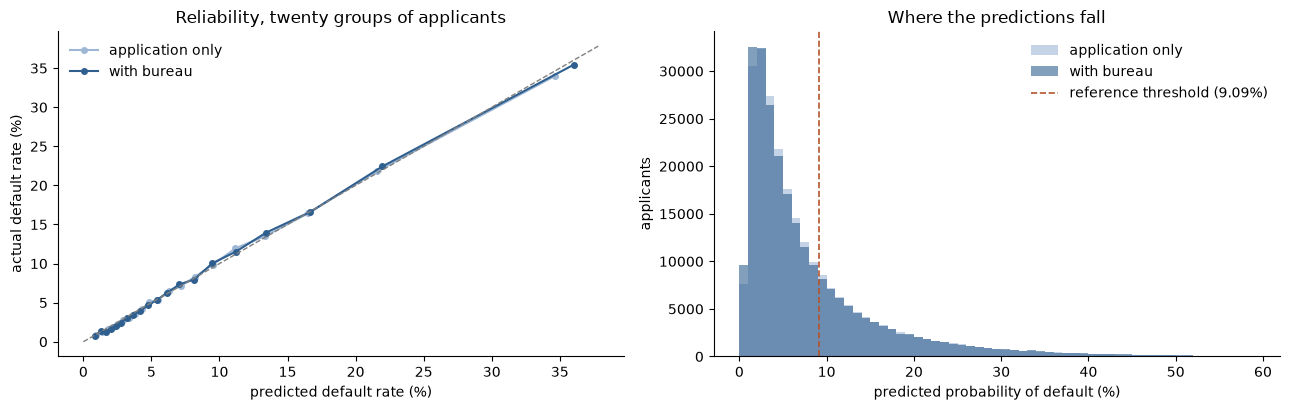

In [28]:
def reliability(p, bins=20):
    order = np.argsort(p)
    groups = np.array_split(order, bins)
    table = pd.DataFrame({'predicted_pct': [p[g].mean() * 100 for g in groups], 'actual_pct': [y_arr[g].mean() * 100 for g in groups], 'applicants': [len(g) for g in groups]})
    table['gap'] = table['predicted_pct'] - table['actual_pct']
    return table

def calibration_error(p, bins=20):
    t = reliability(p, bins)
    return float((t['gap'].abs() * t['applicants']).sum() / t['applicants'].sum()), float(t['gap'].abs().max())

report = {}
for label, p in {'application only': p_old, 'with bureau': p_new, 'with bureau, before calibration': final_run['oof']}.items():
    error, worst = calibration_error(p)
    report[label] = {'mean_prediction_pct': p.mean() * 100, 'actual_pct': y_arr.mean() * 100, 'calibration_error_pts': error, 'largest_gap_in_any_twentieth_pts': worst}
print(pd.DataFrame(report).T.to_string(float_format=lambda v: f'{v:.3f}'))

tenths = pd.DataFrame({'application only: predicted': reliability(p_old, 10)['predicted_pct'], 'application only: actual': reliability(p_old, 10)['actual_pct'],
                       'with bureau: predicted': reliability(p_new, 10)['predicted_pct'], 'with bureau: actual': reliability(p_new, 10)['actual_pct']})
tenths.index = [f'tenth {i + 1}' for i in range(10)]
print('\npredicted and actual default rate (%) by tenth of applicants, safest first:')
print(tenths.to_string(float_format=lambda v: f'{v:.2f}'))
print(f"\nthe model with bureau features spreads applicants further: safest tenth {tenths.iloc[0, 3]:.2f}% against {tenths.iloc[0, 1]:.2f}%, riskiest tenth {tenths.iloc[-1, 3]:.2f}% against {tenths.iloc[-1, 1]:.2f}%")
print(f"share of all defaults in the riskiest tenth: {tenths.iloc[-1, 1] / tenths['application only: actual'].sum():.1%} -> {tenths.iloc[-1, 3] / tenths['with bureau: actual'].sum():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for label, p, colour in [('application only', p_old, '#9db7d5'), ('with bureau', p_new, '#2f5f8f')]:
    t = reliability(p)
    axes[0].plot(t['predicted_pct'], t['actual_pct'], marker='o', markersize=4, label=label, color=colour)
limit = max(reliability(p_new)['predicted_pct'].max(), reliability(p_new)['actual_pct'].max()) * 1.05
axes[0].plot([0, limit], [0, limit], color='grey', linestyle='--', linewidth=1)
axes[0].set_xlabel('predicted default rate (%)'); axes[0].set_ylabel('actual default rate (%)'); axes[0].set_title('Reliability, twenty groups of applicants'); axes[0].legend(frameon=False)
axes[1].hist(p_old * 100, bins=np.arange(0, 60, 1), alpha=0.6, label='application only', color='#9db7d5')
axes[1].hist(p_new * 100, bins=np.arange(0, 60, 1), alpha=0.6, label='with bureau', color='#2f5f8f')
axes[1].axvline(THRESHOLD * 100, color='#b5542d', linestyle='--', linewidth=1.2, label=f'reference threshold ({THRESHOLD:.2%})')
axes[1].set_xlabel('predicted probability of default (%)'); axes[1].set_ylabel('applicants'); axes[1].set_title('Where the predictions fall'); axes[1].legend(frameon=False)
sns.despine(); plt.tight_layout(); plt.show()

### 7.3 Within groups

A model can be right on average and wrong for particular kinds of applicant. Stage 2 found that the application-only model under-predicted for applicants who had been overdue on a credit and for those with a card limit on record, the groups for which the bureau table holds information the application does not. If the bureau features are doing their job, those gaps should close.

In [29]:
age = -X_dev['DAYS_BIRTH'].values / 365.25
calibration_groups = {
    'no bureau record': ~has_record, 'has a bureau record': has_record,
    'a card limit is recorded': has_limit, 'was ever overdue on a credit': ever_overdue,
    'holds a microloan': (X_dev['BUREAU_N_MICROLOANS'] > 0).values, 'has a credit overdue now': (X_dev['BUREAU_N_OVERDUE_NOW'] > 0).values,
    'opened 3 or more credits in the last year': (X_dev['BUREAU_N_OPENED_12M'] >= 3).values, 'has a mortgage in the bureau': (X_dev['BUREAU_N_MORTGAGES'] > 0).values,
    'men': (X_dev['CODE_GENDER'] == 'M').values, 'women': (X_dev['CODE_GENDER'] == 'F').values,
    'under 30': age < 30, '30 to 45': (age >= 30) & (age < 45), '45 to 60': (age >= 45) & (age < 60), 'over 60': age >= 60,
    'cash loans': (X_dev['NAME_CONTRACT_TYPE'] == 'Cash loans').values, 'revolving loans': (X_dev['NAME_CONTRACT_TYPE'] == 'Revolving loans').values,
}
rows = {}
for label, m in calibration_groups.items():
    actual = y_arr[m].mean()
    se = np.sqrt(actual * (1 - actual) / m.sum()) * 100
    rows[label] = {'applicants': int(m.sum()), 'actual_pct': actual * 100, 'application_only_pct': p_old[m].mean() * 100, 'with_bureau_pct': p_new[m].mean() * 100,
                   'gap_application_only': (p_old[m].mean() - actual) * 100, 'gap_with_bureau': (p_new[m].mean() - actual) * 100, 'standard_error': se}
groups_table = pd.DataFrame(rows).T
groups_table['gap_in_standard_errors'] = groups_table['gap_with_bureau'] / groups_table['standard_error']
print(groups_table.astype({'applicants': int}).to_string(float_format=lambda v: f'{v:,.2f}'))
bureau_groups = list(calibration_groups)[:8]
print(f"\nlargest gap in the eight bureau-defined groups: {groups_table.loc[bureau_groups, 'gap_application_only'].abs().max():.2f} points with the application-only model, "
      f"{groups_table.loc[bureau_groups, 'gap_with_bureau'].abs().max():.2f} with bureau features")
print(f"largest gap across all {len(groups_table)} groups with bureau features: {groups_table['gap_with_bureau'].abs().max():.2f} points ({groups_table['gap_with_bureau'].abs().idxmax()}); "
      f"groups more than 2 standard errors off: {int((groups_table['gap_in_standard_errors'].abs() > 2).sum())}")
print(f"average gap, weighted by group size: {np.average(groups_table['gap_application_only'].abs(), weights=groups_table['applicants']):.3f} -> {np.average(groups_table['gap_with_bureau'].abs(), weights=groups_table['applicants']):.3f} points")

                                           applicants  actual_pct  application_only_pct  with_bureau_pct  gap_application_only  gap_with_bureau  standard_error  gap_in_standard_errors
no bureau record                                35244       10.12                  9.95            10.21                 -0.17             0.09            0.16                    0.57
has a bureau record                            210764        7.73                  7.78             7.76                  0.05             0.03            0.06                    0.45
a card limit is recorded                        31989       10.61                 10.33            10.59                 -0.28            -0.03            0.17                   -0.16
was ever overdue on a credit                    56178        9.46                  9.07             9.49                 -0.39             0.02            0.12                    0.20
holds a microloan                                2796       19.85               

### 7.4 The operating point, and what it costs

The reference rule from notebook 02: decline when the predicted probability is 0.0909 or above. That threshold follows from treating a missed default as ten times as costly as a good applicant turned away. Nothing about it is re-fitted here. The same rule is applied to both models' calibrated probabilities.

Cost is counted in units of one wrongly declined good applicant: each good applicant declined costs 1, and each defaulter approved costs the ratio.

In [30]:
def outcome(p, ratio):
    t = 1 / (1 + ratio)
    declined, bad = p >= t, y_arr == 1
    missed, wrongly = int((~declined & bad).sum()), int((declined & ~bad).sum())
    return {'threshold': t, 'approved_pct': (~declined).mean() * 100, 'defaults_caught_pct': (declined & bad).sum() / bad.sum() * 100,
            'default_rate_among_approved_pct': missed / (~declined).sum() * 100, 'good_applicants_declined_pct': wrongly / (~bad).sum() * 100,
            'cost_per_1000_applicants': (ratio * missed + wrongly) / len(p) * 1000}

rows = {}
for ratio in [5, 10, 20]:
    a, b = outcome(p_old, ratio), outcome(p_new, ratio)
    blanket = min(ratio * y_arr.mean(), 1 - y_arr.mean()) * 1000            # the better of approving everyone and declining everyone
    for label, o in [('application only', a), ('with bureau', b)]:
        rows[(f'ratio {ratio}', label)] = {**o, 'saving_against_no_model_pct': (1 - o['cost_per_1000_applicants'] / blanket) * 100}
    rows[(f'ratio {ratio}', 'change')] = {k: b[k] - a[k] for k in a} | {'saving_against_no_model_pct': (a['cost_per_1000_applicants'] - b['cost_per_1000_applicants']) / blanket * 100}
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f'{v:,.3f}'))

ref_old, ref_new = outcome(p_old, 10), outcome(p_new, 10)
d_old, d_new, bad = p_old >= THRESHOLD, p_new >= THRESHOLD, y_arr == 1
print(f"\nat the reference threshold of {THRESHOLD:.4f}:")
print(pd.DataFrame({'application only': {'approved, repaid': int((~d_old & ~bad).sum()), 'approved, defaulted': int((~d_old & bad).sum()), 'declined, repaid': int((d_old & ~bad).sum()), 'declined, defaulted': int((d_old & bad).sum())},
                    'with bureau': {'approved, repaid': int((~d_new & ~bad).sum()), 'approved, defaulted': int((~d_new & bad).sum()), 'declined, repaid': int((d_new & ~bad).sum()), 'declined, defaulted': int((d_new & bad).sum())}}
                   ).assign(change=lambda t: t['with bureau'] - t['application only']).to_string())
print(f"\ncost per 1,000 applicants at a ratio of 10: {ref_old['cost_per_1000_applicants']:.1f} -> {ref_new['cost_per_1000_applicants']:.1f} ({(ref_new['cost_per_1000_applicants'] / ref_old['cost_per_1000_applicants'] - 1):+.1%})")
print(f"applicants whose decision changes: {(d_old != d_new).mean():.1%}; newly declined default at {y_arr[d_new & ~d_old].mean():.1%}, newly approved at {y_arr[~d_new & d_old].mean():.1%}")

from scipy.stats import ks_2samp
ks = lambda p: ks_2samp(p[bad], p[~bad]).statistic
print(f"KS statistic: {ks(p_old):.4f} -> {ks(p_new):.4f}")
by_fold = pd.DataFrame({k: {'application only': (10 * (~d_old & bad)[dev_fold == k].sum() + (d_old & ~bad)[dev_fold == k].sum()) / (dev_fold == k).sum() * 1000,
                            'with bureau': (10 * (~d_new & bad)[dev_fold == k].sum() + (d_new & ~bad)[dev_fold == k].sum()) / (dev_fold == k).sum() * 1000} for k in range(N_SPLITS)}).T
by_fold['change'] = by_fold['with bureau'] - by_fold['application only']
print('\ncost per 1,000 applicants at a ratio of 10, by fold:')
print(by_fold.round(1).T.to_string())
print(f"lower cost with bureau features in {int((by_fold['change'] < 0).sum())} of 5 folds")

                           threshold  approved_pct  defaults_caught_pct  default_rate_among_approved_pct  good_applicants_declined_pct  cost_per_1000_applicants  saving_against_no_model_pct
ratio 5  application only      0.167        87.826               39.240                            5.585                         9.798                   335.322                       16.926
         with bureau           0.167        87.596               40.997                            5.438                         9.893                   329.103                       18.467
         change                0.000        -0.229                1.757                           -0.147                         0.095                    -6.219                        1.541
ratio 10 application only      0.091        71.018               65.413                            3.932                        25.782                   516.227                       36.054
         with bureau           0.091        71.201

KS statistic: 0.4026 -> 0.4162



cost per 1,000 applicants at a ratio of 10, by fold:
                      0      1      2      3      4
application only  523.4  512.7  513.1  521.1  510.7
with bureau       506.4  501.2  503.1  502.9  500.3
change            -17.0  -11.6  -10.0  -18.2  -10.4
lower cost with bureau features in 5 of 5 folds


### 7.5 Approval rates by gender and age

Notebook 02 found that the application-only model approves men at 0.80 times the rate of women, and applicants under 30 at 0.60 times the rate of those over 60. The model uses gender and age directly, and the gaps follow from real differences in default rates between the groups. Whether a lender may use those attributes is a policy question the notebook did not settle.

Adding bureau features could move those gaps either way. More information about an applicant's own record can reduce a model's reliance on group membership. It can also add a new route to the same disparity if credit history itself differs by group. This section only measures.

In [31]:
fair_groups = {'gender': {'women': calibration_groups['women'], 'men': calibration_groups['men']},
               'age': {k: calibration_groups[k] for k in ['under 30', '30 to 45', '45 to 60', 'over 60']},
               'bureau record': {'has a bureau record': has_record, 'no bureau record': ~has_record}}
rows = {}
for segment, members in fair_groups.items():
    old_rates = {g: (~d_old)[m].mean() for g, m in members.items()}
    new_rates = {g: (~d_new)[m].mean() for g, m in members.items()}
    for g, m in members.items():
        rows[(segment, g)] = {'applicants': int(m.sum()), 'default_pct': y_arr[m].mean() * 100, 'approved_application_only_pct': old_rates[g] * 100, 'approved_with_bureau_pct': new_rates[g] * 100,
                              'ratio_to_highest_application_only': old_rates[g] / max(old_rates.values()), 'ratio_to_highest_with_bureau': new_rates[g] / max(new_rates.values()),
                              'defaults_caught_application_only_pct': (d_old & bad)[m].sum() / bad[m].sum() * 100, 'defaults_caught_with_bureau_pct': (d_new & bad)[m].sum() / bad[m].sum() * 100}
fairness = pd.DataFrame(rows).T
print(fairness.astype({'applicants': int}).to_string(float_format=lambda v: f'{v:,.2f}'))
print(f"\nmen against women: {fairness.loc[('gender', 'men'), 'ratio_to_highest_application_only']:.3f} -> {fairness.loc[('gender', 'men'), 'ratio_to_highest_with_bureau']:.3f}")
print(f"under 30 against over 60: {fairness.loc[('age', 'under 30'), 'ratio_to_highest_application_only']:.3f} -> {fairness.loc[('age', 'under 30'), 'ratio_to_highest_with_bureau']:.3f}")
print(f"no bureau record against a record: {fairness.loc[('bureau record', 'no bureau record'), 'ratio_to_highest_application_only']:.3f} -> {fairness.loc[('bureau record', 'no bureau record'), 'ratio_to_highest_with_bureau']:.3f}")

                                   applicants  default_pct  approved_application_only_pct  approved_with_bureau_pct  ratio_to_highest_application_only  ratio_to_highest_with_bureau  defaults_caught_application_only_pct  defaults_caught_with_bureau_pct
gender        women                    161887         7.00                          76.26                     76.32                               1.00                          1.00                                 59.54                            61.05
              men                       84119        10.14                          60.94                     61.36                               0.80                          0.80                                 73.22                            74.27
age           under 30                  36281        11.48                          52.78                     53.59                               0.60                          0.62                                 78.01                          

### Stage 7 findings

**Calibrated, the model is better on every measure**

| Measure | Application only | With bureau | Change | Folds better |
|---|---:|---:|---:|---:|
| ROC AUC | 0.7685 | 0.7779 | +0.0094 | 5 of 5 |
| PR AUC | 0.2539 | 0.2654 | +0.0115 | 5 of 5 |
| Log loss | 0.2432 | 0.2403 | -0.0029 | 5 of 5 |
| Brier score | 0.0673 | 0.0667 | -0.0006 | 5 of 5 |

- Before calibration the model predicts an average default rate of 13.4% against an actual 8.07%, the same kind of inflation as the application-only model and for the same reason. After Platt scaling it predicts 8.11%.
- The distortion is still a plain shift. The correcting line has a slope between 0.98 and 1.01 in every fold. Adding the bureau features did not change the shape of the miscalibration, so the method chosen in notebook 02 still fits and nothing about it was re-chosen.
- Calibration changes ROC AUC by exactly zero.

**The probabilities are right across the range**
- Predicted and actual default rates agree to within 0.58 points in every twentieth of applicants, against 0.77 for the application-only model.
- The average calibration error is 0.27 points, slightly above the application-only model's 0.22. Both are small, and the difference is within what twenty groups of 12,000 applicants vary by.
- The riskiest tenth now holds 35.8% of all defaults, up from 34.6%, and defaults at 28.9%.

**The under-prediction found in stage 2 is gone**

| Group | Actual | Application only | With bureau |
|---|---:|---:|---:|
| Holds a microloan | 19.85% | 13.70% | 19.58% |
| Has a credit overdue now | 15.41% | 13.82% | 14.71% |
| Opened 3 or more credits in the last year | 13.06% | 11.98% | 12.97% |
| Has a mortgage in the bureau | 5.21% | 6.54% | 5.39% |
| Was ever overdue on a credit | 9.46% | 9.07% | 9.49% |
| A card limit is recorded | 10.61% | 10.33% | 10.59% |

- This is the clearest picture of what the bureau table adds. The application-only model was right on average and wrong for particular kinds of applicant. It gave microloan holders 13.7% when 19.9% of them default, and mortgage holders 6.5% when 5.2% do.
- With bureau features the largest gap in these groups falls from 6.15 points to 0.70. Across all 16 groups tested, none is more than two standard errors from its actual rate.
- The remaining gap is for applicants with a credit overdue now (14.7% predicted, 15.4% actual). It is within one standard error for a group of 2,868.
- For gender, age and loan type, where the application model was already right, nothing changed.

**At the reference threshold the model approves more people and catches more defaults**

| | Application only | With bureau | Change |
|---|---:|---:|---:|
| Approved | 71.02% | 71.20% | +0.18 |
| Defaults caught | 65.41% | 66.72% | +1.31 |
| Default rate among approved | 3.93% | 3.77% | -0.16 |
| Good applicants declined | 25.78% | 25.47% | -0.31 |
| Cost per 1,000 applicants, ratio 10 | 516.2 | 502.8 | -2.6% |

- In the development set that is 260 more defaults declined and 708 more good applicants approved, at the same threshold. Both kinds of mistake fall together, which only a better ordering can do.
- The cost falls in all five folds, by between 10 and 18 per 1,000 applicants.
- At cost ratios of 5 and 20 the cost falls as well, by 1.9% and 2.6%. The threshold is the same formula as before and nothing was fitted to choose it.
- 7.4% of applicants get a different decision. Those newly declined default at 11.5%, and those newly approved at 8.2%.
- The KS statistic rises from 0.403 to 0.416.

**Approval rates by group hardly move**

| Comparison | Application only | With bureau |
|---|---:|---:|
| Men against women | 0.80 | 0.80 |
| Under 30 against over 60 | 0.60 | 0.62 |
| No bureau record against a record | 0.84 | 0.81 |

- The gender and age gaps found in notebook 02 are essentially unchanged. The bureau features neither widen nor close them, and the policy question notebook 02 left open is still open.
- One gap widens. Applicants with no bureau record are approved at 0.81 times the rate of those with one, down from 0.84. They default more (10.1% against 7.7%), so a gap is expected. It widens because applicants with a record can now show a good one, and those without cannot. A person with no credit history is not the same as a person with a bad one, and a lender might reasonably treat this as a matter of policy and not only of prediction.
- More defaults are caught in every group, including those with no record.

**Leakage check for this stage**
- The calibrator is fitted inside the training folds, on predictions the model made for rows it had not seen.
- The calibration method and the threshold were taken from notebook 02 unchanged. Nothing was chosen in this stage.
- All figures are out-of-fold on the frozen folds. The holdout was not used.

**Decisions**
- The model carried forward is the 60-feature model with Platt scaling, and the reference threshold stays at 0.0909.
- For the conclusions: the wider approval gap for applicants with no bureau record.

## Stage 8: Explainability

Do bureau features take over from the external scores as reasons for a decline?

Notebook 02 ended its explanation of the application-only model with a limit. For about seven declines in ten, the main reason was a low external score, and those scores come from outside providers whose inputs are unknown. A lender could tell an applicant "your external score is low" and nothing more. Notebook 03 then concluded that one of the three scores, `EXT_SOURCE_3`, is very probably built from credit bureau data. If so, the bureau features might let the model say directly what the score was summarising: you have four live loans, you opened three credits this year, you were overdue on one.

That is the hope. This stage measures how far it is met.

**Method**, as in notebook 02. Both models are fitted on the whole development set with calibration. For a sample of 20,000 applicants, each prediction is split into one contribution per feature (SHAP values, computed exactly by LightGBM), expressed in the same calibrated log-odds as the probability. A contribution above zero pushes the applicant's risk up. A family's contribution is the sum over its features.

| Section | What it does |
|---|---|
| 8.1 | Fit both models and check the contributions add up |
| 8.2 | What each model relies on, by family and by feature |
| 8.3 | Reasons for a decline, before and after |
| 8.4 | Two applicants whose decision changed |
| 8.5 | Do the explanations hold for applicants the model has not seen? |

An explanation describes what a model does. It is not a measure of accuracy, so explaining rows the model was trained on does not inflate any score. Section 8.5 still checks that the picture is the same for unseen applicants.

### 8.1 Fit and check

In [32]:
MODEL_DIR = CACHE_DIR / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def fitted(tag, build):
    # a fitted pipeline, saved to disk so that a later run does not have to fit it again
    path = MODEL_DIR / f'{tag}.joblib'
    if path.exists():
        return joblib.load(path), True
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        model = build()
    joblib.dump(model, path, compress=3)
    return model, False

def model_tag(prefix, features, params, trees, rows):
    spec = {'features': list(features), 'params': {k: repr(v) for k, v in sorted(params.items())}, 'trees': trees, 'rate': LEARNING_RATE, 'rows': rows, 'seed': SEED,
            'module': hashlib.md5(Path('../src/models/pipeline.py').read_bytes()).hexdigest(), 'versions': [lightgbm.__version__, sklearn.__version__]}
    return prefix + '_' + hashlib.md5(json.dumps(spec, sort_keys=True).encode()).hexdigest()[:16]

started = time.time()
new_model, c1 = fitted(model_tag('dev_with_bureau', CHOSEN_FEATURES, FINAL_PARAMS, FINAL_TREES, 'dev'),
                       lambda: make_pipeline(CHOSEN_FEATURES, TEXT_FEATURES, CalibratedModel(MODEL(), method='platt')).fit(X_dev, y_arr))
old_model, c2 = fitted(model_tag('dev_application_only', APP_FINAL, BEST_PARAMS, N_TREES, 'dev'),
                       lambda: make_pipeline(APP_FINAL, TEXT_FEATURES, CalibratedModel(FINAL(), method='platt')).fit(X_dev, y_arr))
print(f"both models fitted on the development set: {(time.time() - started) / 60:.1f} minutes ({int(c1) + int(c2)} of 2 loaded from disk)")

def explain_sample(model, X_raw):
    # contributions in calibrated log-odds, one column per feature, plus the starting point
    prepared = model.named_steps['preprocess'].transform(X_raw)
    calibrated_step = model.named_steps['model']
    a, b = float(calibrated_step.calibrator_.coef_[0, 0]), float(calibrated_step.calibrator_.intercept_[0])
    out = calibrated_step.model_.booster_.predict(prepared, pred_contrib=True)
    return pd.DataFrame(a * out[:, :-1], columns=list(prepared.columns), index=X_raw.index), float(a * out[0, -1] + b), (a, b)

sample_rows = np.sort(np.random.default_rng(SEED).choice(len(X_dev), size=20_000, replace=False))       # the same sample as notebook 02, stage 12
X_sample, y_sample = X_dev.iloc[sample_rows], y_arr[sample_rows]
started = time.time()
shap_new, base_new, line_new = explain_sample(new_model, X_sample)
shap_old, base_old, line_old = explain_sample(old_model, X_sample)
print(f"contributions for {len(X_sample):,} applicants under both models in {time.time() - started:.0f} seconds")

sigmoid = lambda z: 1 / (1 + np.exp(-z))
p_fit_new, p_fit_old = new_model.predict_proba(X_sample)[:, 1], old_model.predict_proba(X_sample)[:, 1]
checks = {
    'with bureau: contributions and starting point rebuild the probability': float(np.abs(sigmoid(shap_new.sum(axis=1).values + base_new) - p_fit_new).max()),
    'application only: the same': float(np.abs(sigmoid(shap_old.sum(axis=1).values + base_old) - p_fit_old).max()),
}
for name, gap in checks.items():
    print(f"largest difference, {name}: {gap:.1e}")
assert max(checks.values()) < 1e-9
print(f"\nstarting point: application only {sigmoid(base_old):.2%}, with bureau {sigmoid(base_new):.2%}")
print(f"calibration line: application only {line_old[0]:.4f} x log-odds {line_old[1]:+.4f}  (notebook 02: 1.0051 and -0.6447); with bureau {line_new[0]:.4f} x log-odds {line_new[1]:+.4f}")
print(f"average predicted probability in the sample: {p_fit_old.mean():.2%} and {p_fit_new.mean():.2%}; actual default rate in the sample {y_sample.mean():.2%}")
print(f"features explained: {shap_old.shape[1]} and {shap_new.shape[1]}")

both models fitted on the development set: 0.0 minutes (2 of 2 loaded from disk)


contributions for 20,000 applicants under both models in 133 seconds


largest difference, with bureau: contributions and starting point rebuild the probability: 4.1e-15
largest difference, application only: the same: 4.7e-15

starting point: application only 5.67%, with bureau 5.52%
calibration line: application only 1.0051 x log-odds -0.6447  (notebook 02: 1.0051 and -0.6447); with bureau 0.9924 x log-odds -0.6513
average predicted probability in the sample: 7.99% and 8.04%; actual default rate in the sample 7.90%
features explained: 36 and 60


### 8.2 What each model relies on

In [33]:
APP_FAMILIES = {            # the families of notebook 02, stage 12
    'external scores': [c for c in APP_FINAL if c.startswith('EXT_')],
    'loan and amounts': ['AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'ANNUITY_TO_CREDIT', 'CREDIT_TO_GOODS', 'CREDIT_TO_INCOME', 'ANNUITY_TO_INCOME', 'NAME_CONTRACT_TYPE'],
    'age, gender, education, family': ['DAYS_BIRTH', 'CODE_GENDER', 'EDUCATION_LEVEL', 'NAME_FAMILY_STATUS'],
    'employment': ['DAYS_EMPLOYED', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE'],
    'documents, phone and registration': ['DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE', 'FLAG_DOCUMENT_3', 'FLAG_WORK_PHONE'],
    'housing, car and region': ['OWN_CAR_AGE', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'REGION_RATING_CLIENT_W_CITY', 'REG_CITY_NOT_LIVE_CITY'],
    'social circle and bureau enquiries': ['OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE', 'AMT_REQ_CREDIT_BUREAU_YEAR'],
}
assert sorted(c for members in APP_FAMILIES.values() for c in members) == sorted(APP_FINAL)
ALL_FAMILIES = {**APP_FAMILIES, 'credit bureau': list(KEPT_BUREAU)}
family_of = {c: f for f, members in ALL_FAMILIES.items() for c in members}

size_old, size_new = shap_old.abs().mean(), shap_new.abs().mean()
by_family = pd.DataFrame({'features': {f: len(m) for f, m in ALL_FAMILIES.items()},
                          'application only: share (%)': {f: size_old.reindex(m).sum() / size_old.sum() * 100 for f, m in ALL_FAMILIES.items()},
                          'with bureau: share (%)': {f: size_new.reindex(m).sum() / size_new.sum() * 100 for f, m in ALL_FAMILIES.items()},
                          'application only: size': {f: size_old.reindex(m).sum() for f, m in ALL_FAMILIES.items()},
                          'with bureau: size': {f: size_new.reindex(m).sum() for f, m in ALL_FAMILIES.items()}}).fillna(0)
by_family['change in size (%)'] = (by_family['with bureau: size'] / by_family['application only: size'].where(by_family['application only: size'] > 0) - 1) * 100
print("share of each model's total contribution, by family ('size' is the summed average contribution of the family's features, in log-odds):")
print(by_family.sort_values('with bureau: share (%)', ascending=False).to_string(float_format=lambda v: f'{v:.2f}'))

top = pd.DataFrame({'family': pd.Series(family_of), 'with bureau': size_new, 'application only': size_old}).sort_values('with bureau', ascending=False)
top['rank'] = np.arange(1, len(top) + 1)
top['rank before'] = top['application only'].rank(ascending=False)
top['change (%)'] = (top['with bureau'] / top['application only'] - 1) * 100
print('\nthe twenty features the model with bureau features relies on most (average size of contribution):')
print(top.head(20).to_string(float_format=lambda v: f'{v:.3f}'))
print(f"\nbureau features in the top 10: {int((top.head(10)['family'] == 'credit bureau').sum())}; in the top 20: {int((top.head(20)['family'] == 'credit bureau').sum())}; highest-ranked: {top.index[top['family'] == 'credit bureau'][0]} at {int(top.loc[top.index[top['family'] == 'credit bureau'][0], 'rank'])}")
ext = APP_FAMILIES['external scores']
print('\nthe external score features, before and after:')
print(top.loc[ext, ['application only', 'with bureau', 'change (%)']].sort_values('application only', ascending=False).to_string(float_format=lambda v: f'{v:.3f}'))
bureau_sum, ext3_old = shap_new[KEPT_BUREAU].sum(axis=1), shap_old['EXT_SOURCE_3']
print(f"\ncorrelation, across applicants, between what the bureau features contribute now and what EXT_SOURCE_3 contributed before: {bureau_sum.corr(ext3_old):.3f}")
print(f"correlation between the two models' total log-odds: {(shap_new.sum(axis=1)).corr(shap_old.sum(axis=1)):.3f}")

share of each model's total contribution, by family ('size' is the summed average contribution of the family's features, in log-odds):
                                    features  application only: share (%)  with bureau: share (%)  application only: size  with bureau: size  change in size (%)
external scores                            8                        32.96                   24.50                    0.80               0.73               -8.36
credit bureau                             24                         0.00                   23.31                    0.00               0.69                 NaN
loan and amounts                           8                        22.92                   18.00                    0.55               0.54               -3.23
age, gender, education, family             4                        13.73                   11.04                    0.33               0.33               -0.82
employment                                 3                

### 8.3 Reasons for a decline

For each declined applicant, the main reason is the family whose features together push the risk up the most. Notebook 02 found the external scores were the main reason for 71% of declines.

In [34]:
def family_push(shap, families):
    return pd.DataFrame({f: shap[[c for c in members if c in shap.columns]].sum(axis=1) for f, members in families.items() if any(c in shap.columns for c in members)})

push_old, push_new = family_push(shap_old, APP_FAMILIES), family_push(shap_new, ALL_FAMILIES)
declined_old, declined_new = p_fit_old >= THRESHOLD, p_fit_new >= THRESHOLD
print(f"declined in the sample: {declined_old.mean():.1%} by the application-only model, {declined_new.mean():.1%} by the model with bureau features")

reasons = pd.DataFrame({'application only: main reason (%)': push_old[declined_old].idxmax(axis=1).value_counts(normalize=True) * 100,
                        'with bureau: main reason (%)': push_new[declined_new].idxmax(axis=1).value_counts(normalize=True) * 100,
                        'with bureau: among the top two (%)': pd.Series({f: (push_new[declined_new].rank(axis=1, ascending=False)[f] <= 2).mean() * 100 for f in push_new.columns}),
                        'with bureau: average odds multiplier among declined': np.exp(push_new[declined_new].mean())}).fillna(0).sort_values('with bureau: main reason (%)', ascending=False)
print(reasons.to_string(float_format=lambda v: f'{v:.2f}'))

ext_main_old = (push_old[declined_old].idxmax(axis=1) == 'external scores').mean()
ext_main_new = (push_new[declined_new].idxmax(axis=1) == 'external scores').mean()
bureau_main = (push_new[declined_new].idxmax(axis=1) == 'credit bureau').mean()
print(f"\ndeclines whose main reason is an external score: {ext_main_old:.1%} -> {ext_main_new:.1%}")
print(f"declines whose main reason is the credit bureau family: {bureau_main:.1%}; where it is among the top two: {reasons.loc['credit bureau', 'with bureau: among the top two (%)']:.1f}%")

explainable = push_new[declined_new].drop(columns='external scores')
print(f"declines where the families other than the external scores, added together, push the risk up by more than the external scores do: "
      f"{(explainable.clip(lower=0).sum(axis=1) > push_new.loc[declined_new, 'external scores']).mean():.1%} "
      f"(application only: {(push_old[declined_old].drop(columns='external scores').clip(lower=0).sum(axis=1) > push_old.loc[declined_old, 'external scores']).mean():.1%})")

# which single bureau features are most often the largest bureau reason for a decline
bureau_declined = shap_new.loc[declined_new, KEPT_BUREAU]
leading = pd.DataFrame({'largest bureau reason (%)': bureau_declined.idxmax(axis=1).value_counts(normalize=True) * 100,
                        'pushes risk up for (% of declined)': (bureau_declined > 0.05).mean() * 100,
                        'average odds multiplier when it does': np.exp(bureau_declined.where(bureau_declined > 0.05).mean())}).sort_values('largest bureau reason (%)', ascending=False)
leading.index = [c.replace('BUREAU_', '') for c in leading.index]
print('\namong declined applicants, the bureau feature that pushes risk up the most:')
print(leading.head(10).to_string(float_format=lambda v: f'{v:.2f}'))
print(f"\ndeclined applicants for whom the bureau family as a whole lowers the risk: {(push_new.loc[declined_new, 'credit bureau'] < 0).mean():.1%}; "
      f"approved applicants for whom it raises it: {(push_new.loc[~declined_new, 'credit bureau'] > 0).mean():.1%}")

declined in the sample: 28.3% by the application-only model, 28.1% by the model with bureau features


                                    application only: main reason (%)  with bureau: main reason (%)  with bureau: among the top two (%)  with bureau: average odds multiplier among declined
external scores                                                 70.88                         63.12                               75.80                                                 1.89
loan and amounts                                                19.53                         17.43                               41.50                                                 1.22
credit bureau                                                    0.00                         11.71                               39.54                                                 1.21
age, gender, education, family                                   3.34                          3.02                               13.10                                                 1.05
employment                                             

declines where the families other than the external scores, added together, push the risk up by more than the external scores do: 63.6% (application only: 47.7%)

among declined applicants, the bureau feature that pushes risk up the most:
                                       largest bureau reason (%)  pushes risk up for (% of declined)  average odds multiplier when it does
DAYS_SINCE_LAST_CLOSED                                     14.34                               18.00                                  1.06
DAYS_SINCE_LAST_OVERDUE_CREDIT_OPENED                      12.53                               23.01                                  1.20
LIVE_LOAN_MAX_SHARE_OWED                                    9.76                               22.14                                  1.17
SHARE_LIVE                                                  8.58                               24.04                                  1.08
DAYS_SINCE_LAST_OPENED                                      7.75  

### 8.4 Two applicants whose decision changed

One applicant the application-only model would approve and the model with bureau features declines, and one the other way round. For each, the six largest contributions under the new model are shown, with the value of the feature.

In [35]:
def show(position, top_n=6):
    row, contributions = X_sample.iloc[position], shap_new.iloc[position]
    order = contributions.abs().sort_values(ascending=False).index[:top_n]
    def readable(c):
        v = row[c]
        if isinstance(v, str) or pd.isna(v):
            return 'missing' if not isinstance(v, str) else v
        if c.startswith('DAYS_') and 'BUREAU' not in c:
            return f'{-v / 365.25:.1f} years'
        if 'DAYS' in c:
            return f'{v:,.0f} days'
        return f'{v:,.3f}' if abs(v) < 10 else f'{v:,.0f}'
    table = pd.DataFrame({'family': [family_of[c] for c in order], 'value': [readable(c) for c in order], 'contribution': contributions[order].values,
                          'odds_multiplier': np.exp(contributions[order].values)}, index=[c.replace('BUREAU_', 'bureau: ') for c in order])
    table['direction'] = np.where(table['contribution'] > 0, 'raises risk', 'lowers risk')
    rest = contributions.drop(order).sum()
    print(f"  application-only model: {p_fit_old[position]:.2%}   with bureau features: {p_fit_new[position]:.2%}   (threshold {THRESHOLD:.2%}; in fact {'defaulted' if y_sample[position] == 1 else 'repaid'})")
    print(f"  family totals: external scores x{np.exp(push_new['external scores'].iloc[position]):.2f}, credit bureau x{np.exp(push_new['credit bureau'].iloc[position]):.2f}, "
          f"everything else x{np.exp(push_new.drop(columns=['external scores', 'credit bureau']).iloc[position].sum()):.2f}")
    print(table.to_string(float_format=lambda v: f'{v:.3f}'))
    print(f"  all other features together: x{np.exp(rest):.2f}\n")

margin = np.log(p_fit_new / (1 - p_fit_new)) - np.log(p_fit_old / (1 - p_fit_old))
newly_declined = np.where(declined_new & ~declined_old)[0]
newly_approved = np.where(~declined_new & declined_old)[0]
print(f"in the sample: {len(newly_declined):,} newly declined, {len(newly_approved):,} newly approved")
pick_declined = newly_declined[np.argsort(-push_new['credit bureau'].values[newly_declined])[len(newly_declined) // 10]]       # a clear case, not the most extreme one
pick_approved = newly_approved[np.argsort(push_new['credit bureau'].values[newly_approved])[len(newly_approved) // 10]]
print(f"\nNEWLY DECLINED (applicant {X_sample.index[pick_declined]}):")
show(pick_declined)
print(f"NEWLY APPROVED (applicant {X_sample.index[pick_approved]}):")
show(pick_approved)
print(f"among the newly declined, the bureau family raises risk for {(push_new['credit bureau'].values[newly_declined] > 0).mean():.1%}; among the newly approved, it lowers risk for {(push_new['credit bureau'].values[newly_approved] < 0).mean():.1%}")

in the sample: 713 newly declined, 748 newly approved

NEWLY DECLINED (applicant 374491):
  application-only model: 5.29%   with bureau features: 11.64%   (threshold 9.09%; in fact defaulted)
  family totals: external scores x1.24, credit bureau x2.21, everything else x0.83
                                                              family       value  contribution  odds_multiplier    direction
OBS_30_CNT_SOCIAL_CIRCLE          social circle and bureau enquiries          11         0.245            1.278  raises risk
ANNUITY_TO_CREDIT                                   loan and amounts       0.027        -0.244            0.783  lowers risk
bureau: LIVE_MAX_DAYS_REMAINING                        credit bureau  1,640 days         0.188            1.207  raises risk
bureau: DAYS_SINCE_LAST_UPDATE                         credit bureau      1 days         0.169            1.185  raises risk
bureau: LIVE_LOAN_MAX_SHARE_OWED                       credit bureau       0.961         0.159      

### 8.5 Do the explanations hold for unseen applicants?

The sample above comes from rows the model was trained on. A second model is fitted without fold 0, and both models explain the applicants in the sample who are in fold 0, whom the second model has never seen. If the two explanations agree, the picture does not depend on the applicant having been in the training data.

In [36]:
in_fold0 = dev_fold[sample_rows] == 0
keep0 = dev_fold != 0
unseen_model, was_loaded = fitted(model_tag('without_fold0', CHOSEN_FEATURES, FINAL_PARAMS, FINAL_TREES, 'dev without fold 0'),
                                  lambda: make_pipeline(CHOSEN_FEATURES, TEXT_FEATURES, MODEL()).fit(X_dev[keep0], y_arr[keep0]))
prepared = unseen_model.named_steps['preprocess'].transform(X_sample[in_fold0])
raw_unseen = pd.DataFrame(unseen_model.named_steps['model'].booster_.predict(prepared, pred_contrib=True)[:, :-1], columns=list(prepared.columns), index=prepared.index)
raw_seen = shap_new[in_fold0] / line_new[0]                                   # the final model, before the calibration rescaling, same applicants

fam = lambda s: family_push(s, ALL_FAMILIES)
row_corr = np.array([np.corrcoef(raw_unseen.values[i], raw_seen.values[i])[0, 1] for i in range(len(raw_seen))])
agreement = pd.Series({
    'applicants compared (in fold 0, unseen by the second model)': int(in_fold0.sum()),
    'rank agreement on overall feature importance (Spearman)': raw_unseen.abs().mean().corr(raw_seen.abs().mean(), method='spearman'),
    'median correlation between the two explanations of one applicant': float(np.median(row_corr)),
    'same main risk-raising family (%)': float((fam(raw_unseen).values.argmax(axis=1) == fam(raw_seen).values.argmax(axis=1)).mean() * 100),
    'share of total contribution from the bureau family: model that saw the rows (%)': float(raw_seen[KEPT_BUREAU].abs().mean().sum() / raw_seen.abs().mean().sum() * 100),
    'share of total contribution from the bureau family: model that did not (%)': float(raw_unseen[KEPT_BUREAU].abs().mean().sum() / raw_unseen.abs().mean().sum() * 100),
    'share from the external scores: model that saw the rows (%)': float(raw_seen[ext].abs().mean().sum() / raw_seen.abs().mean().sum() * 100),
    'share from the external scores: model that did not (%)': float(raw_unseen[ext].abs().mean().sum() / raw_unseen.abs().mean().sum() * 100),
})
print(agreement.round(3).to_string())

applicants compared (in fold 0, unseen by the second model)                        4187.000
rank agreement on overall feature importance (Spearman)                               0.991
median correlation between the two explanations of one applicant                      0.981
same main risk-raising family (%)                                                    88.608
share of total contribution from the bureau family: model that saw the rows (%)      23.235
share of total contribution from the bureau family: model that did not (%)           23.854
share from the external scores: model that saw the rows (%)                          24.539
share from the external scores: model that did not (%)                               24.248


### Stage 8 findings

**The hope is partly met.** The bureau features have become a large part of how the model reasons, and they have taken some ground from the external scores. They have not replaced them.

**What each model relies on**

| Family | Features | Application only | With bureau |
|---|---:|---:|---:|
| External scores | 8 | 33.0% | 24.5% |
| Credit bureau | 24 | | 23.3% |
| Loan and amounts | 8 | 22.9% | 18.0% |
| Age, gender, education, family | 4 | 13.7% | 11.0% |
| Employment | 3 | 9.3% | 7.8% |
| Housing, car and region | 5 | 8.7% | 6.8% |
| Documents, phone and registration | 5 | 8.3% | 6.4% |
| Social circle and bureau enquiries | 3 | 4.2% | 2.3% |

- The bureau family now carries 23% of the model's total contribution, almost level with the external scores at 24.5%.
- Most of that is added on top, not taken from elsewhere. The other families' shares fall mainly because the total grew. In absolute size the external scores shrink by 8% and the rest by under 5%.
- The one family that really gives way is "social circle and bureau enquiries", down by a third. Its bureau enquiry count was a rough stand-in for bureau history, and the model now has the history itself.

**No single bureau feature is among the leaders**
- The top 17 features are all application features, led as before by `EXT_MEAN`, `ANNUITY_TO_CREDIT` and `EXT_SOURCE_3`. The first bureau feature is 18th.
- The bureau family's weight comes from 24 modest contributions, not from one or two strong ones. This is the same lesson as stage 3, seen from the other side: the gain was larger than single-feature scores predicted because many small things add up.
- For explanation this is less convenient than one strong feature. A reason such as "bureau history" is true for many applicants and has to be unpacked into several facts.

**`EXT_SOURCE_3` gives way, and `EXT_MEAN` does not**
- `EXT_SOURCE_3`'s contribution falls by 25%, the largest fall of any leading feature. `EXT_SOURCE_2` falls by 16%. `EXT_MEAN`, the model's strongest feature, is unchanged, and `EXT_SOURCE_1` rises slightly.
- That fits notebook 03's conclusion that `EXT_SOURCE_3` is the bureau-based score. But the replacement is loose. Across applicants, what the bureau features contribute now has a correlation of only 0.20 with what `EXT_SOURCE_3` contributed before. The bureau features are mostly saying something the score did not, which is why they improve the model and do not merely re-explain it.

**Reasons for a decline**

| Main reason | Application only | With bureau |
|---|---:|---:|
| External scores | 70.9% | 63.1% |
| Loan and amounts | 19.5% | 17.4% |
| Credit bureau | | 11.7% |
| Everything else | 9.6% | 7.7% |

- The share of declines whose main reason is an opaque external score falls from 71% to 63%. That is an improvement, and a modest one. For nearly two declines in three, the largest single reason is still a score whose inputs are unknown.
- The bureau family is the main reason for 12% of declines and one of the top two for 40%. So for four declined applicants in ten, a concrete fact about their credit history is now among the two things that counted most.
- Put another way: the declines where everything other than the external scores, added together, outweighs the external scores rise from 48% to 64%.
- The bureau facts that most often lead are time since the last credit was closed, time since an overdue credit was opened, the most heavily owed loan, and the share of credits that are live. These can be said to an applicant in plain words, which a score cannot.
- The bureau family does not only raise risk. It lowers it for 26% of declined applicants and raises it for 39% of approved ones.

**Two applicants**
- One, with an application-only probability of 5.3%, is now declined at 11.6%. The bureau family multiplies their odds by 2.2: a live loan with 1,640 days still to run and 96% of it still owed. They defaulted.
- The other falls from 12.6% to 5.8% and is now approved. Their external scores are low and still count against them (odds times 2.7), but the bureau shows no debt on any live credit and a credit closed 117 days ago, which nearly halves the odds. They repaid.
- These are two cases chosen as clear examples, not evidence. The evidence is the group result in stage 7: the newly declined default at 11.5% and the newly approved at 8.2%.
- Among all newly declined applicants in the sample the bureau family raises risk for 98%, and among the newly approved it lowers risk for 91%. The decisions change because of the bureau features, as they should.

**The explanations hold for unseen applicants**
- A model fitted without fold 0 explains the 4,187 fold-0 applicants in the sample almost identically: rank agreement on feature importance 0.991, median correlation between the two explanations of one applicant 0.981, and the same main family for 88.6%.
- The bureau family's share is 23.2% under the model that saw these applicants and 23.9% under the one that did not.

**Checks**
- For both models the contributions and the starting point rebuild the reported probability to within 5e-15.
- The application-only model refitted here has the calibration line 1.0051 and -0.6447, the same as notebook 02's to four decimals. This is one more confirmation that the shared code reproduces notebook 02.

**Limits**
- Contributions describe what the model does, not what causes default.
- The three external scores remain the largest single influence, and remain unexplained.
- Family totals depend on how features are grouped. The eight external-score features are built from three scores and share one effect, and the 24 bureau features overlap with each other in the same way.

**Decisions**
- Nothing about the model changes.
- A reason given to an applicant should name the bureau facts that pushed their risk up, where there are any, alongside the external score.

## Stage 9: Outputs

Refit the model on all of the training data, save it, and write the Kaggle submission files.

Every choice is fixed: the 60 features (stage 5), the settings and 3,500 trees (stage 6), Platt scaling and the threshold (stage 7). This stage changes none of them.

**About the holdout.** As in notebook 02, the model that produces the submission is fitted on all 307,511 training applicants, holdout included, because more data gives a better model and the test file has no labels to score it on anyway. The holdout applicants are used as training rows only. Nothing is scored on them, here or anywhere in this notebook. The holdout's one remaining use, a final check of the model that includes every history table, is untouched: that model will be fitted on the development set alone and scored on the holdout once.

So the model saved here has not been scored on any labelled data it did not see, and cannot be. Its evidence is the cross-validated result of the same recipe on the development set (ROC AUC 0.7779), and the Kaggle score.

**Why two submissions.** Stage 4 decided to keep the microloan features although microloans are twice as common among test applicants. Cross-validation cannot say whether that was right, because every fold comes from train. So, as notebook 02 did for `ANNUITY_TO_CREDIT`, a second model is fitted without them and submitted as a diagnostic. It is not a candidate: choosing between the two on the Kaggle score would be tuning on the test set.

| Section | What it does |
|---|---|
| 9.1 | Refit on all training applicants |
| 9.2 | Check the refitted model against the one fitted on the development set |
| 9.3 | Save it, and confirm a separate process can load and use it |
| 9.4 | The diagnostic model, and expectations fixed before any score is seen |
| 9.5 | Write and check the submission files |
| 9.6 | Kaggle scores |

### 9.1 Refit on all training applicants

In [37]:
import subprocess, tempfile

def load_joined(which):
    app = pd.read_parquet(f'{PROCESSED}/application_{which}_features.parquet')
    app['REGION_RATING_CLIENT_W_CITY'] = app['REGION_RATING_CLIENT_W_CITY'].astype(float)
    bur = pd.read_parquet(f'{PROCESSED}/bureau_{which}_features.parquet')
    assert app.index.equals(bur.index)
    return app.join(bur, how='left')

train_all = load_joined('train')
X_all, y_all = train_all.drop(columns='TARGET'), train_all['TARGET'].values
X_test = load_joined('test')
del train_all

refit_checks = {
    'all 307,511 training applicants, 24,825 defaults': len(X_all) == 307511 and int(y_all.sum()) == 24825,
    'exactly the applicants of the frozen split': set(X_all.index) == set(split.index),
    'the development rows are unchanged': X_all.loc[X_dev.index, CHOSEN_FEATURES].equals(X_dev[CHOSEN_FEATURES]),
    'test: 48,744 applicants, none in train': len(X_test) == 48744 and len(X_test.index.intersection(X_all.index)) == 0,
    'test has every feature the model needs, with the same types': all(str(X_test[c].dtype) == str(X_all[c].dtype) for c in CHOSEN_FEATURES),
    'the test table has no outcome column': 'TARGET' not in X_test.columns,
}
for name, ok in refit_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(refit_checks.values())

def final_recipe(features):
    return make_pipeline(features, TEXT_FEATURES, CalibratedModel(MODEL(), method='platt'))

started = time.time()
production, was_loaded = fitted(model_tag('all_train_with_bureau', CHOSEN_FEATURES, FINAL_PARAMS, FINAL_TREES, 'all train'), lambda: final_recipe(CHOSEN_FEATURES).fit(X_all, y_all))
print(f"\nrefitted on all training applicants: {'loaded from disk' if was_loaded else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
prod_step, dev_step = production.named_steps['model'], new_model.named_steps['model']
PROD_A, PROD_B = float(prod_step.calibrator_.coef_[0, 0]), float(prod_step.calibrator_.intercept_[0])
prod_features = list(production.named_steps['preprocess'].named_steps['keep'].columns_)
assert prod_features == CHOSEN_FEATURES and prod_step.model_.n_estimators_ == FINAL_TREES
print(pd.DataFrame({'fitted on the development set': {'training applicants': f'{len(X_dev):,}', 'defaults': f'{int(y_arr.sum()):,}', 'features': len(CHOSEN_FEATURES), 'trees': f'{dev_step.model_.n_estimators_:,}',
                                                      'calibration slope': f'{line_new[0]:.4f}', 'calibration intercept': f'{line_new[1]:.4f}'},
                    'refitted on all of train': {'training applicants': f'{len(X_all):,}', 'defaults': f'{int(y_all.sum()):,}', 'features': len(prod_features), 'trees': f'{prod_step.model_.n_estimators_:,}',
                                                 'calibration slope': f'{PROD_A:.4f}', 'calibration intercept': f'{PROD_B:.4f}'}}).to_string())
print(f"identical LightGBM settings: {prod_step.model_.get_params() == dev_step.model_.get_params()}")

PASS  all 307,511 training applicants, 24,825 defaults
PASS  exactly the applicants of the frozen split
PASS  the development rows are unchanged
PASS  test: 48,744 applicants, none in train
PASS  test has every feature the model needs, with the same types
PASS  the test table has no outcome column

refitted on all training applicants: loaded from disk
                      fitted on the development set refitted on all of train
training applicants                         246,008                  307,511
defaults                                     19,860                   24,825
features                                         60                       60
trees                                         3,500                    3,500
calibration slope                            0.9924                   1.0013
calibration intercept                       -0.6513                  -0.6447
identical LightGBM settings: True


### 9.2 Is the refitted model the same model?

It cannot be scored, but it can be compared with the model fitted on the development set, which was. Both are run on the 48,744 test applicants, whom neither has seen.

In [38]:
from scipy.stats import spearmanr

p_test = production.predict_proba(X_test)[:, 1]
p_test_dev = new_model.predict_proba(X_test)[:, 1]
assert np.isfinite(p_test).all() and ((p_test > 0) & (p_test < 1)).all()
moved = np.abs(p_test - p_test_dev)
previous = pd.read_csv('../artifacts/submissions/submission_final_model.csv').set_index('SK_ID_CURR')['TARGET'].reindex(X_test.index).values     # the application-only submission of notebook 02
test_record = (X_test['BUREAU_N_CREDITS'] > 0).values
agreement = pd.Series({
    'test applicants scored': len(p_test),
    'rank correlation, refitted against development-fitted': spearmanr(p_test, p_test_dev)[0],
    'average prediction, development-fitted (%)': p_test_dev.mean() * 100,
    'average prediction, refitted (%)': p_test.mean() * 100,
    'median change in one applicant\'s probability (points)': np.median(moved) * 100,
    'same decision at the reference threshold (%)': ((p_test >= THRESHOLD) == (p_test_dev >= THRESHOLD)).mean() * 100,
    'declined at the reference threshold, refitted (%)': (p_test >= THRESHOLD).mean() * 100,
    'rank correlation with the application-only submission of notebook 02': spearmanr(p_test, previous)[0],
    'same decision as the application-only submission (%)': ((p_test >= THRESHOLD) == (previous >= THRESHOLD)).mean() * 100,
    'test applicants with a bureau record (%)': test_record.mean() * 100,
    'test applicants holding a microloan (%)': (X_test['BUREAU_N_MICROLOANS'] > 0).mean() * 100,
})
print(agreement.round(4).to_string())
print(f"\nfor comparison on the development set: default rate {y_arr.mean():.2%}; average cross-validated prediction {p_new.mean():.2%}; declined at the reference threshold {(p_new >= THRESHOLD).mean():.1%}; "
      f"with a bureau record {has_record.mean():.1%}; holding a microloan {(X_dev['BUREAU_N_MICROLOANS'] > 0).mean():.2%}")
print(f"rank correlation between the two models' cross-validated predictions on the development set: {spearmanr(p_new, p_old)[0]:.4f}")

test applicants scored                                                  48744.0000
rank correlation, refitted against development-fitted                       0.9901
average prediction, development-fitted (%)                                  8.0340
average prediction, refitted (%)                                            8.0518
median change in one applicant's probability (points)                       0.4029
same decision at the reference threshold (%)                               96.7483
declined at the reference threshold, refitted (%)                          29.0969
rank correlation with the application-only submission of notebook 02        0.9530
same decision as the application-only submission (%)                       92.8914
test applicants with a bureau record (%)                                   86.8209
test applicants holding a microloan (%)                                     2.1869

for comparison on the development set: default rate 8.07%; average cross-validated pre

### 9.3 Save the model

The model is saved in the same form as notebook 02's: LightGBM's own text file for the trees, and a JSON file for everything else. `src/models/scoring.py`, written for the application-only model, loads it without change, because it reads the feature list and the text levels from the file. The only difference for a caller is that the input table must now carry the bureau columns as well.

The application-only model in `artifacts/final_model/` is left as it is.

In [39]:
import scipy
SAVE_DIR = Path('../artifacts/model_with_bureau')
SAVE_DIR.mkdir(parents=True, exist_ok=True)
prod_step.model_.booster_.save_model(str(SAVE_DIR / 'model.txt'))
model_sha = hashlib.sha256((SAVE_DIR / 'model.txt').read_bytes()).hexdigest()
levels = production.named_steps['preprocess'].named_steps['encode'].categories_

saved_meta = {
    'name': 'Home Credit default risk, application and credit bureau tables',
    'predicts': 'probability that the applicant has payment difficulties (TARGET = 1)',
    'files': {'model': 'model.txt', 'model_sha256': model_sha},
    'features': CHOSEN_FEATURES,
    'feature_sources': {'application': list(APP_FINAL), 'credit bureau': list(KEPT_BUREAU)},
    'text_feature_levels': {c: list(levels[c]) for c in CHOSEN_FEATURES if c in TEXT_FEATURES},
    'inputs': {'application features': 'data/processed/application_*_features.parquet (notebook 01)', 'bureau features': 'data/processed/bureau_*_features.parquet (notebook 03, src/features/bureau.py)',
               'join': 'on SK_ID_CURR'},
    'calibration': {'method': 'Platt scaling', 'slope': PROD_A, 'intercept': PROD_B,
                    'formula': 'probability = sigmoid(slope * log(p / (1 - p)) + intercept), p = LightGBM output clipped to [1e-7, 1 - 1e-7]'},
    'decision': {'rule': 'decline when the probability is at or above the threshold', 'reference_threshold': float(THRESHOLD), 'reference_cost_ratio': recipe['decision']['reference_cost_ratio'],
                 'thresholds_by_cost_ratio': recipe['decision']['thresholds_by_cost_ratio']},
    'training': {'rows': int(len(X_all)), 'defaults': int(y_all.sum()), 'trees': int(FINAL_TREES), 'learning_rate': float(LEARNING_RATE), 'seed': SEED,
                 'lightgbm_settings': {k: (float(v) if isinstance(v, float) else int(v)) for k, v in FINAL_PARAMS.items()}},
    'evidence': {'note': 'Measured on the same recipe by five-fold cross-validation on the development set (80% of train). The saved model was fitted on all of train and has not itself been scored. '
                         'The holdout has not been opened for this model.',
                 'cross_validation': {'roc_auc': float(final_cal['mean']['roc_auc']), 'pr_auc': float(final_cal['mean']['pr_auc']), 'log_loss': float(final_cal['mean']['log_loss'])},
                 'application_only_model': {'roc_auc': float(baseline_cal['mean']['roc_auc']), 'pr_auc': float(baseline_cal['mean']['pr_auc']), 'log_loss': float(baseline_cal['mean']['log_loss'])},
                 'gain_from_bureau_features_like_for_like': float(like_for_like['mean_difference'])},
    'warnings': {c: bureau_meta['features'][c]['warning'] for c in KEPT_BUREAU if 'warning' in bureau_meta['features'][c]},
    'versions': {'python': sys.version.split()[0], 'lightgbm': lightgbm.__version__, 'pandas': pd.__version__, 'numpy': np.__version__, 'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__},
}
(SAVE_DIR / 'metadata.json').write_text(json.dumps(saved_meta, indent=2), encoding='utf-8')
for f in sorted(SAVE_DIR.iterdir()):
    print(f"saved {f.as_posix().replace('../', '')}  ({f.stat().st_size / 1024:,.0f} KB)")

# 1. the loader written for the application-only model, unchanged, in this process
from scoring import load_model
loaded = load_model(SAVE_DIR)
direct = loaded.predict_proba(X_test)
few = X_test.head(500)
shuffled = few[list(reversed(few.columns))].assign(NOT_A_FEATURE=1.0)
try:
    loaded.predict_proba(few.drop(columns='BUREAU_LIVE_DEBT_MAX'))
    refused = False
except ValueError as error:
    refused = 'BUREAU_LIVE_DEBT_MAX' in str(error)

# 2. a separate Python process, from a file
with tempfile.TemporaryDirectory() as tmp:
    table, out_csv = Path(tmp) / 'test_joined.parquet', Path(tmp) / 'scores.csv'
    X_test.to_parquet(table)
    run_outside = subprocess.run([sys.executable, '../src/models/scoring.py', str(SAVE_DIR), str(table), str(out_csv)], capture_output=True, text=True)
    assert run_outside.returncode == 0, run_outside.stderr[-2000:]
    outside = pd.read_csv(out_csv).set_index('SK_ID_CURR')['TARGET']

save_checks = {
    'loaded in this process: equal to the pipeline to 1e-9': float(np.abs(direct - p_test).max()) < 1e-9,
    'a separate process gives the same predictions': outside.index.equals(X_test.index) and float(np.abs(outside.values - p_test).max()) < 1e-9,
    'it uses its 60 features and ignores the other 35 columns': len(loaded.features) == 60,
    'column order and extra columns do not matter': np.array_equal(loaded.predict_proba(shuffled), direct[:500]),
    'a missing bureau column is refused with a clear message': refused,
    'decisions use the reference threshold': np.array_equal(loaded.decide(X_test), p_test >= THRESHOLD),
    'the application-only model in artifacts/final_model is untouched': hashlib.sha256(Path('../artifacts/final_model/model.txt').read_bytes()).hexdigest() == recipe['files']['model_sha256'],
}
print(f"\nseparate process: {run_outside.stdout.strip()}; largest difference from the notebook pipeline {float(np.abs(outside.values - p_test).max()):.1e}")
for name, ok in save_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(save_checks.values())

saved artifacts/model_with_bureau/metadata.json  (9 KB)
saved artifacts/model_with_bureau/model.txt  (4,369 KB)



separate process: 48744 rows scored; largest difference from the notebook pipeline 1.0e-16
PASS  loaded in this process: equal to the pipeline to 1e-9
PASS  a separate process gives the same predictions
PASS  it uses its 60 features and ignores the other 35 columns
PASS  column order and extra columns do not matter
PASS  a missing bureau column is refused with a clear message
PASS  decisions use the reference threshold
PASS  the application-only model in artifacts/final_model is untouched


### 9.4 The diagnostic model, and what is expected

The second model is the same recipe without the two microloan features. Cross-validation gives what removing them costs when train and test are alike. Kaggle will show what it costs when microloans are twice as common.

The expectations below are printed before any file is uploaded.

In [40]:
NO_MICRO = [c for c in CHOSEN_FEATURES if c not in MICROLOAN]
assert len(NO_MICRO) == len(CHOSEN_FEATURES) - 2

started = time.time()
cv_no_micro = run(NO_MICRO, model=MODEL())
micro_cost = compare(final_run, cv_no_micro)
print(f"without the microloan features, cross-validated: {'loaded from cache' if cv_no_micro['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
print(pd.DataFrame({'with the microloan features (60)': final_run['folds']['roc_auc'], 'without (58)': cv_no_micro['folds']['roc_auc']}).T.to_string(float_format=lambda v: f'{v:.5f}'))
CV_MAIN, CV_NO_MICRO, CV_MICRO_COST = float(final_run['mean']['roc_auc']), float(cv_no_micro['mean']['roc_auc']), float(micro_cost['mean_difference'])
print(f"cross-validated ROC AUC: {CV_MAIN:.5f} with, {CV_NO_MICRO:.5f} without; the microloan features are worth {CV_MICRO_COST:+.5f} "
      f"(standard error {micro_cost['standard_error']:.5f}, better in {micro_cost['folds_better']} of 5 folds)")

started = time.time()
production_no_micro, was_loaded = fitted(model_tag('all_train_no_microloans', NO_MICRO, FINAL_PARAMS, FINAL_TREES, 'all train'), lambda: final_recipe(NO_MICRO).fit(X_all, y_all))
print(f"\ndiagnostic model refitted on all training applicants: {'loaded from disk' if was_loaded else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
p_test_no_micro = production_no_micro.predict_proba(X_test)[:, 1]
test_micro = (X_test['BUREAU_N_MICROLOANS'] > 0).values
print(f"test applicants holding a microloan: {int(test_micro.sum()):,} ({test_micro.mean():.2%}); their average prediction {p_test[test_micro].mean():.2%} with the features, {p_test_no_micro[test_micro].mean():.2%} without")
print(f"for comparison, development applicants holding one default at {y_arr[(X_dev['BUREAU_N_MICROLOANS'] > 0).values].mean():.2%}")

# Written down before any submission is scored. The application-only model's scores are from notebook 02, stage 13.
APP_ONLY = {'cv': float(baseline['mean']['roc_auc']), 'public': 0.76743, 'private': 0.76382}
CV_GAIN = CV_MAIN - APP_ONLY['cv']
CARRY_FLOOR = round(CV_MAIN - 0.010, 4)
GAIN_FLOOR = round(APP_ONLY['private'] + CV_GAIN / 2, 4)
print('\nexpectations, fixed before submitting:')
print(f"  1. The score carries over. Cross-validation {CV_MAIN:.4f}. The application-only model scored 0.0047 below its cross-validation on the private test set.")
print(f"     The validation score is said to carry over if the private score is {CARRY_FLOOR:.4f} or higher (within 0.010 of cross-validation).")
print(f"  2. The gain carries over. In cross-validation the bureau features add {CV_GAIN:+.4f} to the application-only model, which scored {APP_ONLY['private']:.5f} on the private test set.")
print(f"     The gain is said to carry over if the private score is {GAIN_FLOOR:.4f} or higher (at least half of the cross-validated gain).")
print(f"  3. Microloans. In cross-validation the two features are worth {CV_MICRO_COST:+.4f}.")
print(f"     If the model without them scores the same or higher on the private test set, the features do not hold up where microloans are more common.")
print(f"     If the main model leads, they do. Because they are worth so little overall, a difference under {NOISE_FLOOR:.4f} either way is read as no evidence.")

without the microloan features, cross-validated: loaded from cache
fold                                   0       1       2       3       4
with the microloan features (60) 0.77648 0.77557 0.77828 0.77959 0.77958
without (58)                     0.77622 0.77613 0.77672 0.77956 0.77852
cross-validated ROC AUC: 0.77790 with, 0.77743 without; the microloan features are worth +0.00047 (standard error 0.00038, better in 4 of 5 folds)

diagnostic model refitted on all training applicants: loaded from disk


test applicants holding a microloan: 1,066 (2.19%); their average prediction 19.50% with the features, 15.45% without
for comparison, development applicants holding one default at 19.85%

expectations, fixed before submitting:
  1. The score carries over. Cross-validation 0.7779. The application-only model scored 0.0047 below its cross-validation on the private test set.
     The validation score is said to carry over if the private score is 0.7679 or higher (within 0.010 of cross-validation).
  2. The gain carries over. In cross-validation the bureau features add +0.0094 to the application-only model, which scored 0.76382 on the private test set.
     The gain is said to carry over if the private score is 0.7685 or higher (at least half of the cross-validated gain).
  3. Microloans. In cross-validation the two features are worth +0.0005.
     If the model without them scores the same or higher on the private test set, the features do not hold up where microloans are more common.
     

### 9.5 Submission files

In [41]:
SUBMISSION_DIR = Path('../artifacts/submissions')
sample_submission = pd.read_csv(f'{RAW}/sample_submission.csv')
submissions = {'submission_with_bureau.csv': p_test, 'submission_with_bureau_without_microloans.csv': p_test_no_micro}
rows = {}
for filename, predictions in submissions.items():
    frame = pd.DataFrame({'SK_ID_CURR': X_test.index.values, 'TARGET': predictions}).set_index('SK_ID_CURR').loc[sample_submission['SK_ID_CURR']].reset_index()
    frame.to_csv(SUBMISSION_DIR / filename, index=False)
    back = pd.read_csv(SUBMISSION_DIR / filename)
    file_checks = {
        'columns': list(back.columns) == list(sample_submission.columns) == ['SK_ID_CURR', 'TARGET'],
        'rows': len(back) == len(sample_submission) == 48744,
        'ids and order': (back['SK_ID_CURR'].values == sample_submission['SK_ID_CURR'].values).all() and back['SK_ID_CURR'].is_unique,
        'no train id': len(set(back['SK_ID_CURR']) & set(X_all.index)) == 0,
        'probabilities': back['TARGET'].notna().all() and ((back['TARGET'] > 0) & (back['TARGET'] < 1)).all(),
        'survives the round trip': np.allclose(back['TARGET'].values, frame['TARGET'].values, rtol=0, atol=1e-12),
    }
    assert all(file_checks.values()), {k: v for k, v in file_checks.items() if not v}
    rows[filename] = {'rows': len(back), 'checks_passed': f"{sum(file_checks.values())} of {len(file_checks)}", 'mean_pct': back['TARGET'].mean() * 100, 'median_pct': back['TARGET'].median() * 100,
                      'max_pct': back['TARGET'].max() * 100, 'declined_at_reference_threshold_pct': (back['TARGET'] >= THRESHOLD).mean() * 100}
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f'{v:.3f}'))
print(f"\nrank correlation between the two submissions: {spearmanr(p_test, p_test_no_micro)[0]:.4f}; same decision at the reference threshold: {((p_test >= THRESHOLD) == (p_test_no_micro >= THRESHOLD)).mean():.1%}")
print(f"notebook 02's two submissions are untouched: {sorted(f.name for f in SUBMISSION_DIR.iterdir())}")

# the full training table and the test table are not needed again
del X_all, y_all
assert not any(name in globals() for name in ['X_all', 'y_all'])
print('holdout: used as training rows for the two refits only. Nothing was scored on it.')

                                                rows checks_passed mean_pct median_pct max_pct declined_at_reference_threshold_pct
submission_with_bureau.csv                     48744        6 of 6    8.052      5.003  77.329                              29.097
submission_with_bureau_without_microloans.csv  48744        6 of 6    8.008      4.985  79.177                              29.000

rank correlation between the two submissions: 0.9940; same decision at the reference threshold: 97.5%
notebook 02's two submissions are untouched: ['submission_final_model.csv', 'submission_with_bureau.csv', 'submission_with_bureau_without_microloans.csv', 'submission_without_annuity_to_credit.csv']
holdout: used as training rows for the two refits only. Nothing was scored on it.


### 9.6 Kaggle scores

The two files in `artifacts/submissions/` have to be uploaded by hand on the competition's "Late Submission" page:

- `submission_with_bureau.csv`
- `submission_with_bureau_without_microloans.csv`

The scores below were read from that page on 11 October 2026 and typed in by hand. The files uploaded are the ones written in 9.5, which a second run reproduced byte for byte.

In [42]:
KAGGLE_SCORES = {
    'submission_with_bureau.csv': {'public': 0.77412, 'private': 0.77529},
    'submission_with_bureau_without_microloans.csv': {'public': 0.77396, 'private': 0.77371},
}

KAGGLE_ENTERED = all(v is not None for scores in KAGGLE_SCORES.values() for v in scores.values())
if not KAGGLE_ENTERED:
    print('Not submitted yet. No test-set score exists for the model with bureau features, and the three expectations in 9.4 are untested.')
else:
    main, second = KAGGLE_SCORES['submission_with_bureau.csv'], KAGGLE_SCORES['submission_with_bureau_without_microloans.csv']
    print(pd.DataFrame({'cross-validation': {'application only': APP_ONLY['cv'], 'with bureau': CV_MAIN, 'with bureau, without microloans': CV_NO_MICRO},
                        'public': {'application only': APP_ONLY['public'], 'with bureau': main['public'], 'with bureau, without microloans': second['public']},
                        'private': {'application only': APP_ONLY['private'], 'with bureau': main['private'], 'with bureau, without microloans': second['private']}}).to_string(float_format=lambda v: f'{v:.5f}'))
    print(f"\n1. private score {main['private']:.5f} against the floor of {CARRY_FLOOR:.4f}: {'the validation score carries over' if main['private'] >= CARRY_FLOOR else 'the validation score does NOT carry over'} "
          f"(private minus cross-validation {main['private'] - CV_MAIN:+.5f}; for the application-only model it was {APP_ONLY['private'] - APP_ONLY['cv']:+.5f})")
    gain = main['private'] - APP_ONLY['private']
    print(f"2. gain over the application-only model on the private test set: {gain:+.5f} (in cross-validation {CV_GAIN:+.5f}); floor {GAIN_FLOOR:.4f}: "
          f"{'the gain carries over' if main['private'] >= GAIN_FLOOR else 'the gain does NOT carry over in full'} ({gain / CV_GAIN:.0%} of the cross-validated gain)")
    lead = main['private'] - second['private']
    reading = 'no evidence either way' if abs(lead) < NOISE_FLOOR else ('the microloan features hold up on the test file' if lead > 0 else 'the microloan features do NOT hold up on the test file')
    print(f"3. the main model leads the model without microloan features by {lead:+.5f} on the private test set (in cross-validation {CV_MICRO_COST:+.5f}): {reading}")

                                 cross-validation  public  private
application only                          0.76852 0.76743  0.76382
with bureau                               0.77790 0.77412  0.77529
with bureau, without microloans           0.77743 0.77396  0.77371

1. private score 0.77529 against the floor of 0.7679: the validation score carries over (private minus cross-validation -0.00261; for the application-only model it was -0.00470)
2. gain over the application-only model on the private test set: +0.01147 (in cross-validation +0.00938); floor 0.7685: the gain carries over (122% of the cross-validated gain)
3. the main model leads the model without microloan features by +0.00158 on the private test set (in cross-validation +0.00047): the microloan features hold up on the test file


### Stage 9 findings

**What was produced**

| Output | Location |
|---|---|
| The model with bureau features, refitted on all 307,511 training applicants | `artifacts/model_with_bureau/model.txt` and `metadata.json` |
| Submission of that model | `artifacts/submissions/submission_with_bureau.csv` |
| Submission of the diagnostic model without the two microloan features | `artifacts/submissions/submission_with_bureau_without_microloans.csv` |

The application-only model in `artifacts/final_model/` and notebook 02's two submissions are untouched.

**The refit**
- Same recipe: 60 features, the settings from notebook 02, 3,500 trees, Platt scaling. Only the number of training applicants changed, from 246,008 to 307,511.
- The calibration line moved from a slope of 0.9924 to 1.0013 and an intercept of -0.6513 to -0.6447.
- **This model has not been scored on labelled data it did not see, and cannot be.** Its evidence is the cross-validated 0.7779 for the same recipe on the development set, and the Kaggle score when it is in.
- The holdout applicants were used as training rows for the two refits. Nothing was scored on them.

**Is it the same model?** Against the model fitted on the development set, on the 48,744 test applicants:
- Rank correlation 0.990, average prediction 8.03% and 8.05%, and the same decision for 96.7% of applicants. Notebook 02 saw 0.992 and 97.2% for the same comparison.
- Against the application-only submission of notebook 02, the rank correlation is 0.953 and 7.1% of test applicants get a different decision. On the development set the two models' cross-validated predictions correlate at 0.947. The bureau features change the test predictions about as much as they change the development ones.
- 29.1% of test applicants would be declined at the reference threshold, against 28.8% in cross-validation.

**The saved model works outside the notebook**
- `src/models/scoring.py`, written for the application-only model, loads the new model without any change. A separate Python process scored the test table and matched the notebook pipeline to 1e-16.
- All 7 checks pass. A table missing a bureau column is refused with a message naming the column.
- The input must now be the application features joined to the bureau features. Both are built by code that exists outside the notebooks for the bureau half (`src/features/bureau.py`) and still inside notebook 01 for the application half.

**The microloan diagnostic**
- In cross-validation with the final settings, the two microloan features are worth 0.0005: at the noise floor, better in 4 of 5 folds, with a standard error of 0.0004.
- They change little overall and a great deal for the applicants concerned. The 1,066 test applicants holding a microloan get an average prediction of 19.5% with the features and 15.5% without. Development applicants holding one default at 19.9%.
- Microloan holders are 2.19% of test applicants and 1.14% of development applicants.

**Expectations, written before any score is seen**
1. The validation score carries over if the private score is **0.7679** or higher, within 0.010 of cross-validation. The application-only model came in 0.0047 below its own.
2. The gain carries over if the private score is **0.7685** or higher, which is the application-only model's private score plus half of the cross-validated gain.
3. If the diagnostic model scores the same or higher, the microloan features do not hold up on the test file. A difference under 0.0005 either way is read as no evidence, because the features are worth so little overall.

**Kaggle scores** (late submissions, 11 October 2026)

| Model | Cross-validation | Kaggle public | Kaggle private |
|---|---:|---:|---:|
| Application only (notebook 02) | 0.7685 | 0.7674 | 0.7638 |
| With bureau | 0.7779 | 0.7741 | 0.7753 |
| With bureau, without the microloan features | 0.7774 | 0.7740 | 0.7737 |

1. **The validation score carries over.** The private score is 0.7753, above the floor of 0.7679 and 0.0026 below cross-validation. The application-only model came in 0.0047 below its own, so the model with bureau features carries over at least as well.
2. **The gain carries over in full.** On the private test set the model with bureau features beats the application-only model by 0.0115. Cross-validation said 0.0094. The floor was 0.7685 and the score is 0.7753. On a different population, on labels nobody in this project has seen, the bureau table is worth at least what the development folds said it was.
3. **The microloan features hold up.** The main model leads the model without them by 0.0016 on the private score, three times the 0.0005 measured in cross-validation and above the noise floor. On the public score the lead is 0.0002, which alone would have been read as no evidence. The public score uses about a fifth of the test rows and the private score the rest, so the private figure is the better guide, and it points the right way. Microloans are twice as common in the test file, so features that describe them matter more there, not less. This is the same pattern as `ANNUITY_TO_CREDIT` in notebook 02.
4. Unlike the application-only model, this one scores higher on the private test set than on the public one (0.7753 against 0.7741). The two parts of the test file differ by chance in both directions.

The diagnostic model was not, and is not, a candidate. The result supports the decision taken in stage 4 on other grounds. It did not make it.

**Leakage check for this stage**
- Nothing was chosen. Every setting was fixed in stages 5 to 7.
- The test file was only passed through finished models.
- The holdout was not scored.
- The diagnostic model is not a candidate. The main model stays whatever the Kaggle scores say.

## Stage 10: Conclusions

What the bureau table was worth, its limits, and what comes next.

Nothing is fitted in this stage. The cell below gathers the results of earlier stages into one table, so that every figure in the conclusions can be traced to the cell that produced it.

cross-validated on the development set, the same five folds throughout:
                                                  stage  features  trees  roc_auc  pr_auc  gain_over_application_only  folds_better    step
Application-only model (notebook 02)                  2        36   2365  0.76852 0.25389                     0.00000             0        
Add all 40 bureau features, nothing else changed      3        76   2365  0.77717 0.26561                     0.00865             5 0.00865
Prune to 24 bureau features                           5        60   2365  0.77737 0.26491                     0.00884             5 0.00020
Raise the number of trees                             6        60   3500  0.77790 0.26542                     0.00938             5 0.00053

after calibration:
          application only  with bureau   change
roc_auc            0.76852      0.77790  0.00938
pr_auc             0.25389      0.26542  0.01153
log_loss           0.24318      0.24033 -0.00285
brier       

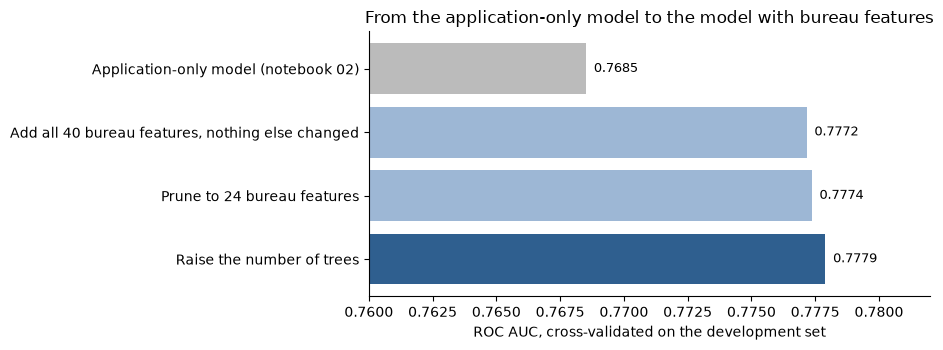

In [43]:
steps = [
    ('Application-only model (notebook 02)', 36, N_TREES, baseline, 2),
    ('Add all 40 bureau features, nothing else changed', 76, N_TREES, with_bureau, 3),
    ('Prune to 24 bureau features', len(CHOSEN_FEATURES), N_TREES, chosen, 5),
    ('Raise the number of trees', len(CHOSEN_FEATURES), FINAL_TREES, final_run, 6),
]
ladder = pd.DataFrame({label: {'stage': stage, 'features': n, 'trees': trees, 'roc_auc': r['mean']['roc_auc'], 'pr_auc': r['mean']['pr_auc'],
                               'gain_over_application_only': compare(r, baseline)['mean_difference'], 'folds_better': compare(r, baseline)['folds_better'] if r is not baseline else 0}
                       for label, n, trees, r, stage in steps}).T
ladder['step'] = ladder['roc_auc'].astype(float).diff()
print('cross-validated on the development set, the same five folds throughout:')
print(ladder.astype({'stage': int, 'features': int, 'trees': int, 'folds_better': int}).to_string(float_format=lambda v: f'{v:.5f}', na_rep=''))

calibrated_summary = pd.DataFrame({'application only': baseline_cal['mean'], 'with bureau': final_cal['mean']}).loc[['roc_auc', 'pr_auc', 'log_loss', 'brier']]
calibrated_summary['change'] = calibrated_summary['with bureau'] - calibrated_summary['application only']
print('\nafter calibration:')
print(calibrated_summary.to_string(float_format=lambda v: f'{v:.5f}'))
print(f"\ngain from the bureau features with both models on the same number of trees: {like_for_like['mean_difference']:+.5f} at {FINAL_TREES:,} trees, {compare(chosen, baseline)['mean_difference']:+.5f} at {N_TREES:,}")
print(f"seed noise floor: {NOISE_FLOOR:.4f}; 95% interval for the stage 3 gain from resampling applicants: {np.quantile(boot_gain, 0.025):+.4f} to {np.quantile(boot_gain, 0.975):+.4f}")
print(f"cost per 1,000 applicants at the reference threshold: {ref_old['cost_per_1000_applicants']:.1f} -> {ref_new['cost_per_1000_applicants']:.1f}")

evidence = pd.DataFrame({
    'application only': {'cross-validation': APP_ONLY['cv'], 'holdout (opened once, notebook 02)': 0.7715, 'Kaggle public': APP_ONLY['public'], 'Kaggle private': APP_ONLY['private']},
    'with bureau': {'cross-validation': CV_MAIN, 'holdout (opened once, notebook 02)': np.nan,
                    'Kaggle public': KAGGLE_SCORES['submission_with_bureau.csv']['public'] if KAGGLE_ENTERED else np.nan,
                    'Kaggle private': KAGGLE_SCORES['submission_with_bureau.csv']['private'] if KAGGLE_ENTERED else np.nan},
})
print('\nROC AUC by kind of evidence:')
print(evidence.to_string(float_format=lambda v: f'{v:.4f}', na_rep='not measured'))
print(f"Kaggle scores for the model with bureau features: {'entered in section 9.6' if KAGGLE_ENTERED else 'NOT YET ENTERED (section 9.6)'}")

# the figures quoted in the conclusions
assert round(float(baseline['mean']['roc_auc']), 4) == 0.7685 and round(CV_MAIN, 4) == 0.7779 and len(CHOSEN_FEATURES) == 60 and len(KEPT_BUREAU) == 24 and FINAL_TREES == 3500
assert round(float(final_cal['mean']['log_loss']), 4) == 0.2403 and round(like_for_like['mean_difference'], 4) == 0.0092
assert not any(name in globals() for name in ['X_all', 'y_all']), 'the full training table should not be in memory'

fig, ax = plt.subplots(figsize=(9.5, 3.6))
labels = list(ladder.index)[::-1]
values = ladder['roc_auc'].astype(float)[::-1]
ax.barh(labels, values, color=['#2f5f8f'] + ['#9db7d5'] * (len(labels) - 2) + ['#bbbbbb'])
for i, v in enumerate(values):
    ax.text(v + 0.0003, i, f'{v:.4f}', va='center', fontsize=9)
ax.set_xlim(0.760, 0.782); ax.set_xlabel('ROC AUC, cross-validated on the development set'); ax.set_title('From the application-only model to the model with bureau features')
sns.despine(); plt.tight_layout(); plt.show()

### Conclusions

**The answer.** Yes. The credit bureau table improves the model, clearly and by more than expected.

| | Application only | With bureau | Change |
|---|---:|---:|---:|
| ROC AUC, cross-validated | 0.7685 | 0.7779 | +0.0094 |
| PR AUC | 0.2539 | 0.2654 | +0.0115 |
| Log loss | 0.2432 | 0.2403 | -0.0029 |
| Defaults caught at the reference threshold | 65.4% | 66.7% | +1.3 points |
| Good applicants declined | 25.8% | 25.5% | -0.3 points |
| Cost per 1,000 applicants, ratio 10 | 516 | 503 | -2.6% |
| Kaggle private score | 0.7638 | 0.7753 | +0.0115 |

- With both models on the same number of trees, the bureau table itself is worth **0.0092**. The remaining 0.0002 comes from more trees.
- The four conditions fixed in advance were met when the bureau features were first added, with nothing tuned to them: higher on average, higher in every fold, 25 times its standard error, and 17 times the noise a change of seed produces. The final model meets them too.
- For scale, fifty trials of hyperparameter tuning in notebook 02 were worth 0.0071.
- **Kaggle confirms it.** On the private test set, a different population whose labels nobody in this project has seen, the gain is 0.0115, a little more than cross-validation predicted. All three expectations written down before the upload were met.

**The model**

| | |
|---|---|
| Inputs | 60 features: the 36 application features of notebook 02, and 24 of the 40 bureau features of notebook 03 |
| Settings | Unchanged from notebook 02. A second search of 30 trials found nothing better |
| Trees | 3,500 at a learning rate of 0.02, up from 2,365 |
| Output | A calibrated probability, by the same Platt scaling |
| Decision rule | Unchanged: decline at 0.0909 or above |
| Saved as | `artifacts/model_with_bureau/`, loaded by the same `src/models/scoring.py` |

**Where the gain comes from**
- **Debt.** The features on how much is owed give 70% of the gain alone, and cost three times as much to remove as any other family.
- **Many small things.** No bureau feature is among the model's 17 most important. The family carries 23% of the model's total contribution through 24 modest features.
- **Applicants the old model misjudged.** It gave microloan holders 13.7% when 19.9% default, and applicants with a mortgage on record 6.5% when 5.2% do. The new model gives 19.6% and 5.4%.
- **Not** from knowing how many credits an applicant has (worth 0.0001), and not from the recency features that looked strongest alone in notebook 03. The external scores already held those.

**What I got wrong**
- **The size of the gain.** Notebooks 03 and 04 both predicted "a real but modest gain". It was larger than tuning. The prediction came from scoring one feature at a time against a fixed model, which cannot see features working together.
- **Ranking rare-event features by average contribution.** The ranking put the microloan, overdue-now and sold-debt counts near the bottom. Added back, those four were worth more than the sixteen features correctly removed. This was the third time the project met the same fact, and the pruning rule still had to be caught by a separate test.
- **Debt against income.** Suggested in notebook 03, tested here, and it made the model slightly worse.
- **A fold-balance check in stage 1** that failed because my threshold ignored how few applicants have some features.
- **A status message during stage 6** reported the run as dead when the computer had only been asleep.

**How leakage was controlled**

| Risk | Control | What was measured |
|---|---|---|
| A difference in code, not in features | Shared module, compared with notebook 02's source on every run | The baseline reproduced notebook 02's predictions exactly, for all 246,008 applicants |
| A gain from more columns, not more information | Bureau features scrambled between applicants | The scrambled columns made the model worse by 0.0020 |
| A gain from seed noise | Four other seeds of the baseline; the gain repeated on three seeds | Noise floor 0.0005; gain 0.0087 on every seed |
| Feature selection on the scored rows | Selection inside the pipeline, on training folds | Fixing one list flatters the score by 0.0001 |
| Early stopping and calibration on the scored rows | Both nested inside the training folds | |
| The holdout | Never loaded. Its applicants appear only as training rows in the final refit | |
| The test file | No labels. Passed through finished models only | |
| Tuning on the test set | The diagnostic model is not a candidate, whatever its Kaggle score | |

**What is still uncertain**
- **The holdout has not been opened for this model.** Every figure above is cross-validated on the development set. The application-only model's cross-validated score was confirmed by the holdout (0.7685 against 0.7715) and by Kaggle (0.7638), which is the reason to trust the method. It is not a measurement of this model.
- **Kaggle has now tested it once.** The private score of 0.7753 is 0.0026 below cross-validation, a smaller drop than the application-only model's 0.0047. That is direct evidence that the cross-validated gain is real and not an artefact of choices made on the development folds. It is one test on one population.
- **Choices made on the development folds add up.** Notebook 03 fixed a threshold, added a feature and dropped two using development outcomes. This notebook chose a list size, a fixed list, four features to add back, and a number of trees. Each was done by a rule or a test set in advance, and the one effect that could be measured was 0.0001. The Kaggle result puts a ceiling on the total: had these choices inflated the cross-validated gain much, the gain on the test file would have fallen short of it, and it did not. The holdout, opened once at the end, remains the formal check.

**Limits**
- **Applicants with no bureau record are very slightly worse served.** For these 14% the bureau features are all missing, and the extra columns crowd out the application features the model needs for them. Against an application-only model with the same number of trees they lose 0.0013 of ROC AUC within their group. They are also approved at 0.81 times the rate of applicants with a record, down from 0.84, because those with a record can now show a good one.
- **The external scores are still the largest influence.** They are the main reason for 63% of declines, down from 71%. A lender can now often name a bureau fact as well, but the score itself remains unexplained.
- **The monthly repayment record is not used.** `bureau_balance` and `AMT_ANNUITY` were left out in notebook 03 because they are supplied on different terms in train and test. Published solutions to this competition used them, so the bureau table is worth less here than it was for them.
- **Microloans are twice as common in the test file.** The model leans on them for a small group. The second submission tested whether that holds up there, and it does: the features are worth 0.0016 on the private test set.
- **Gender and age.** The gaps found in notebook 02 are unchanged, and the policy question is still open.
- **The model is slower.** 59 seconds a fold against 22.

**What to do next**
1. **Add the next history table by the same method.** `previous_application` and `installments_payments` hold the applicant's record with Home Credit itself, including whether instalments were paid on time, which is the kind of information `bureau_balance` would have given. The method is now established: audit whether each column is supplied on the same terms in train and test, build features from each applicant's own rows, verify them independently, and measure the gain on the frozen folds against a baseline reproduced exactly.
2. **Open the holdout once, at the end,** for the model that includes every table.
3. **Consider routing applicants with no bureau record to the application-only model.** It would remove the small loss they take. It is a design change, and it should be tested on the folds like any other.
4. **Move the application features' code out of notebook 01,** so that the model can score a raw application and its bureau history without any notebook.